# Bark Classification — Swin-T × 3 Seeds (42, 123, 2026) · 15 classes

ต่อยอดจาก `Bark_Extract_new.ipynb` (15 class เหมือนเดิม) — **เปลี่ยนเฉพาะ seed ของการเทรน** แล้วเก็บผลเพิ่มสำหรับรายงานแบบหลาย seed

**Workflow:** `0 Setup → ตั้งค่า → 1 ตรวจ Dataset → 2 Split (ชุดเดิม) → 3 Preprocess → 4 Train+Test × 3 seeds → 5 ผลราย seed + Mean ± SD → 6 CSV ผลทำนาย 795 ภาพ → 7 McNemar's test → 8 Hyperparameters → 9 Output (CSV/Excel/zip) → 10 ภาพตัวอย่าง`

| | เดิม (`Bark_Extract_new`) | Notebook นี้ |
|---|---|---|
| โมเดล | Swin-T, DeiT-S | **Swin-T** (เพิ่มโมเดลอื่นได้ใน cell ตั้งค่า) |
| Seed | 42 | **42, 123, 2026** (วนอัตโนมัติ) |
| Split train/valid | seed 42 | **seed 42 เหมือนเดิม (คงที่)** — ทุก seed ใช้ข้อมูลชุดเดียวกัน |
| Test set | 795 ภาพ | **795 ภาพชุดเดิม** (ใช้ประเมินเท่านั้น ไม่ใช้เลือกโมเดล) |
| ค่าที่เก็บ | Acc, Macro-F1, AUC, MCC, CM, report | เดิมทั้งหมด **ต่อ seed** + Mean ± SD + CSV ผลทำนายรายภาพ + McNemar |

**วิธีรัน:** Runtime > Change runtime type > **T4 GPU** → Runtime > **Run all**
ถ้า Colab หลุดกลางทาง ให้ Run all ใหม่ได้เลย — seed ที่ทำเสร็จแล้ว (บันทึกขึ้น Drive) จะถูกข้าม ไม่เทรนซ้ำ

> **Notebook นี้รันเฉพาะ Swin-T** — อีกโมเดลอยู่ใน notebook แยก ทั้งสองบันทึกผลไว้ที่ `MyDrive/Bark_results_multiseed` เดียวกัน: notebook ที่รันทีหลังจะโหลดผลของอีกโมเดลมาอัตโนมัติ แล้วคำนวณ Mean ± SD ทั้ง 2 โมเดล, McNemar (Swin-T vs DeiT-S) และ Excel ให้ครบ (ไม่เทรนโมเดลอีกตัวซ้ำ)

## ไฟล์และข้อมูลที่ต้องมีก่อนรัน

**บน Google Drive: `MyDrive/Bark_Archive_All/`** — notebook หาโฟลเดอร์ให้เองโดยไม่สนตัวพิมพ์เล็ก/ใหญ่ (ถ้าไม่พบใน `Bark_Archive_All` จะหาใน `MyDrive` ต่อ)

| โฟลเดอร์ | ต้องมีอะไร | ใช้ทำ |
|---|---|---|
| `Bark_Archive_All/Bark_runModel/` | 15 โฟลเดอร์ย่อย ชื่อตรงกับ `CLASS_NAMES`, **300 ภาพต่อ class** (รวม 4,500) | train 247 / valid 53 ต่อ class |
| `Bark_Archive_All/Bark_Test_53_Final/` | 15 โฟลเดอร์ย่อย ชื่อเดียวกัน, **53 ภาพต่อ class** (รวม **795**) | test |

ชื่อ class 15 ตัว (= ชื่อโฟลเดอร์): Alstonia scholaris, Cassia fistula, Delonix regia, Dipterocarpus alatus Roxb, **Lagerstroemia duperreana**, Lagerstroemia loudonii, Lagerstroemia macrocarpa, Peltophorum dasyrhachis, Peltophorum pterocarpum, Pterocarpus indicus, Pterocarpus macrocarpus, Streblus asper, Swietenia macrophylla, Tectona grandis, Triplaris cumingiana Fisch

โครงสร้างซ้อนจากการแตก zip (`Bark_runModel/Bark_runModel/<class>`) หรือไฟล์ `.zip` ที่ยังไม่แตก ใช้ได้ — notebook จัดการให้ ถ้าชื่อโฟลเดอร์/จำนวนภาพไม่ตรง notebook จะหยุดที่ STEP 1 และบอกว่าขาดอะไร

*(ไม่บังคับ)* `MyDrive/Bark_results/split_manifest.csv` จากการรันเดิม — ถ้ามี จะใช้ยืนยันว่า split/test ตรงกับของเดิม (เทียบด้วย MD5 ของภาพ)

**อื่น ๆ:** Colab GPU (T4 ขึ้นไป), อินเทอร์เน็ตสำหรับโหลด pretrained weights จาก Hugging Face (timm), พื้นที่ `/content` ~10 GB
ไลบรารี: `torch, timm, scikit-learn, scipy, pandas, matplotlib, openpyxl` (Colab มีให้แล้ว ยกเว้น timm ซึ่ง cell แรกติดตั้งให้)

**ไม่ต้องใช้:** `bark_dataset_prep.ipynb` (ใช้สร้าง patch ซึ่งอยู่ใน `Bark_runModel` แล้ว) และ `Bark_Extract_new.ipynb` (notebook นี้แทนที่)

**ผลลัพธ์:** เก็บที่ `/content/Bark_results_multiseed` → zip ให้ดาวน์โหลด + คัดลอกขึ้น `MyDrive/Bark_results_multiseed` (ไม่รวม checkpoint .pth เพราะ Drive เต็ม — เปิดได้ใน cell ตั้งค่า)

## 0. Setup
ติดตั้ง/นำเข้าไลบรารี, mount Google Drive, ตรวจ GPU

In [ ]:
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')   # ให้ผลบน GPU ซ้ำได้มากที่สุด

import sys, subprocess
try:
    import timm
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'timm'], check=True)
    import timm

import re, json, time, math, shutil, hashlib, random, platform, datetime, itertools, unicodedata, difflib
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
import matplotlib
import matplotlib.ticker
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             roc_auc_score, matthews_corrcoef, confusion_matrix,
                             classification_report)
from scipy.stats import binomtest, chi2 as chi2_dist
from IPython.display import display
try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x, **k: x

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 50)

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type == 'cuda':
    GPU_NAME = torch.cuda.get_device_name(0)
    GPU_MEM_GB = round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1)
    # bf16 เฉพาะ GPU รุ่น Ampere ขึ้นไป (A100/L4); T4 ใช้ fp16
    AMP_DTYPE = torch.bfloat16 if torch.cuda.get_device_capability(0)[0] >= 8 else torch.float16
else:
    GPU_NAME, GPU_MEM_GB, AMP_DTYPE = 'CPU (no GPU)', 0, torch.float32

print(f'Python  : {platform.python_version()}')
print(f'PyTorch : {torch.__version__}')
print(f'timm    : {timm.__version__}')
print(f'Device  : {GPU_NAME}' + (f' ({GPU_MEM_GB} GB)' if GPU_MEM_GB else ''))
print(f'CPU     : {os.cpu_count()} cores')

Mounted at /content/drive
Python  : 3.13.16
PyTorch : 2.11.0+cu130
timm    : 1.0.30
Device  : Tesla T4 (14.6 GB)
CPU     : 2 cores


## ตั้งค่า
แก้เฉพาะ cell นี้ — hyperparameter **เหมือนการรันเดิมทุกค่า** และใช้ค่าเดียวกันทุก seed
- `SPLIT_SEED = 42` ใช้แบ่ง train/valid → **คงที่** เพื่อให้ทุก seed ใช้ข้อมูลชุดเดิม
- `SEEDS` คือ seed ของการเทรน (การสุ่มค่าเริ่มต้นของ head, ลำดับ batch, drop-path) → ความต่างระหว่าง seed สะท้อนความแปรปรวนของการเทรนเท่านั้น
- เพิ่มโมเดลภายหลัง: เติมใน `MODELS` แล้ว Run all — ผลของ Swin-T ที่ทำไว้แล้วจะถูกโหลดจาก Drive ไม่เทรนซ้ำ และ McNemar ระหว่างโมเดลจะคำนวณให้อัตโนมัติ
- **`SWIN_FIXED_EPOCHS = True`** (ทดลองเพิ่ม): เทรน Swin-T อีกชุดชื่อ `Swin-T-E20` — hyperparameter เดิมทุกค่า แต่ไม่ใช้ early stopping และใช้โมเดล **epoch สุดท้าย (20)** ทุก seed แทนการเลือกจาก validation (ซึ่งได้ 1.0 ทุก epoch จึงเลือกไม่ได้จริง) ผล Swin-T เดิมไม่ถูกลบ — ตาราง/McNemar/Excel จะแสดงทั้ง `Swin-T` และ `Swin-T-E20` **ผลออกมาอย่างไรต้องรายงานตามจริง ห้ามเลือกเฉพาะแบบที่ดูดีกว่า** และถ้าใช้แบบ E20 เป็นผลหลัก ควรใช้เกณฑ์เดียวกันกับ DeiT-S ด้วยเพื่อความยุติธรรม

In [ ]:
# ---------- ตำแหน่งไฟล์บน Google Drive (ไม่สนตัวพิมพ์เล็ก/ใหญ่) ----------
DRIVE_ROOT = Path('/content/drive/MyDrive')
DATA_ROOT  = DRIVE_ROOT / 'Bark_Archive_All'   # โฟลเดอร์ที่เก็บ dataset ทั้ง 2 ชุด (ถ้าไม่พบ จะหาใน MyDrive แทน)

SOURCE_DIR_NAME = 'Bark_runModel'        # train+valid: 15 โฟลเดอร์ (ชื่อ class) x 300 ภาพ
TEST_DIR_NAME   = 'Bark_Test_53_Final'   # test:        15 โฟลเดอร์ (ชื่อ class) x 53 ภาพ = 795

# train+valid: หาทั้ง MyDrive/Bark_runmodel (ชุดที่ใช้รันรอบเดิม) และ Bark_Archive_All/Bark_runModel
# แล้วใช้ชุดแรกที่มีภาพครบ 15 x 300 (ชุดที่ไม่ครบจะถูกข้ามอัตโนมัติ)
SOURCE_DIR_NAMES    = [SOURCE_DIR_NAME, 'Bark_runmodel']   # ไม่สนตัวพิมพ์เล็ก/ใหญ่
SOURCE_SEARCH_BASES = [DRIVE_ROOT, DATA_ROOT]             # MyDrive ก่อน แล้วค่อย Bark_Archive_All
TEST_SEARCH_BASES   = [DATA_ROOT, DRIVE_ROOT]
# ถ้าแตก zip แล้วได้โฟลเดอร์ซ้อน (เช่น Bark_runModel/Bark_runModel/<class>) notebook จะเข้าไปชั้นในให้เอง
# ถ้าบน Drive เป็นไฟล์ .zip (ยังไม่แตก) notebook จะแตกไฟล์ลง /content ให้เอง

WORK_DIR          = Path('/content')
LOCAL_SOURCE      = WORK_DIR / 'Bark_runmodel_local'       # สำเนาในเครื่อง Colab (อ่านเร็วกว่า Drive)
DATASET_DIR       = WORK_DIR / 'Bark_dataset'              # train / valid / test
RESULTS_DIR       = WORK_DIR / 'Bark_results_multiseed'    # ผลลัพธ์ทั้งหมด
DRIVE_RESULTS_DIR = DRIVE_ROOT / 'Bark_results_multiseed'  # คัดลอกผลขึ้น Drive (None = ไม่คัดลอก)
REFERENCE_SPLIT_MANIFEST = DRIVE_ROOT / 'Bark_results' / 'split_manifest.csv'   # (ไม่บังคับ) ผล split ของการรันเดิม

# ---------- Classes (ลำดับนี้ = label index 0..14) ----------
CLASS_NAMES = [
    'Alstonia scholaris',
    'Cassia fistula',
    'Delonix regia',
    'Dipterocarpus alatus Roxb',
    'Lagerstroemia duperreana',
    'Lagerstroemia loudonii',
    'Lagerstroemia macrocarpa',
    'Peltophorum dasyrhachis',
    'Peltophorum pterocarpum',
    'Pterocarpus indicus',
    'Pterocarpus macrocarpus',
    'Streblus asper',
    'Swietenia macrophylla',
    'Tectona grandis',
    'Triplaris cumingiana Fisch',
]
NUM_CLASSES              = len(CLASS_NAMES)   # = 15
EXPECTED_PER_CLASS       = 300                # ภาพต่อ class ใน Bark_runModel (train+valid)
EXPECTED_PER_TEST_FOLDER = 53                 # ภาพต่อโฟลเดอร์ test
EXPECTED_TEST_TOTAL      = NUM_CLASSES * EXPECTED_PER_TEST_FOLDER   # = 795
IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}
# ชื่อโฟลเดอร์อื่นที่ยอมรับเป็น class เดียวกัน (ชุดเดิมใช้ชื่อ calyculata = พันธุ์เดียวกับ duperreana)
CLASS_FOLDER_ALIASES = {
    'Alstonia scholaris':        ['SP15_Alstonia scholaris'],
    'Cassia fistula':            ['SP13_Cassia fistula'],
    'Delonix regia':             ['SP14_Delonix regia'],
    'Dipterocarpus alatus Roxb': ['SP01_Dipterocarpus_alatus'],
    'Lagerstroemia duperreana':  ['Lagerstroemia calyculata', 'SP03_Lagerstroemia_calyculata'],
    'Lagerstroemia loudonii':    ['SP11_Lagerstroemia loudonii'],
    'Lagerstroemia macrocarpa':  ['SP07_Lagerstroemia_macrocarpa'],
    'Peltophorum dasyrhachis':   ['SP12_Peltophorum dasyrhachis'],
    'Peltophorum pterocarpum':   ['SP06_Peltophorum_pterocarpum'],
    'Pterocarpus indicus':       ['SP10_Pterocarpus indicus'],
    'Pterocarpus macrocarpus':   ['SP04_Pterocarpus_macrocarpus'],
    'Streblus asper':            ['SP08_Streblus asper'],
    'Swietenia macrophylla':     ['SP09_Swietenia macrophylla'],
    'Tectona grandis':           ['SP07_Tectona grandis'],
    'Triplaris cumingiana Fisch':['SP05_Triplaris_cumingiana'],
}

# ---------- Split (คงที่ = ชุดเดิม) ----------
SPLIT_SEED = 42
N_TRAIN, N_VAL = 247, 53
assert N_TRAIN + N_VAL == EXPECTED_PER_CLASS
SPLIT_BY_GROUP = True
GROUP_SUFFIX_PATTERNS = [
    r'_x\d+_y\d+',              # พิกัด patch
    r'_(rot|r|rotate)180',      # patch ที่หมุน 180 องศา
    r'_zoom[\d.]*',             # patch ที่ซูม
]

# ---------- Seeds ของการเทรน ----------
SEEDS = [42, 123, 2026]

# ---------- Models (pretrained ImageNet-1k จาก timm) ----------
MODELS = {
    'Swin-T': 'swin_tiny_patch4_window7_224.ms_in1k',
    # 'DeiT-S': 'deit_small_patch16_224.fb_in1k',   # <- อยู่ใน notebook ของ DeiT-S (ผลรวมกันบน Drive อัตโนมัติ)
    # 'EfficientNetV2-S': 'tf_efficientnetv2_s.in1k',   # = Keras EfficientNetV2S weights='imagenet' (port จาก TF ทางการ)
    # 'ResNet' / 'ConvNeXt': เติมชื่อ timm ของรุ่นที่ใช้ในงานวิจัย
}
ARCH_ORDER = ['ResNet', 'EfficientNet', 'EfficientNetV2-S', 'ConvNeXt', 'Swin-T', 'DeiT-S']   # ลำดับในตารางสรุป

# ---------- Hyperparameters (ปรับเพื่อลด overfitting: batch_size=32 และ max_epochs=20 เท่าเดิม) ----------
HP = dict(
    batch_size          = 32,
    max_epochs          = 20,
    early_stop_patience = 10,       # หยุดถ้า val macro-F1 ไม่ดีขึ้น 10 epoch ติด
    optimizer           = 'AdamW',
    lr_backbone         = 2e-5,       # เดิม 5e-5 -> ลดเพื่อไม่ให้ backbone ขยับห่างจาก pretrained มากเกินไป
    lr_head             = 1e-3,
    weight_decay        = 0.1,        # เดิม 0.05
    warmup_epochs       = 3,
    min_lr_ratio        = 0.01,
    label_smoothing     = 0.2,        # เดิม 0.1
    drop_path_rate      = 0.3,        # เดิม 0.1 (stochastic depth)
    drop_rate           = 0.3,        # ใหม่: dropout ก่อน head (เดิม 0.0) — build_model รับค่านี้อยู่แล้ว ไม่ต้องแก้โค้ดอื่น
    grad_clip_norm      = 1.0,
    amp                 = True,
)

# ---------- ค่าเฉพาะโมเดล (ทับค่าใน HP เฉพาะโมเดลนั้น) ----------
# EfficientNetV2-S: 'original' = ตั้งค่าเหมือน efficentnetv2.ipynb เดิม (Keras) — ปรับแค่ seed ตามที่กำหนด
#   freeze backbone ทั้งหมด (เทรนเฉพาะ Dense 15 class), Adam lr 1e-3 คงที่, batch 16, 20 epochs,
#   categorical cross-entropy (ไม่มี label smoothing), dropout 0.2, input 224 -> ขยายเป็น 384 ในโมเดล, ใช้โมเดล epoch สุดท้าย
# 'same_as_transformers' = full fine-tuning ด้วย HP ชุดเดียวกับ Swin-T / DeiT-S (เปรียบเทียบแบบตั้งค่าเท่ากัน)
EFFNET_MODE = 'original'
MODEL_HP, MODEL_PREP = {}, {}
if EFFNET_MODE == 'original':
    MODEL_HP['EfficientNetV2-S'] = dict(
        batch_size=16, max_epochs=20, early_stop_patience=10**6, optimizer='Adam',
        lr_backbone=0.0, lr_head=1e-3, weight_decay=0.0, warmup_epochs=0, min_lr_ratio=1.0,
        label_smoothing=0.0, drop_path_rate=0.2, drop_rate=0.2, grad_clip_norm=None,
        freeze_backbone=True, model_selection='last_epoch')
    MODEL_PREP['EfficientNetV2-S'] = dict(size=(224, 224), interpolation='bilinear', upsample_to=384)

# Swin-T แบบเทรนครบ 20 epochs แล้วใช้ epoch สุดท้าย (ทดลองเพิ่ม) — เก็บผลแยกชื่อ 'Swin-T-E20' ผลเดิมของ Swin-T ไม่ถูกลบ/ทับ
#   เหตุผล: validation macro-F1 = 1.0 ตั้งแต่ epoch แรก ๆ จึงเลือก best epoch จาก validation ไม่ได้จริง (Swin-T เดิมได้ epoch 18 / 7 / 7)
#   แบบนี้ทุก seed ใช้เกณฑ์เดียวกัน (epoch 20) ไม่ขึ้นกับ validation — hyperparameter อื่นเหมือนเดิมทุกค่า
SWIN_FIXED_EPOCHS = True     # True = เทรน Swin-T-E20 เพิ่ม 3 seeds (~25 นาที) | False = ไม่เทรน
MODEL_HP['Swin-T-E20'] = dict(early_stop_patience=10**6, model_selection='last_epoch')   # นิยามไว้เสมอ เพื่อให้ทุก notebook อ่านผลชุดนี้ได้
ARCH_ORDER.insert(ARCH_ORDER.index('Swin-T') + 1, 'Swin-T-E20')
if SWIN_FIXED_EPOCHS:
    MODELS['Swin-T-E20'] = 'swin_tiny_patch4_window7_224.ms_in1k'

def hp_of(tag):
    """hyperparameter ที่ใช้จริงของโมเดลนี้ = HP กลาง + ค่าเฉพาะโมเดล"""
    return {**HP, **MODEL_HP.get(tag, {})}
ALLOW_CPU = False   # ถ้าไม่มี GPU จะหยุด เพราะเทรนบน CPU ช้ามาก

# ---------- Resume / การบันทึก ----------
RESUME_FROM_DRIVE         = True    # seed ที่มีผลครบบน Drive แล้ว -> โหลดมาใช้ ไม่เทรนซ้ำ
FORCE_RETRAIN             = False   # True = เทรนใหม่ทุก seed (ทับผลเดิม)
SAVE_CHECKPOINTS_TO_DRIVE = False   # .pth ~105 MB ต่อ seed (Drive เต็ม จึงปิดไว้)
ZIP_INCLUDE_CHECKPOINTS   = False   # รวม .pth ใน zip ดาวน์โหลดหรือไม่

# ---------- McNemar's test ----------
MCNEMAR_ALPHA         = 0.05
MCNEMAR_EXACT_BELOW   = 25      # b + c < 25 -> ใช้ exact binomial, ไม่งั้นใช้ chi-square (continuity correction)
MCNEMAR_BETWEEN_SEEDS = True    # (เสริม) เทียบ seed ต่าง ๆ ของโมเดลเดียวกันด้วย

# ---------- รันซ้ำ seed เดิม (ตรวจความคงที่ของผล) — เก็บแยกใน reruns/ ไม่ทับผลหลัก ----------
RERUNS   = [('Swin-T', 123)]   # (โมเดล, seed) ที่ต้องการรันซ้ำ; [] = ไม่รันซ้ำ
RERUN_ID = 'rerun1'            # ชื่อรอบรันซ้ำ (เปลี่ยนเป็น rerun2 ถ้าจะรันซ้ำอีกครั้ง)

# ---------- ข้อมูลการเตรียมภาพ (จาก bark_dataset_prep.ipynb) — ใช้ในตารางรายงานเท่านั้น ไม่กระทบการเทรน ----------
DATA_PREP_INFO = {
    'Original photo size (before patching)':
        '1108 × 1477 px (ภาพส่วนใหญ่) และ 960 × 1280 px (ซูม ×1.042 ก่อนตัด patch) — ค่าจาก bark_dataset_prep (7 พันธุ์เดิม); '
        'พันธุ์ที่เพิ่มภายหลังให้ยืนยันกับเจ้าของข้อมูล',
    'Patch size (dataset)': '1000 × 1000 px (crop จากภาพต้นฉบับ ไม่ resize ไม่ปรับสี, PNG lossless)',
    'Dense patch extraction': 'Sliding window 1000 × 1000 px, stride 750 px (overlap 25%) + patch ชิดขอบเมื่อได้เนื้อใหม่ ≥ 250 px '
                              '(ภาพ 1108 × 1477 ได้ 2 patch บน/ล่าง, overlap จริง 52%)',
    'Offline augmentation (dataset prep)': 'หมุน 180° เฉพาะพันธุ์ที่ patch ไม่ถึง 300 (ทำตอนเตรียมข้อมูล ก่อนแบ่ง split; '
                                           'patch ที่หมุนอยู่กลุ่มเดียวกับต้นฉบับ)',
}

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
(RESULTS_DIR / 'checkpoints').mkdir(exist_ok=True)
(RESULTS_DIR / 'runs').mkdir(exist_ok=True)
RUN_VARIANT = ''    # '' = ผลหลัก (runs/) ; ไม่ต้องแก้ — STEP 4b ตั้งค่าให้เองตอนรันซ้ำ
print('ตั้งค่าเรียบร้อย')
print(f'  Models     : {list(MODELS)}')
print(f'  Seeds      : {SEEDS}  (split seed คงที่ = {SPLIT_SEED})')
print(f'  Classes    : {NUM_CLASSES}  | test ที่ต้องมี {EXPECTED_TEST_TOTAL} ภาพ')
print(f'  Results    : {RESULTS_DIR}')
print(f'  Drive copy : {DRIVE_RESULTS_DIR}')

ตั้งค่าเรียบร้อย
  Models     : ['Swin-T', 'Swin-T-E20']
  Seeds      : [42, 123, 2026]  (split seed คงที่ = 42)
  Classes    : 15  | test ที่ต้องมี 795 ภาพ
  Results    : /content/Bark_results_multiseed
  Drive copy : /content/drive/MyDrive/Bark_results_multiseed


## STEP 1: ตรวจสอบ Dataset
- หาโฟลเดอร์บน Drive (ไม่สนตัวพิมพ์เล็ก/ใหญ่)
- `Bark_runModel` ต้องมีครบ 15 โฟลเดอร์ตามชื่อ class และแต่ละ class ต้องมี **exactly 300** ภาพ

In [ ]:
def _norm(s):
    return ' '.join(unicodedata.normalize('NFC', s).split()).casefold()

def is_image(p):
    return p.is_file() and not p.name.startswith('.') and p.suffix.lower() in IMG_EXTS

def find_dir(name, base=None):
    """หาโฟลเดอร์ (หรือ <name>.zip) ใน MyDrive ชั้นบนสุดก่อน แล้วชั้นถัดไป โดยไม่สนตัวพิมพ์เล็ก/ใหญ่"""
    base = base or DRIVE_ROOT
    if (base / name).is_dir():
        return base / name
    keys, level = {_norm(name), _norm(name + '.zip')}, [base]
    for depth in range(2):
        hits, nxt = [], []
        for d in level:
            try:
                kids = [c for c in d.iterdir() if not c.name.startswith('.')]
            except OSError:
                continue
            hits += [c for c in kids if _norm(c.name) in keys and (c.is_dir() or c.suffix.lower() == '.zip')]
            nxt += [c for c in kids if c.is_dir()]
        dirs = [h for h in hits if h.is_dir()]
        hits = dirs or hits                       # มีทั้งโฟลเดอร์และ zip -> ใช้โฟลเดอร์
        if len(hits) == 1:
            print(f'[INFO] {name} -> พบที่ {hits[0]}')
            return hits[0]
        if len(hits) > 1:
            raise FileNotFoundError(f'พบ "{name}" หลายที่: {hits} — ระบุ path ให้ชัดใน cell ตั้งค่า')
        level = nxt if depth == 0 else []
    top = [p.name for p in base.iterdir()] if base.is_dir() else []
    close = difflib.get_close_matches(name, top, n=3, cutoff=0.5)
    raise FileNotFoundError(f'ไม่พบโฟลเดอร์ "{name}" ใน {base}'
                            + (f'\nชื่อใกล้เคียงที่พบ: {close}' if close else '')
                            + '\nกรุณาแก้ชื่อใน cell ตั้งค่า')

def class_root(p):
    """ถ้าเป็น .zip -> แตกลง /content ; ถ้าเป็นโฟลเดอร์ซ้อน (X/X/<class>) -> เข้าไปชั้นที่มีโฟลเดอร์ class"""
    if p.is_file() and p.suffix.lower() == '.zip':
        out = WORK_DIR / 'unzipped' / p.stem
        if not out.is_dir():
            print(f'[INFO] แตกไฟล์ {p.name} -> {out} ...')
            shutil.unpack_archive(str(p), str(out))
        p = out
    want = {_norm(c) for c in CLASS_NAMES}
    for _ in range(4):
        subs = [d for d in p.iterdir() if d.is_dir() and not d.name.startswith(('.', '__MACOSX'))]
        if {_norm(d.name) for d in subs} & want or len(subs) != 1:
            return p
        print(f'[INFO] โฟลเดอร์ซ้อน: ใช้ {subs[0]}')
        p = subs[0]
    return p

def check_class_folders(root, expected, title):
    """ตรวจว่ามี 15 โฟลเดอร์ชื่อตรงกับ CLASS_NAMES และมีภาพครบตามจำนวน คืน (ตาราง, errors, {class: dir})"""
    dirs = {d.name: d for d in root.iterdir() if d.is_dir() and not d.name.startswith(('.', '__MACOSX'))}
    by_norm = {_norm(n): d for n, d in dirs.items()}
    rows, errs, warns, cls_dir = [], [], [], {}
    for i, c in enumerate(CLASS_NAMES):
        d = dirs.get(c) or by_norm.get(_norm(c)) or next(
            (by_norm[_norm(a)] for a in CLASS_FOLDER_ALIASES.get(c, []) if _norm(a) in by_norm), None)
        if d is None:
            close = difflib.get_close_matches(c, list(dirs), n=1, cutoff=0.6)
            rows.append({'label': i, 'class': c, 'images': 0, 'status': 'FAIL - ไม่พบโฟลเดอร์'})
            errs.append(f'[{title}] ไม่พบโฟลเดอร์ "{c}"' + (f' (ชื่อใกล้เคียง: "{close[0]}")' if close else ''))
            continue
        if d.name != c:
            warns.append(f'[{title}] ใช้โฟลเดอร์ "{d.name}" สำหรับ class "{c}" (ผลลัพธ์ทุกไฟล์ใช้ชื่อ "{c}")')
        cls_dir[c] = d
        entries = [e for e in d.iterdir() if not e.name.startswith('.')]
        n = sum(1 for e in entries if is_image(e))
        others  = [e.name for e in entries if e.is_file() and e.suffix.lower() not in IMG_EXTS]
        subdirs = [e.name for e in entries if e.is_dir()]
        status = 'OK' if n == expected else f'FAIL - {"ขาด" if n < expected else "เกิน"} {abs(n - expected)}'
        rows.append({'label': i, 'class': c, 'images': n, 'status': status})
        if n != expected:
            errs.append(f'[{title}] class "{c}" มี {n} ภาพ (ต้องมี {expected})')
        if others:  warns.append(f'[{title}] {c}: มีไฟล์ที่ไม่ใช่ภาพ {len(others)} ไฟล์ (ไม่นับ) เช่น {others[:3]}')
        if subdirs: warns.append(f'[{title}] {c}: มีโฟลเดอร์ย่อย {subdirs[:3]} - ภาพในนั้นไม่ถูกนับ')
    used = {d.name for d in cls_dir.values()}
    for n in sorted(set(dirs) - used):
        errs.append(f'[{title}] มีโฟลเดอร์เกินที่ไม่อยู่ใน CLASS_NAMES: "{n}"')
    t = pd.DataFrame(rows)
    t.loc[len(t)] = {'label': '', 'class': 'TOTAL', 'images': int(t['images'].sum()), 'status': ''}
    return t, errs, warns, cls_dir

def find_candidates(names, bases):
    """หาโฟลเดอร์/zip ทุกที่ที่ตรงกับชื่อใน names (ตามลำดับ bases) แล้วคืนรายการ root ของโฟลเดอร์ class ที่ไม่ซ้ำกัน"""
    out = []
    for b in bases:
        if b is None or not Path(b).is_dir():
            continue
        for n in names:
            try:
                p = find_dir(n, Path(b))
            except FileNotFoundError:
                continue
            r = class_root(p)
            if r.resolve() not in [o.resolve() for o in out]:
                out.append(r)
    return out

def pick_complete(names, bases, expected, title):
    """เลือกชุดแรกที่ครบ 15 class x expected ภาพ; ถ้าไม่มีชุดไหนครบ คืนชุดที่มีภาพมากที่สุด (STEP 1 จะหยุดพร้อมเหตุผล)"""
    cands = find_candidates(names, bases)
    if not cands:
        raise FileNotFoundError(f'ไม่พบ {names} ใน {[str(b) for b in bases if b]} - ตรวจชื่อใน cell ตั้งค่า')
    results = []
    for r in cands:
        res = check_class_folders(r, expected, title)
        n_img = int(res[0]['images'].iloc[:-1].sum())
        print(f'  [{title}] {r} : {n_img:,} / {expected * NUM_CLASSES:,} ภาพ -> {"ครบ" if not res[1] else "ไม่ครบ"}')
        results.append((r, res, n_img))
    for r, res, _ in results:
        if not res[1]:
            return r, res
    r, res, _ = max(results, key=lambda x: x[2])
    return r, res

print('ค้นหา dataset:')
SOURCE_DIR, (chk_tv, err_tv, warn_tv, TV_CLASS_DIR) = pick_complete(
    SOURCE_DIR_NAMES, SOURCE_SEARCH_BASES, EXPECTED_PER_CLASS, 'train+valid')
TEST_DIR, (chk_te, err_te, warn_te, TEST_CLASS_DIR) = pick_complete(
    [TEST_DIR_NAME], TEST_SEARCH_BASES, EXPECTED_PER_TEST_FOLDER, 'test')
print(f'\nใช้ Train/valid : {SOURCE_DIR}')
print(f'ใช้ Test        : {TEST_DIR}')
df_check = pd.concat([chk_tv.assign(dataset=f'{SOURCE_DIR_NAME} (train+valid)'),
                      chk_te.assign(dataset=f'{TEST_DIR_NAME} (test)')], ignore_index=True)
df_check = df_check[['dataset', 'label', 'class', 'images', 'status']]
print(f'\nต้องมี: train+valid {EXPECTED_PER_CLASS}/class | test {EXPECTED_PER_TEST_FOLDER}/class\n')
display(df_check.pivot_table(index='class', columns='dataset', values='images', aggfunc='sum', sort=False))
df_check.to_csv(RESULTS_DIR / '01_dataset_check.csv', index=False, encoding='utf-8-sig')

warnings, errors = warn_tv + warn_te, err_tv + err_te
if warnings:
    print('[WARNING] ข้อสังเกต:')
    for w in warnings: print('  -', w)
if errors:
    print('\n[STOP] STEP 1 ไม่ผ่าน - หยุดก่อน Train')
    for e in errors: print('  -', e)
    raise RuntimeError('Dataset ไม่ครบตามเงื่อนไข (ดูรายละเอียดด้านบน)')

TOTAL_IMAGES = int(chk_tv['images'].iloc[:-1].sum())
assert TOTAL_IMAGES == NUM_CLASSES * EXPECTED_PER_CLASS
print(f'\n[PASS] STEP 1: train+valid {NUM_CLASSES} x {EXPECTED_PER_CLASS} = {TOTAL_IMAGES:,} | '
      f'test {NUM_CLASSES} x {EXPECTED_PER_TEST_FOLDER} = {EXPECTED_TEST_TOTAL:,}')

ค้นหา dataset:
[INFO] Bark_runModel -> พบที่ /content/drive/MyDrive/Bark_runmodel
  [train+valid] /content/drive/MyDrive/Bark_runmodel : 4,500 / 4,500 ภาพ -> ครบ
  [test] /content/drive/MyDrive/Bark_Test_53_Final : 795 / 795 ภาพ -> ครบ

ใช้ Train/valid : /content/drive/MyDrive/Bark_runmodel
ใช้ Test        : /content/drive/MyDrive/Bark_Test_53_Final

ต้องมี: train+valid 300/class | test 53/class



dataset,Bark_runModel (train+valid),Bark_Test_53_Final (test)
class,,
Alstonia scholaris,300,53
Cassia fistula,300,53
Delonix regia,300,53
Dipterocarpus alatus Roxb,300,53
Lagerstroemia duperreana,300,53
Lagerstroemia loudonii,300,53
Lagerstroemia macrocarpa,300,53
Peltophorum dasyrhachis,300,53
Peltophorum pterocarpum,300,53


[WARNING] ข้อสังเกต:
  - [train+valid] ใช้โฟลเดอร์ "Lagerstroemia calyculata" สำหรับ class "Lagerstroemia duperreana" (ผลลัพธ์ทุกไฟล์ใช้ชื่อ "Lagerstroemia duperreana")
  - [test] ใช้โฟลเดอร์ "SP15_Alstonia scholaris" สำหรับ class "Alstonia scholaris" (ผลลัพธ์ทุกไฟล์ใช้ชื่อ "Alstonia scholaris")
  - [test] ใช้โฟลเดอร์ "SP13_Cassia fistula" สำหรับ class "Cassia fistula" (ผลลัพธ์ทุกไฟล์ใช้ชื่อ "Cassia fistula")
  - [test] ใช้โฟลเดอร์ "SP14_Delonix regia" สำหรับ class "Delonix regia" (ผลลัพธ์ทุกไฟล์ใช้ชื่อ "Delonix regia")
  - [test] ใช้โฟลเดอร์ "SP01_Dipterocarpus_alatus" สำหรับ class "Dipterocarpus alatus Roxb" (ผลลัพธ์ทุกไฟล์ใช้ชื่อ "Dipterocarpus alatus Roxb")
  - [test] ใช้โฟลเดอร์ "SP03_Lagerstroemia_calyculata" สำหรับ class "Lagerstroemia duperreana" (ผลลัพธ์ทุกไฟล์ใช้ชื่อ "Lagerstroemia duperreana")
  - [test] ใช้โฟลเดอร์ "SP11_Lagerstroemia loudonii" สำหรับ class "Lagerstroemia loudonii" (ผลลัพธ์ทุกไฟล์ใช้ชื่อ "Lagerstroemia loudonii")
  - [test] ใช้โฟลเดอร์ "SP07_Lagerstroemia_m

## STEP 2: Split Dataset (ชุดเดิม) + Test Set 795 ภาพ + Image ID
1. คัดลอกภาพ train/valid จาก Drive มาไว้ในเครื่อง Colab และคำนวณ MD5
2. แบ่ง **train 247 / valid 53** ต่อ class ด้วย `SPLIT_SEED = 42` (โค้ดและลำดับการสุ่มเหมือนการรันเดิม → ได้ split เดิม) ภาพจากภาพถ่ายใบเดียวกันอยู่ split เดียวกัน
3. Test set = `Bark_Test_53_Final` 15 class × 53 = **795 ภาพ** ไม่เคยใช้เทรน
4. ให้ **Image ID** (`img001`–`img795`) แก่ภาพ test ทุกภาพ (เรียงตาม class แล้วตามชื่อไฟล์) — ใช้อ้างอิงภาพเดียวกันข้ามทุกโมเดล/seed สำหรับ McNemar → `test_manifest.csv`
5. คำนวณ fingerprint ของ split/test เพื่อยืนยันว่าทุก seed (และทุกโมเดลที่รันภายหลัง) ใช้ข้อมูลชุดเดียวกัน

In [ ]:
def md5sum(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(chunk), b''):
            h.update(b)
    return h.hexdigest()

# ---------- 2.1 คัดลอก train/valid มาเครื่อง Colab ----------
tasks = [(c, i, f) for i, c in enumerate(CLASS_NAMES)
         for f in sorted(TV_CLASS_DIR[c].iterdir(), key=lambda p: p.name) if is_image(f)]

def copy_one(t):
    c, i, f = t
    dst = LOCAL_SOURCE / c / f.name
    dst.parent.mkdir(parents=True, exist_ok=True)
    if not dst.exists() or dst.stat().st_size != f.stat().st_size:
        shutil.copy2(f, dst)
    return {'class_name': c, 'label': i, 'file_name': f.name, 'local_path': str(dst), 'md5': md5sum(dst)}

print(f'คัดลอก {len(tasks):,} ภาพจาก Drive มาที่ {LOCAL_SOURCE} ...')
with ThreadPoolExecutor(max_workers=8) as ex:
    records = list(tqdm(ex.map(copy_one, tasks), total=len(tasks)))
df = pd.DataFrame(records)

cross = df.groupby('md5')['class_name'].nunique()
cross = cross[cross > 1]
if len(cross):
    display(df[df['md5'].isin(cross.index)].sort_values('md5')[['md5', 'class_name', 'file_name']])
    raise RuntimeError(f'พบภาพเดียวกัน (MD5 ตรงกัน) อยู่คนละ class {len(cross)} ชุด - label ขัดกัน กรุณาแก้ dataset ก่อน')

# ---------- 2.2 จัดกลุ่ม + แบ่ง train/valid (โค้ดเดียวกับการรันเดิม) ----------
def base_key(class_name, file_name):
    stem = Path(file_name).stem
    if SPLIT_BY_GROUP:
        for p in GROUP_SUFFIX_PATTERNS:
            stem = re.sub(p, '', stem, flags=re.IGNORECASE)
    return f'{class_name}/{stem}'

df['group'] = [base_key(c, f) for c, f in zip(df['class_name'], df['file_name'])]
parent = {g: g for g in df['group']}
def find(g):
    while parent[g] != g:
        parent[g] = parent[parent[g]]
        g = parent[g]
    return g
for _, grp in df.groupby('md5')['group']:        # ไฟล์ซ้ำ (MD5 เดียวกัน) ต้องอยู่กลุ่มเดียวกัน
    gs = list(dict.fromkeys(grp))
    for g in gs[1:]:
        parent[find(g)] = find(gs[0])
df['group'] = df['group'].map(find)

gstat = df.groupby('class_name').agg(images=('file_name', 'size'), groups=('group', 'nunique'),
                                     duplicate_files=('md5', lambda s: int(s.duplicated().sum())))
gstat['max_group_size'] = df.groupby(['class_name', 'group']).size().groupby('class_name').max()
print('\nการจัดกลุ่ม (ภาพในกลุ่มเดียวกันจะอยู่ split เดียวกัน):')
display(gstat.reindex(CLASS_NAMES))

def pick_exact(sizes, target, rng):
    order = rng.permutation(len(sizes))
    dp = {0: []}
    for i in order:
        for s, idx in list(dp.items()):
            ns = s + sizes[i]
            if ns <= target and ns not in dp:
                dp[ns] = idx + [int(i)]
        if target in dp:
            return dp[target]
    return None

rng = np.random.default_rng(SPLIT_SEED)
split_of = {}
for c in CLASS_NAMES:
    gsizes = df[df['class_name'] == c].groupby('group').size().sort_index()
    groups, sizes = list(gsizes.index), gsizes.tolist()
    remaining = list(range(len(groups)))
    sel = pick_exact([sizes[i] for i in remaining], N_VAL, rng)
    if sel is None:
        raise RuntimeError(f'class "{c}": จัดกลุ่มให้ได้ valid = {N_VAL} ภาพพอดีไม่ได้ - ตรวจ GROUP_SUFFIX_PATTERNS')
    chosen = {remaining[i] for i in sel}
    for i in chosen:
        split_of[groups[i]] = 'valid'
    for i in [i for i in remaining if i not in chosen]:
        split_of[groups[i]] = 'train'
df['split'] = df['group'].map(split_of)
df['source'] = SOURCE_DIR.name

# ---------- 2.3 Test set: Bark_Test_53_Final (15 โฟลเดอร์ชื่อ class x 53 ภาพ) ----------
test_rows, folder_to_class = [], {}
for c in CLASS_NAMES:
    d = TEST_CLASS_DIR[c]
    folder_to_class[f'{TEST_DIR.name}/{d.name}'] = c
    for f in sorted((f for f in d.iterdir() if is_image(f)), key=lambda p: p.name):
        test_rows.append({'class_name': c, 'label': CLASS_NAMES.index(c), 'file_name': f.name,
                          'local_path': str(f), 'md5': md5sum(f), 'group': f'TEST/{c}/{f.stem}',
                          'split': 'test', 'source': f'{TEST_DIR.name}/{d.name}'})
print(f'\nTest set: {len(test_rows)} ภาพ จาก {TEST_DIR} ({len(folder_to_class)} โฟลเดอร์)')

# ---------- 2.4 Image ID: เรียงตาม class แล้วตามชื่อไฟล์ (ลำดับเดียวกับตอนโหลด test) ----------
test_rows.sort(key=lambda r: (r['label'], r['file_name']))
width = max(3, len(str(len(test_rows))))
for n, r in enumerate(test_rows, start=1):
    r['image_id'] = f'img{n:0{width}d}'
df_test_ext = pd.DataFrame(test_rows)

dup_within_test = df_test_ext[df_test_ext.duplicated('md5', keep=False)]
print('[WARNING] พบภาพ test ซ้ำกันเอง %d ชุด - เก็บไว้ทั้งหมด' % dup_within_test['md5'].nunique()
      if len(dup_within_test) else '[INFO] ไม่พบภาพ test ซ้ำกันเอง')
overlap = set(df_test_ext['md5']) & set(df['md5'])
print(f'[WARNING] พบภาพ test ซ้ำกับ train/valid {len(overlap)} ภาพ - เก็บไว้ทั้งหมด' if overlap
      else '[INFO] ไม่พบภาพ test ซ้ำกับ train/valid')

df = pd.concat([df, df_test_ext], ignore_index=True)

# ---------- 2.5 สร้างโฟลเดอร์ train / valid / test ----------
if DATASET_DIR.exists():
    shutil.rmtree(DATASET_DIR)
SPLITS = ['train', 'valid', 'test']
for s in SPLITS:
    for c in CLASS_NAMES:
        (DATASET_DIR / s / c).mkdir(parents=True, exist_ok=True)
dataset_paths = []
for r in df.itertuples():
    dst = DATASET_DIR / r.split / r.class_name / r.file_name
    try:
        os.link(r.local_path, dst)
    except OSError:
        shutil.copy2(r.local_path, dst)
    dataset_paths.append(str(dst))
df['dataset_path'] = dataset_paths

# ---------- 2.6 ตรวจผล ----------
counts = df.pivot_table(index='class_name', columns='split', values='file_name', aggfunc='count',
                        fill_value=0).reindex(index=CLASS_NAMES, columns=SPLITS).fillna(0).astype(int)
counts['total'] = counts.sum(axis=1)
counts.loc['TOTAL'] = counts.sum()
counts.index.name = 'class'

tv = df[df['split'] != 'test']
on_disk = {s: sum(1 for p in (DATASET_DIR / s).rglob('*') if is_image(p)) for s in SPLITS}
checks = pd.DataFrame([
    [f'จำนวนต่อ class train/valid = {N_TRAIN}/{N_VAL}',
     (counts.loc[CLASS_NAMES, 'train'] == N_TRAIN).all() and (counts.loc[CLASS_NAMES, 'valid'] == N_VAL).all()],
    [f'จำนวน test = {len(df_test_ext)} (ต้องมี {EXPECTED_TEST_TOTAL})',
     len(df_test_ext) == EXPECTED_TEST_TOTAL],
    ['ไม่มีไฟล์เดียวกันซ้ำ path', df['local_path'].is_unique],
    ['train/valid ไม่มีภาพซ้ำ (MD5) ข้าม split', (tv.groupby('md5')['split'].nunique() == 1).all()],
    ['train/valid: ภาพจากกลุ่มเดียวกันอยู่ split เดียวกัน', (tv.groupby('group')['split'].nunique() == 1).all()],
    ['Image ID ไม่ซ้ำ', df_test_ext['image_id'].is_unique],
    [f'จำนวนไฟล์ในโฟลเดอร์ {on_disk}',
     on_disk == {'train': N_TRAIN * NUM_CLASSES, 'valid': N_VAL * NUM_CLASSES, 'test': len(df_test_ext)}],
], columns=['check', 'pass'])
print('\nจำนวนภาพหลัง Split:')
display(counts)
display(checks)
if not checks['pass'].all():
    raise RuntimeError('STEP 2 ไม่ผ่าน (ดูตารางด้านบน)')

# ---------- 2.7 Fingerprint: ยืนยันว่าทุก seed / ทุกโมเดลใช้ข้อมูลชุดเดียวกัน ----------
def fingerprint(items):
    return hashlib.md5('\n'.join(sorted(items)).encode('utf-8')).hexdigest()[:16]
SPLIT_FP = fingerprint(f'{r.split}|{r.class_name}|{r.file_name}|{r.md5}' for r in tv.itertuples())
TEST_FP  = fingerprint(f'{r.image_id}|{r.class_name}|{r.md5}' for r in df_test_ext.itertuples())
print(f'\nSplit fingerprint (train/valid): {SPLIT_FP}')
print(f'Test fingerprint  ({len(df_test_ext)} ภาพ)    : {TEST_FP}')

# (ไม่บังคับ) เทียบกับ split_manifest.csv ของการรันเดิม
if REFERENCE_SPLIT_MANIFEST is not None and Path(REFERENCE_SPLIT_MANIFEST).is_file():
    ref = pd.read_csv(REFERENCE_SPLIT_MANIFEST, encoding='utf-8-sig')
    k = lambda d: set(zip(d['split'], d['md5']))      # เทียบด้วยเนื้อหาภาพ (ชื่อ class/ไฟล์อาจเปลี่ยน เช่น calyculata -> duperreana)
    same_tv   = k(ref[ref['split'] != 'test']) == k(tv)
    same_test = k(ref[ref['split'] == 'test']) == k(df_test_ext)
    print(f'[REF] เทียบกับการรันเดิม ({REFERENCE_SPLIT_MANIFEST}):')
    print(f'      train/valid ตรงกัน: {same_tv} | test ตรงกัน: {same_test}')
    if not (same_tv and same_test):
        print('      [WARNING] split ไม่ตรงกับการรันเดิม - ตรวจว่าภาพบน Drive เปลี่ยนไปหรือไม่')
else:
    print('[REF] ไม่พบ split_manifest.csv ของการรันเดิม - ข้ามการเทียบ (ไม่กระทบการรัน)')

# ---------- 2.8 บันทึก ----------
counts.to_csv(RESULTS_DIR / '02_split_counts.csv', encoding='utf-8-sig')
df[['image_id', 'class_name', 'label', 'file_name', 'group', 'md5', 'split', 'source', 'dataset_path']] \
    .to_csv(RESULTS_DIR / 'split_manifest.csv', index=False, encoding='utf-8-sig')
TEST_MANIFEST = df_test_ext[['image_id', 'class_name', 'label', 'file_name', 'source', 'md5']] \
    .rename(columns={'class_name': 'true_label'}).reset_index(drop=True)
TEST_MANIFEST.to_csv(RESULTS_DIR / 'test_manifest.csv', index=False, encoding='utf-8-sig')
TEST_KEY_TO_ID = {(r.class_name, r.file_name): r.image_id for r in df_test_ext.itertuples()}
with open(RESULTS_DIR / 'test_folder_mapping.json', 'w', encoding='utf-8') as f:
    json.dump({'train_valid_dir': str(SOURCE_DIR), 'test_dir': str(TEST_DIR), 'folder_to_class': folder_to_class,
               'split_fingerprint': SPLIT_FP, 'test_fingerprint': TEST_FP}, f, indent=2, ensure_ascii=False)

SPLIT_DF = df
N_TEST_ACTUAL = on_disk['test']
print(f'\n[PASS] STEP 2: Train {on_disk["train"]:,} | Valid {on_disk["valid"]:,} | Test {on_disk["test"]:,} '
      f'({len(folder_to_class)}/{NUM_CLASSES} class) | Image ID {TEST_MANIFEST.image_id.iloc[0]}..{TEST_MANIFEST.image_id.iloc[-1]}')

คัดลอก 4,500 ภาพจาก Drive มาที่ /content/Bark_runmodel_local ...


  0%|          | 0/4500 [00:00<?, ?it/s]


การจัดกลุ่ม (ภาพในกลุ่มเดียวกันจะอยู่ split เดียวกัน):


,images,groups,duplicate_files,max_group_size
class_name,,,,
Alstonia scholaris,300,300,0,1
Cassia fistula,300,300,0,1
Delonix regia,300,291,9,2
Dipterocarpus alatus Roxb,300,300,0,1
Lagerstroemia duperreana,300,300,0,1
Lagerstroemia loudonii,300,300,0,1
Lagerstroemia macrocarpa,300,300,0,1
Peltophorum dasyrhachis,300,300,0,1
Peltophorum pterocarpum,300,300,0,1



Test set: 795 ภาพ จาก /content/drive/MyDrive/Bark_Test_53_Final (15 โฟลเดอร์)
[WARNING] พบภาพ test ซ้ำกันเอง 125 ชุด - เก็บไว้ทั้งหมด
[INFO] ไม่พบภาพ test ซ้ำกับ train/valid

จำนวนภาพหลัง Split:


split,train,valid,test,total
class,,,,
Alstonia scholaris,247,53,53,353
Cassia fistula,247,53,53,353
Delonix regia,247,53,53,353
Dipterocarpus alatus Roxb,247,53,53,353
Lagerstroemia duperreana,247,53,53,353
Lagerstroemia loudonii,247,53,53,353
Lagerstroemia macrocarpa,247,53,53,353
Peltophorum dasyrhachis,247,53,53,353
Peltophorum pterocarpum,247,53,53,353


,check,pass
0,จำนวนต่อ class train/valid = 247/53,True
1,จำนวน test = 795 (ต้องมี 795),True
2,ไม่มีไฟล์เดียวกันซ้ำ path,True
3,train/valid ไม่มีภาพซ้ำ (MD5) ข้าม split,True
4,train/valid: ภาพจากกลุ่มเดียวกันอยู่ split เดี...,True
5,Image ID ไม่ซ้ำ,True
6,"จำนวนไฟล์ในโฟลเดอร์ {'train': 3705, 'valid': 7...",True



Split fingerprint (train/valid): b0ebe117bfd66c31
Test fingerprint  (795 ภาพ)    : d60a65d96cf925d1
[REF] ไม่พบ split_manifest.csv ของการรันเดิม - ข้ามการเทียบ (ไม่กระทบการรัน)

[PASS] STEP 2: Train 3,705 | Valid 795 | Test 795 (15/15 class) | Image ID img001..img795


## STEP 3: Preprocessing (เหมือนเดิม ไม่มี augmentation)
resize ทั้งภาพตาม pretrained config ของแต่ละโมเดล + ImageNet normalization แล้ว cache ไว้ใน RAM (ใช้ร่วมกันทุก seed)

In [ ]:
RESAMPLE = {'bicubic': Image.Resampling.BICUBIC, 'bilinear': Image.Resampling.BILINEAR,
            'nearest': Image.Resampling.NEAREST, 'lanczos': Image.Resampling.LANCZOS}

PREP = {}
for tag, name in MODELS.items():
    cfg = timm.create_model(name, pretrained=False).pretrained_cfg
    _, h, w = cfg['input_size']
    PREP[tag] = dict(size=(h, w), interpolation=cfg['interpolation'],
                     mean=tuple(cfg['mean']), std=tuple(cfg['std']),
                     text=f"RGB -> resize ทั้งภาพ {w}x{h} ({cfg['interpolation']}, ไม่ crop) -> "
                          f"normalize mean={tuple(round(x, 4) for x in cfg['mean'])} "
                          f"std={tuple(round(x, 4) for x in cfg['std'])}")
    ov = MODEL_PREP.get(tag)
    if ov:
        up = ov.get('upsample_to')
        PREP[tag] = dict(size=ov['size'], interpolation=ov['interpolation'], upsample_to=up,
                         mean=tuple(cfg['mean']), std=tuple(cfg['std']),
                         text=f"RGB -> resize ทั้งภาพ {ov['size'][1]}x{ov['size'][0]} ({ov['interpolation']}, ไม่ crop)"
                              + (f" -> ขยายเป็น {up}x{up} (bilinear, ในโมเดล)" if up else '')
                              + f" -> normalize mean={tuple(round(x, 4) for x in cfg['mean'])} "
                                f"std={tuple(round(x, 4) for x in cfg['std'])}")
    print(f'{tag:7s}: {PREP[tag]["text"]}')

def _load_one(args):
    path, size, resample = args
    with Image.open(path) as im:
        orig = im.size
        arr = np.asarray(im.convert('RGB').resize((size[1], size[0]), resample=resample),
                         dtype=np.uint8).copy()
    return arr, orig

CACHE = {}
def load_split(split, size, interpolation):
    key = (split, size, interpolation)
    if key in CACHE:
        return CACHE[key]
    paths, labels = [], []
    for i, c in enumerate(CLASS_NAMES):
        for f in sorted((DATASET_DIR / split / c).iterdir(), key=lambda p: p.name):
            if is_image(f):
                paths.append(str(f)); labels.append(i)
    args = [(p, size, RESAMPLE[interpolation]) for p in paths]
    with ThreadPoolExecutor(max_workers=max(2, (os.cpu_count() or 2) * 2)) as ex:
        out = list(tqdm(ex.map(_load_one, args), total=len(args), desc=f'load {split}'))
    X = torch.from_numpy(np.stack([a for a, _ in out])).permute(0, 3, 1, 2).contiguous()
    y = torch.tensor(labels, dtype=torch.long)
    if DEVICE.type == 'cuda':
        X = X.pin_memory()
    CACHE[key] = dict(X=X, y=y, paths=paths, orig_sizes=[s for _, s in out])
    return CACHE[key]

for tag in MODELS:
    for split in ['train', 'valid']:          # ไม่โหลด test ในขั้นนี้
        load_split(split, PREP[tag]['size'], PREP[tag]['interpolation'])

sizes = pd.Series([f'{w}x{h}' for k, v in CACHE.items() for (w, h) in v['orig_sizes']]).value_counts()
print('\nขนาดภาพต้นฉบับ (train+valid):')
print(sizes.head(10).to_string())
non_square = sum(1 for v in CACHE.values() for (w, h) in v['orig_sizes'] if w != h)
if non_square:
    print(f'[WARNING] มีภาพไม่เป็นสี่เหลี่ยมจัตุรัส {non_square} ภาพ - resize จะทำให้สัดส่วนเปลี่ยน')
for k, v in CACHE.items():
    print(f'cache {k[0]:5s} {k[1]}: {tuple(v["X"].shape)} uint8 ({v["X"].numel() / 1024**2:.0f} MB)')
print('\n[PASS] STEP 3: preprocessing พร้อม (ไม่มี augmentation)')

Swin-T : RGB -> resize ทั้งภาพ 224x224 (bicubic, ไม่ crop) -> normalize mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
Swin-T-E20: RGB -> resize ทั้งภาพ 224x224 (bicubic, ไม่ crop) -> normalize mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)


load train:   0%|          | 0/3705 [00:00<?, ?it/s]

load valid:   0%|          | 0/795 [00:00<?, ?it/s]


ขนาดภาพต้นฉบับ (train+valid):
1000x1000    4500
cache train (224, 224): (3705, 3, 224, 224) uint8 (532 MB)
cache valid (224, 224): (795, 3, 224, 224) uint8 (114 MB)

[PASS] STEP 3: preprocessing พร้อม (ไม่มี augmentation)


### ฟังก์ชันจัดการผลลัพธ์ต่อ (โมเดล, seed)
ผลแต่ละรอบเก็บใน `runs/<โมเดล>/seed<seed>/` — ใช้ทั้งบันทึก, โหลดกลับ (resume) และรวมผลทุกรอบในขั้นต่อไป
ผลที่โหลดกลับมาจะถูกตรวจ fingerprint ของ split/test และ hyperparameter ว่าตรงกับการตั้งค่าปัจจุบันก่อนใช้

In [ ]:
CM_CMAP = LinearSegmentedColormap.from_list('blue_seq', ['#ffffff', '#cde2fb', '#6da7ec', '#2a78d6', '#0d366b'])
C_TRAIN, C_VAL = '#2a78d6', '#eb6834'

def runs_base():
    return RESULTS_DIR / 'runs' if not RUN_VARIANT else RESULTS_DIR / 'reruns' / RUN_VARIANT

def run_dir_of(tag, seed):
    return runs_base() / tag / f'seed{seed}'

def rfile(tag, seed, kind, ext='csv'):
    return run_dir_of(tag, seed) / f'{kind}_{tag}_seed{seed}.{ext}'

def ckpt_path_of(tag, seed):
    return RESULTS_DIR / 'checkpoints' / (f'{tag}_seed{seed}_best.pth' if not RUN_VARIANT
                                          else f'{tag}_seed{seed}_{RUN_VARIANT}_best.pth')

def run_label(tag, seed):
    return f'{tag} (seed {seed})'

def arch_key(tag):
    return (ARCH_ORDER.index(tag) if tag in ARCH_ORDER else len(ARCH_ORDER), tag)

def plot_history(hist, title, path):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    ax = axes[0]
    ax.plot(hist['epoch'], hist['train_loss'], color=C_TRAIN, lw=2, marker='o', ms=4, label='Train loss')
    ax.plot(hist['epoch'], hist['val_loss'],   color=C_VAL,   lw=2, marker='o', ms=4, label='Validation loss')
    ax.set_title(f'{title} - Loss'); ax.set_xlabel('Epoch'); ax.set_ylabel('Cross-entropy')
    ax2 = axes[1]
    ax2.plot(hist['epoch'], hist['train_acc'],    color=C_TRAIN, lw=2, marker='o', ms=4, label='Train accuracy')
    ax2.plot(hist['epoch'], hist['val_macro_f1'], color=C_VAL,   lw=2, marker='o', ms=4, label='Validation macro-F1')
    best = hist.loc[hist['is_best'].astype(bool), 'epoch']
    if len(best):
        ax2.axvline(best.iloc[-1], color='#888888', lw=1, ls='--', label=f'Best epoch = {best.iloc[-1]}')
    ax2.set_title(f'{title} - Accuracy / Macro-F1'); ax2.set_xlabel('Epoch'); ax2.set_ylim(0, 1.02)
    for a in axes:
        a.grid(color='#e5e5e5', lw=0.8); a.spines[['top', 'right']].set_visible(False)
        a.legend(frameon=False)
        a.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
    fig.tight_layout(); fig.savefig(path, dpi=200, bbox_inches='tight'); plt.show(); plt.close(fig)

def plot_cm(cm, title, path, n_test):
    fig, ax = plt.subplots(figsize=(11, 9.5))
    im = ax.imshow(cm, cmap=CM_CMAP, vmin=0, vmax=max(1, cm.max()))
    ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
    ax.set_xticklabels(CLASS_NAMES, rotation=45, ha='right', fontsize=9)
    ax.set_yticklabels(CLASS_NAMES, fontsize=9)
    thr = cm.max() / 2
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            if cm[i, j] or i == j:
                ax.text(j, i, int(cm[i, j]), ha='center', va='center', fontsize=10,
                        color='white' if cm[i, j] > thr else '#1f1f1f')
    ax.set_xlabel('Predicted class'); ax.set_ylabel('True class')
    ax.set_title(f'Confusion Matrix - {title} (Test set, n = {n_test})')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='Number of images')
    fig.tight_layout(); fig.savefig(path, dpi=300, bbox_inches='tight'); plt.show(); plt.close(fig)

def save_eval_results(tag, seed, run, hist, y_true, prob, test_loss, infer_time, paths, show=True):
    """คำนวณ metric บน test + บันทึกทุกไฟล์ของรอบนี้ (ไม่ใช้ torch)"""
    d = run_dir_of(tag, seed); d.mkdir(parents=True, exist_ok=True)
    y_true = np.asarray(y_true)
    prob = np.asarray(prob, dtype=float)
    prob = prob / prob.sum(axis=1, keepdims=True)
    y_pred = prob.argmax(1)
    labels = list(range(NUM_CLASSES))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    metrics = dict(
        accuracy=float(accuracy_score(y_true, y_pred)),
        macro_f1=float(f1_score(y_true, y_pred, average='macro', labels=labels, zero_division=0)),
        macro_precision=float(precision_score(y_true, y_pred, average='macro', labels=labels, zero_division=0)),
        macro_recall=float(recall_score(y_true, y_pred, average='macro', labels=labels, zero_division=0)),
        weighted_f1=float(f1_score(y_true, y_pred, average='weighted', labels=labels, zero_division=0)),
        auc_ovr_macro=float(roc_auc_score(y_true, prob, multi_class='ovr', average='macro', labels=labels)),
        mcc=float(matthews_corrcoef(y_true, y_pred)),
        test_loss=float(test_loss), n_test=int(len(y_true)), infer_time_sec=float(infer_time))

    pd.DataFrame(cm, index=[f'true: {c}' for c in CLASS_NAMES], columns=[f'pred: {c}' for c in CLASS_NAMES]) \
        .to_csv(rfile(tag, seed, 'confusion_matrix'), encoding='utf-8-sig')
    rep = pd.DataFrame(classification_report(y_true, y_pred, labels=labels, target_names=CLASS_NAMES,
                                             output_dict=True, zero_division=0)).T
    rep.to_csv(rfile(tag, seed, 'classification_report'), encoding='utf-8-sig')

    keys = [(Path(p).parent.name, Path(p).name) for p in paths]
    missing_ids = [k for k in keys if k not in TEST_KEY_TO_ID]
    assert not missing_ids, f'ภาพ test ที่ไม่มี Image ID: {missing_ids[:3]}'
    pred_df = pd.DataFrame({'image_id': [TEST_KEY_TO_ID[k] for k in keys],
                            'file': [k[1] for k in keys],
                            'true_class': [CLASS_NAMES[i] for i in y_true],
                            'pred_class': [CLASS_NAMES[i] for i in y_pred],
                            'correct': y_true == y_pred,
                            'confidence': prob.max(1)})
    for i, c in enumerate(CLASS_NAMES):
        pred_df[f'prob_{c}'] = prob[:, i]
    pred_df.to_csv(rfile(tag, seed, 'test_predictions'), index=False, encoding='utf-8-sig')
    hist.to_csv(rfile(tag, seed, 'history'), index=False)

    run = dict(run, tag=tag, seed=int(seed), test_metrics=metrics,
               split_fingerprint=SPLIT_FP, test_fingerprint=TEST_FP, split_seed=SPLIT_SEED,
               hparams=hp_of(tag), class_names=CLASS_NAMES,
               saved_at=datetime.datetime.now().isoformat(timespec='seconds'))
    with open(rfile(tag, seed, 'run', 'json'), 'w', encoding='utf-8') as f:
        json.dump(run, f, indent=2, ensure_ascii=False)

    if show:
        print(f'\n===== {run_label(tag, seed)} | best epoch {run.get("best_epoch")} | Test n = {len(y_true)} =====')
        print(f'Accuracy        : {metrics["accuracy"]:.4f}')
        print(f'Macro-F1        : {metrics["macro_f1"]:.4f}')
        print(f'AUC (OvR macro) : {metrics["auc_ovr_macro"]:.4f}')
        print(f'MCC             : {metrics["mcc"]:.4f}')
    plot_cm(cm, run_label(tag, seed), rfile(tag, seed, 'confusion_matrix', 'png'), len(y_true))
    if show:
        display(rep.round(4))
    return dict(run=run, cm=cm, report=rep, pred_df=pred_df, hist=hist)

def load_run(tag, seed):
    with open(rfile(tag, seed, 'run', 'json'), encoding='utf-8') as f:
        run = json.load(f)
    cm = pd.read_csv(rfile(tag, seed, 'confusion_matrix'), index_col=0, encoding='utf-8-sig').to_numpy()
    rep = pd.read_csv(rfile(tag, seed, 'classification_report'), index_col=0, encoding='utf-8-sig')
    pred_df = pd.read_csv(rfile(tag, seed, 'test_predictions'), encoding='utf-8-sig')
    hp = rfile(tag, seed, 'history')
    hist = pd.read_csv(hp) if hp.is_file() else pd.DataFrame()
    return dict(run=run, cm=cm, report=rep, pred_df=pred_df, hist=hist)

def check_run(tag, seed, model_name=None):
    """คืน (ใช้ได้หรือไม่, เหตุผล) ของผลที่บันทึกไว้"""
    need = [rfile(tag, seed, k, e) for k, e in [('run', 'json'), ('test_predictions', 'csv'),
                                                 ('confusion_matrix', 'csv'), ('classification_report', 'csv')]]
    if not all(p.is_file() for p in need):
        return False, 'ยังไม่มีผล'
    with open(need[0], encoding='utf-8') as f:
        run = json.load(f)
    if 'test_metrics' not in run:                       return False, 'ผลไม่ครบ'
    if run.get('split_fingerprint') != SPLIT_FP:        return False, 'split ไม่ตรงกับปัจจุบัน'
    if run.get('test_fingerprint') != TEST_FP:          return False, 'test set ไม่ตรงกับปัจจุบัน'
    if model_name and run.get('model_name') != model_name: return False, f'model ต่างกัน ({run.get("model_name")})'
    if json.dumps(run.get('hparams'), sort_keys=True) != json.dumps(hp_of(tag), sort_keys=True):
        return False, 'hyperparameter ไม่ตรงกับปัจจุบัน'
    if len(pd.read_csv(need[1], usecols=['image_id'])) != N_TEST_ACTUAL:
        return False, 'จำนวนผลทำนายไม่เท่ากับ test set'
    return True, 'OK'

def scan_runs(verbose=True):
    """รวมผลทุก (โมเดล, seed) ที่มีอยู่ใน runs/ (หรือ reruns/<id>/ ระหว่างรันซ้ำ) และใช้ข้อมูลชุดเดียวกัน"""
    out = {}
    for p in sorted(runs_base().glob('*/seed*/run_*_seed*.json')):
        try:
            with open(p, encoding='utf-8') as f:
                r = json.load(f)
            tag, seed = r['tag'], int(r['seed'])
        except Exception as e:
            print(f'[WARNING] อ่าน {p} ไม่ได้: {e}'); continue
        ok, why = check_run(tag, seed)
        if ok:
            out[(tag, seed)] = load_run(tag, seed)
        elif verbose:
            print(f'[SKIP] {run_label(tag, seed)}: {why} - ไม่นำมารวม')
    return dict(sorted(out.items(), key=lambda kv: (arch_key(kv[0][0]), kv[0][1])))

def pull_runs_from_drive():
    if DRIVE_RESULTS_DIR is None:
        return
    for sub in ['runs', 'reruns']:
        src = DRIVE_RESULTS_DIR / sub
        if src.is_dir():
            shutil.copytree(src, RESULTS_DIR / sub, dirs_exist_ok=True)
            n = len(list(src.rglob('run_*_seed*.json')))
            print(f'[RESUME] โหลดผลจาก Drive ({sub}): {n} รอบ ({src})')

def push_run_to_drive(tag, seed):
    if DRIVE_RESULTS_DIR is None or not DRIVE_ROOT.is_dir():
        return
    try:
        d = run_dir_of(tag, seed)
        shutil.copytree(d, DRIVE_RESULTS_DIR / d.relative_to(RESULTS_DIR), dirs_exist_ok=True)
        ck = ckpt_path_of(tag, seed)
        if SAVE_CHECKPOINTS_TO_DRIVE and ck.is_file():
            (DRIVE_RESULTS_DIR / 'checkpoints').mkdir(parents=True, exist_ok=True)
            shutil.copy2(ck, DRIVE_RESULTS_DIR / 'checkpoints' / ck.name)
        print(f'[DRIVE] บันทึกผล {run_label(tag, seed)} ขึ้น Drive แล้ว')
    except OSError as e:
        print(f'[WARNING] คัดลอกขึ้น Drive ไม่ได้ (Drive อาจเต็ม): {e} - ผลยังอยู่ใน {RESULTS_DIR}')

def mcnemar_test(y_true, pred_a, pred_b):
    y_true, pred_a, pred_b = map(np.asarray, (y_true, pred_a, pred_b))
    ca, cb = pred_a == y_true, pred_b == y_true
    a, b, c, d = int((ca & cb).sum()), int((ca & ~cb).sum()), int((~ca & cb).sum()), int((~ca & ~cb).sum())
    nd = b + c
    if nd == 0:
        p_exact, stat_chi, p_chi = 1.0, 0.0, 1.0
    else:
        p_exact = float(binomtest(min(b, c), nd, 0.5, alternative='two-sided').pvalue)
        stat_chi = max(abs(b - c) - 1, 0) ** 2 / nd
        p_chi = float(chi2_dist.sf(stat_chi, 1))
    exact = nd < MCNEMAR_EXACT_BELOW
    return dict(n=len(y_true), a=a, b=b, c=c, d=d, discordant=nd,
                test='exact binomial' if exact else 'chi-square (continuity corrected)',
                statistic=(min(b, c) if exact else stat_chi), p_value=(p_exact if exact else p_chi),
                p_exact=p_exact, chi2=stat_chi, p_chi2=p_chi)

def holm(pvals):
    p = np.asarray(pvals, dtype=float); m = len(p)
    order = np.argsort(p); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, min(1.0, (m - rank) * p[i])); adj[i] = run
    return adj

print('พร้อม')

พร้อม


## Prepare Model + ฟังก์ชัน Train / Test
- เหมือนการรันเดิมทุกอย่าง (pretrained timm, head ใหม่ 15 class, AdamW แยก lr, warmup + cosine, label smoothing, AMP) — **เพิ่มพารามิเตอร์ `seed`**
- เลือก **Best Model จาก Validation macro-F1** (เท่ากันให้ดู val loss ต่ำกว่า) — ไม่ใช้ Test
- Test ถูกประเมิน **ครั้งเดียว** ต่อ seed หลังเทรนเสร็จ ด้วย checkpoint ที่ดีที่สุด
- **EfficientNetV2-S** (`EFFNET_MODE = 'original'`): ใช้การตั้งค่าเดิมจาก `efficentnetv2.ipynb` — freeze backbone, เทรนเฉพาะ head 15 class,
  Adam lr 1e-3 คงที่, batch 16, 20 epochs, categorical cross-entropy, dropout 0.2, input 224 → 384, ใช้โมเดล epoch สุดท้าย
  (BatchNorm ของ backbone ไม่อัปเดต เหมือน Keras `trainable=False`) — ข้อมูล split / test / seed เหมือนโมเดลอื่น

In [ ]:
if DEVICE.type != 'cuda' and not ALLOW_CPU:
    raise RuntimeError('ไม่พบ GPU: Runtime > Change runtime type > T4 GPU แล้ว Run all ใหม่')
import torch.nn as nn, torch.nn.functional as F   # import ซ้ำกันชื่อ F/nn ถูกทับจาก cell อื่นเมื่อรันซ้ำ

USE_AMP = HP['amp'] and DEVICE.type == 'cuda'
AMP_NAME = {torch.float16: 'fp16', torch.bfloat16: 'bf16'}.get(AMP_DTYPE, 'fp32') if USE_AMP else 'fp32'

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def sync():
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()

def amp_ctx():
    return torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP)

def batches(X, y, bs, prep, shuffle=False, gen=None):
    mean = torch.tensor(prep['mean'], device=DEVICE).view(1, 3, 1, 1)
    std  = torch.tensor(prep['std'],  device=DEVICE).view(1, 3, 1, 1)
    idx = torch.randperm(len(X), generator=gen) if shuffle else torch.arange(len(X))
    for i in range(0, len(X), bs):
        b = idx[i:i + bs]
        xb = (X[b].to(DEVICE, non_blocking=True).float().div_(255.0) - mean) / std
        if prep.get('upsample_to'):      # เช่น EfficientNetV2-S: 224 -> 384 ในโมเดล (เหมือน Keras Resizing)
            u = prep['upsample_to']
            xb = F.interpolate(xb, size=(u, u), mode='bilinear', align_corners=False)
        yield xb, y[b].to(DEVICE, non_blocking=True)

@torch.no_grad()
def predict(model, X, y, prep, bs):
    model.eval()
    outs = []
    for xb, _ in batches(X, y, bs, prep):
        with amp_ctx():
            outs.append(model(xb).float().cpu())
    logits = torch.cat(outs)
    loss = F.cross_entropy(logits, y).item()
    probs = torch.softmax(logits.double(), dim=1).numpy()
    return logits, probs, loss

NO_DECAY_KEYS = ('pos_embed', 'cls_token', 'dist_token', 'relative_position_bias_table', 'absolute_pos_embed')

def build_model(model_name, pretrained=True, tag=None):
    H = hp_of(tag)
    kw = dict(drop_path_rate=H['drop_path_rate'])
    if 'drop_rate' in H:
        kw['drop_rate'] = H['drop_rate']
    model = timm.create_model(model_name, pretrained=pretrained, num_classes=NUM_CLASSES, **kw)
    if H.get('freeze_backbone'):     # freeze ทุกชั้น ยกเว้น classification head
        head_ids = {id(p) for p in model.get_classifier().parameters()}
        for p in model.parameters():
            p.requires_grad = id(p) in head_ids
    return model

def set_train_mode(model, H):
    model.train()
    if H.get('freeze_backbone'):     # เหมือน Keras trainable=False: BatchNorm ใช้ค่าเดิม ไม่อัปเดต running stats
        for m in model.modules():
            if isinstance(m, nn.modules.batchnorm._BatchNorm):
                m.eval()

def param_groups(model, H=None):
    H = H or HP
    head_ids = {id(p) for p in model.get_classifier().parameters()}
    g = {k: [] for k in ['bb_decay', 'bb_nodecay', 'head_decay', 'head_nodecay']}
    for n, p in model.named_parameters():
        if not p.requires_grad:
            continue
        part = 'head' if id(p) in head_ids else 'bb'
        nod = p.ndim <= 1 or any(k in n for k in NO_DECAY_KEYS)
        g[f'{part}_{"nodecay" if nod else "decay"}'].append(p)
    lr_bb, lr_hd, wd = H['lr_backbone'], H['lr_head'], H['weight_decay']
    return [
        {'params': g['bb_decay'],     'lr': lr_bb, 'weight_decay': wd},
        {'params': g['bb_nodecay'],   'lr': lr_bb, 'weight_decay': 0.0},
        {'params': g['head_decay'],   'lr': lr_hd, 'weight_decay': wd},
        {'params': g['head_nodecay'], 'lr': lr_hd, 'weight_decay': 0.0},
    ]

def lr_factor(step, total_steps, warmup_steps, min_ratio):
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    t = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return min_ratio + (1 - min_ratio) * 0.5 * (1 + math.cos(math.pi * min(1.0, t)))

def finetune_facts(model, model_name):
    """วิธี fine-tune จริงของโมเดลนี้: นับ parameter ที่เทรนได้ และเทียบ weight กับ pretrained ต้นฉบับทีละ tensor"""
    n_total = sum(p.numel() for p in model.parameters())
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    cls = model.pretrained_cfg.get('classifier', 'head')
    ref = timm.create_model(model_name, pretrained=True).state_dict()      # weight ต้นฉบับ (head 1000 class)
    loaded = differ = 0
    for k, v in model.state_dict().items():
        if k == cls or k.startswith(cls + '.'):
            continue
        if k in ref and ref[k].shape == v.shape and torch.equal(ref[k].cpu(), v.detach().cpu()):
            loaded += 1
        else:
            differ += 1
    ps = getattr(getattr(model, 'patch_embed', None), 'patch_size', None)
    ws = None
    try:
        ws = model.layers[0].blocks[0].window_size          # Swin
    except Exception:
        pass
    fmt = lambda t: ' × '.join(str(x) for x in (t if isinstance(t, (tuple, list)) else (t, t)))
    return dict(n_params=int(n_total), n_trainable=int(n_train), n_frozen=int(n_total - n_train),
                fine_tuning='Full fine-tuning (ทุกชั้นเทรนได้ ไม่ freeze)' if n_train == n_total
                            else ('Feature extraction — freeze backbone ทั้งหมด เทรนเฉพาะ classification head'
                                  if n_train == sum(p.numel() for p in model.get_classifier().parameters())
                                  else f'Partial fine-tuning (freeze {n_total - n_train:,} params)'),
                pretrained_tensors_loaded=int(loaded), pretrained_tensors_not_loaded=int(differ),
                head=str(model.get_classifier()), classifier_name=cls,
                model_patch_size=fmt(ps) if ps is not None else '', window_size=fmt(ws) if ws is not None else '')

def train_model(tag, seed):
    model_name, prep, H = MODELS[tag], PREP[tag], hp_of(tag)
    tr = load_split('train', prep['size'], prep['interpolation'])
    va = load_split('valid', prep['size'], prep['interpolation'])
    bs, E = H['batch_size'], H['max_epochs']
    name = run_label(tag, seed)
    run_dir_of(tag, seed).mkdir(parents=True, exist_ok=True)

    seed_everything(seed)
    model = build_model(model_name, pretrained=True, tag=tag).to(DEVICE)
    n_params = sum(p.numel() for p in model.parameters())
    head = model.get_classifier()
    print(f'[{name}] {model_name} | pretrained: {model.pretrained_cfg.get("hf_hub_id") or model_name}')
    print(f'[{name}] head ใหม่: {head} | params {n_params / 1e6:.2f} M | '
          f'train {len(tr["X"])} | valid {len(va["X"])} | AMP {AMP_NAME}')
    assert head.out_features == NUM_CLASSES
    facts = finetune_facts(model, model_name)
    print(f'[{name}] {facts["fine_tuning"]} | trainable {facts["n_trainable"] / 1e6:.2f} M / {facts["n_params"] / 1e6:.2f} M | '
          f'pretrained tensors โหลดครบ {facts["pretrained_tensors_loaded"]} (ไม่ตรง {facts["pretrained_tensors_not_loaded"]}) '
          f'| head สุ่มใหม่: {facts["head"]}')

    if H['optimizer'] == 'Adam':     # Keras Adam ค่าเริ่มต้น (eps = 1e-7)
        optimizer = torch.optim.Adam(param_groups(model, H), betas=(0.9, 0.999), eps=1e-7)
    else:
        optimizer = torch.optim.AdamW(param_groups(model, H), betas=(0.9, 0.999), eps=1e-8)
    steps_per_epoch = math.ceil(len(tr['X']) / bs)
    total_steps, warm = E * steps_per_epoch, H['warmup_epochs'] * steps_per_epoch
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda s: lr_factor(s, total_steps, warm, H['min_lr_ratio']))
    scaler = torch.amp.GradScaler('cuda', enabled=(USE_AMP and AMP_DTYPE == torch.float16))
    criterion = nn.CrossEntropyLoss(label_smoothing=H['label_smoothing'])
    last_epoch_select = H.get('model_selection') == 'last_epoch'
    gen = torch.Generator().manual_seed(seed)

    ckpt_path = ckpt_path_of(tag, seed)
    best_f1, best_loss, best_epoch, bad = -1.0, float('inf'), 0, 0
    history, train_only = [], 0.0
    if DEVICE.type == 'cuda':
        torch.cuda.reset_peak_memory_stats()

    sync(); t_start = time.perf_counter()
    for epoch in range(1, E + 1):
        t_ep = time.perf_counter()
        set_train_mode(model, H)
        loss_sum, correct, seen = 0.0, 0, 0
        for xb, yb in batches(tr['X'], tr['y'], bs, prep, shuffle=True, gen=gen):
            optimizer.zero_grad(set_to_none=True)
            with amp_ctx():
                out = model(xb)
                loss = criterion(out.float(), yb)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            if H.get('grad_clip_norm'):
                nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], H['grad_clip_norm'])
            scaler.step(optimizer); scaler.update(); scheduler.step()
            loss_sum += loss.item() * len(yb)
            correct += (out.argmax(1) == yb).sum().item(); seen += len(yb)
        sync(); t_tr = time.perf_counter() - t_ep; train_only += t_tr

        _, vprob, vloss = predict(model, va['X'], va['y'], prep, bs * 2)
        vpred = vprob.argmax(1); vtrue = va['y'].numpy()
        vacc = accuracy_score(vtrue, vpred)
        vf1 = f1_score(vtrue, vpred, average='macro')

        improved = (last_epoch_select or vf1 > best_f1 + 1e-9
                    or (abs(vf1 - best_f1) <= 1e-9 and vloss < best_loss))   # last_epoch: ใช้โมเดล epoch สุดท้าย
        if improved:
            best_f1, best_loss, best_epoch, bad = float(vf1), float(vloss), epoch, 0
            torch.save({'tag': tag, 'model_name': model_name, 'class_names': CLASS_NAMES,
                        'num_classes': NUM_CLASSES, 'epoch': epoch,
                        'val_macro_f1': float(vf1), 'val_loss': float(vloss),
                        'preprocessing': prep['text'], 'hparams': H, 'seed': seed, 'split_seed': SPLIT_SEED,
                        'state_dict': model.state_dict()}, ckpt_path)
        else:
            bad += 1
        sync()
        history.append({'epoch': epoch, 'lr_backbone': optimizer.param_groups[0]['lr'],
                        'lr_head': optimizer.param_groups[2]['lr'],
                        'train_loss': loss_sum / seen, 'train_acc': correct / seen,
                        'val_loss': vloss, 'val_acc': vacc, 'val_macro_f1': vf1,
                        'epoch_time_sec': time.perf_counter() - t_ep, 'is_best': improved})
        print(f'[{name}] ep {epoch:02d}/{E} | train loss {loss_sum / seen:.4f} acc {correct / seen:.4f} | '
              f'val loss {vloss:.4f} acc {vacc:.4f} macro-F1 {vf1:.4f} | '
              f'{time.perf_counter() - t_ep:5.1f}s' + (('  * saved' if last_epoch_select else '  * best') if improved else ''))
        if bad >= H['early_stop_patience']:
            print(f'[{name}] early stopping: val macro-F1 ไม่ดีขึ้น {bad} epoch ติดกัน')
            break
    sync(); train_time = time.perf_counter() - t_start

    hist = pd.DataFrame(history)
    plot_history(hist, name, rfile(tag, seed, 'training_curve', 'png'))
    run = dict(tag=tag, seed=int(seed), model_name=model_name,
               pretrained_weights=model.pretrained_cfg.get('hf_hub_id') or model_name,
               pretrained_tag=model.pretrained_cfg.get('tag', ''),
               n_params=n_params, epochs_run=len(hist), best_epoch=best_epoch,
               best_val_macro_f1=best_f1, best_val_loss=best_loss,
               best_val_acc=float(hist.loc[hist['epoch'] == best_epoch, 'val_acc'].iloc[0]),
               training_time_sec=train_time, train_only_time_sec=train_only,
               peak_gpu_mem_gb=(torch.cuda.max_memory_allocated() / 1024**3 if DEVICE.type == 'cuda' else 0),
               steps_per_epoch=steps_per_epoch, checkpoint=str(ckpt_path),
               preprocessing=prep['text'],
               input_size=f"{prep['size'][1]} x {prep['size'][0]}"
                          + (f" -> {prep['upsample_to']} x {prep['upsample_to']}" if prep.get('upsample_to') else ''),
               amp=AMP_NAME, gpu=GPU_NAME + (f' ({GPU_MEM_GB} GB)' if GPU_MEM_GB else ''),
               torch_version=torch.__version__, timm_version=timm.__version__,
               finetune=facts, run_variant=RUN_VARIANT)
    print(f'\n[{name}] เทรนเสร็จ: best epoch {best_epoch} | val macro-F1 {best_f1:.4f} | '
          f'training time {train_time / 60:.2f} นาที')
    del model, optimizer
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return run, hist

def test_model(tag, seed, run, hist):
    """ประเมิน Test set ด้วย best checkpoint ของ seed นี้ แล้วบันทึกผล"""
    model_name, prep, H = MODELS[tag], PREP[tag], hp_of(tag)
    te = load_split('test', prep['size'], prep['interpolation'])
    ckpt = torch.load(run['checkpoint'], map_location='cpu', weights_only=False)
    assert ckpt['seed'] == seed and ckpt['tag'] == tag
    model = build_model(model_name, pretrained=False, tag=tag)
    model.load_state_dict(ckpt['state_dict'])
    model.to(DEVICE)
    sync(); t0 = time.perf_counter()
    _, prob, tloss = predict(model, te['X'], te['y'], prep, H['batch_size'] * 2)
    sync(); infer_time = time.perf_counter() - t0
    del model
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return save_eval_results(tag, seed, run, hist, te['y'].numpy(), prob, tloss, infer_time, te['paths'])

print('พร้อม train')

พร้อม train


## STEP 4: Train + Test — Swin-T × 3 seeds (วนอัตโนมัติ)
แต่ละ seed: เทรน → เลือก best จาก validation → ทดสอบ 795 ภาพ → บันทึกผล → คัดลอกขึ้น Drive ทันที
(ใช้เวลาประมาณ 9–10 นาทีต่อ seed บน T4) — seed ที่มีผลครบแล้วจะถูกข้าม

,model,seed,action,note
0,Swin-T,42,train + test,ยังไม่มีผล
1,Swin-T,123,train + test,ยังไม่มีผล
2,Swin-T,2026,train + test,ยังไม่มีผล
3,Swin-T-E20,42,train + test,ยังไม่มีผล
4,Swin-T-E20,123,train + test,ยังไม่มีผล
5,Swin-T-E20,2026,train + test,ยังไม่มีผล



Swin-T (seed 42)


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

[Swin-T (seed 42)] swin_tiny_patch4_window7_224.ms_in1k | pretrained: timm/swin_tiny_patch4_window7_224.ms_in1k
[Swin-T (seed 42)] head ใหม่: Linear(in_features=768, out_features=15, bias=True) | params 27.53 M | train 3705 | valid 795 | AMP fp16
[Swin-T (seed 42)] Full fine-tuning (ทุกชั้นเทรนได้ ไม่ freeze) | trainable 27.53 M / 27.53 M | pretrained tensors โหลดครบ 171 (ไม่ตรง 0) | head สุ่มใหม่: Linear(in_features=768, out_features=15, bias=True)
[Swin-T (seed 42)] ep 01/20 | train loss 2.3528 acc 0.3520 | val loss 0.6990 acc 0.9082 macro-F1 0.9061 |  26.2s  * best
[Swin-T (seed 42)] ep 02/20 | train loss 1.2668 acc 0.9279 | val loss 0.1800 acc 0.9811 macro-F1 0.9811 |  23.3s  * best
[Swin-T (seed 42)] ep 03/20 | train loss 1.1075 acc 0.9814 | val loss 0.1705 acc 0.9899 macro-F1 0.9899 |  23.9s  * best
[Swin-T (seed 42)] ep 04/20 | train loss 1.0568 acc 0.9951 | val loss 0.1494 acc 0.9937 macro-F1 0.9937 |  24.9s  * best
[Swin-T (seed 42)] ep 05/20 | train loss 1.0349 acc 0.9962 | v

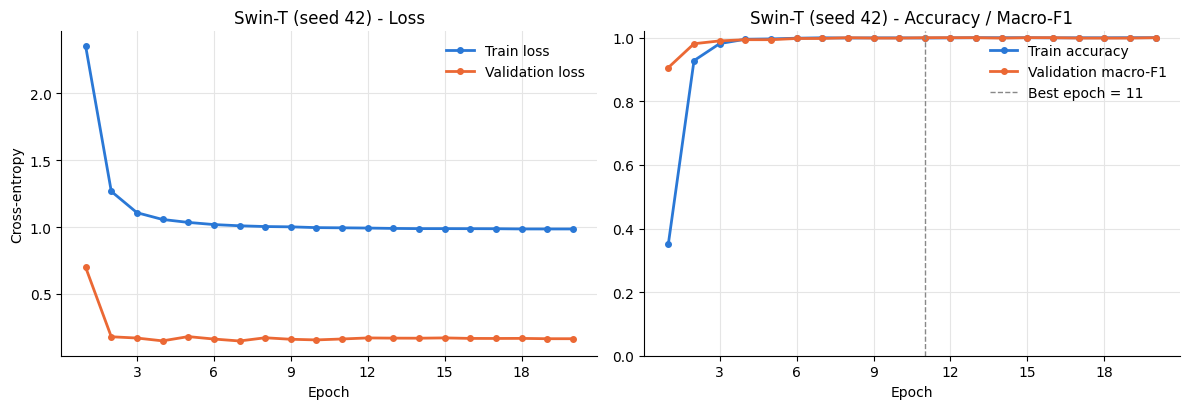


[Swin-T (seed 42)] เทรนเสร็จ: best epoch 11 | val macro-F1 1.0000 | training time 8.69 นาที


load test:   0%|          | 0/795 [00:00<?, ?it/s]


===== Swin-T (seed 42) | best epoch 11 | Test n = 795 =====
Accuracy        : 0.9258
Macro-F1        : 0.9245
AUC (OvR macro) : 0.9993
MCC             : 0.9218


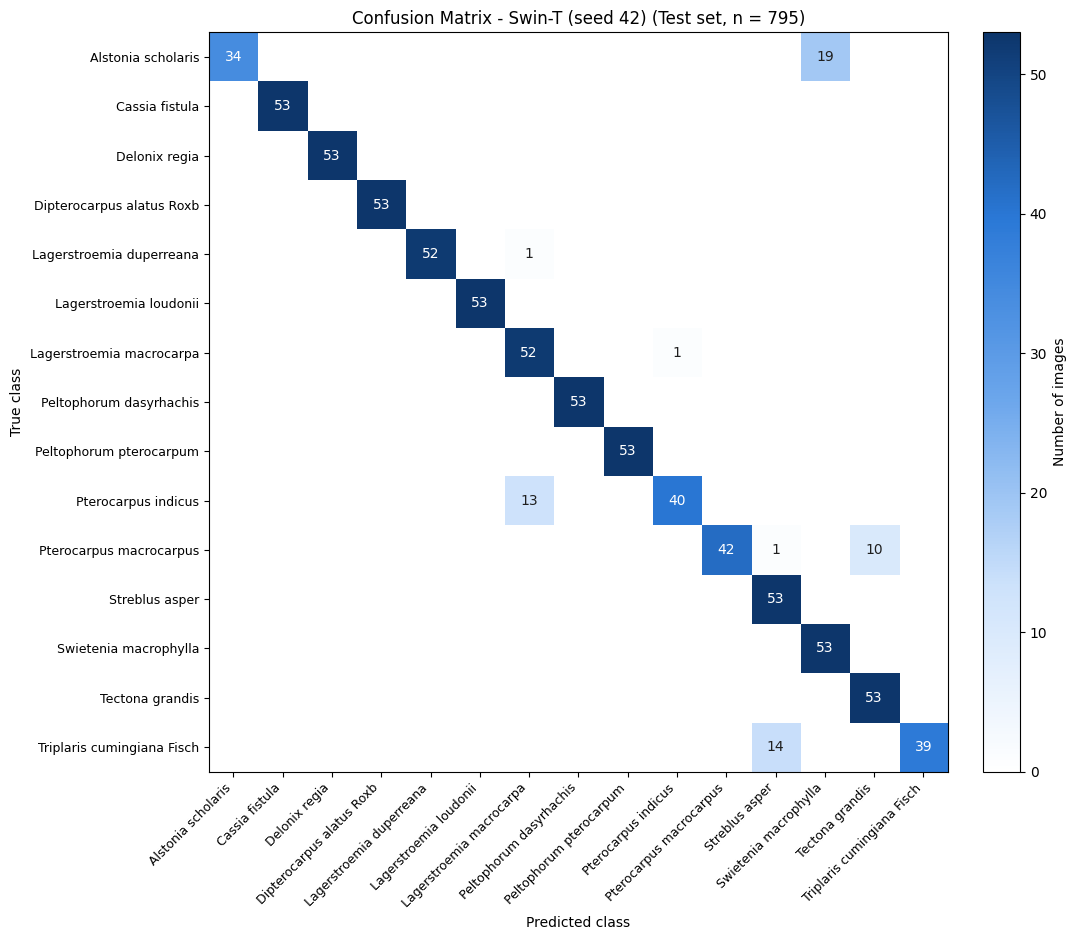

,precision,recall,f1-score,support
Alstonia scholaris,1.0000,0.6415,0.7816,53.0000
Cassia fistula,1.0000,1.0000,1.0000,53.0000
Delonix regia,1.0000,1.0000,1.0000,53.0000
Dipterocarpus alatus Roxb,1.0000,1.0000,1.0000,53.0000
Lagerstroemia duperreana,1.0000,0.9811,0.9905,53.0000
Lagerstroemia loudonii,1.0000,1.0000,1.0000,53.0000
Lagerstroemia macrocarpa,0.7879,0.9811,0.8739,53.0000
Peltophorum dasyrhachis,1.0000,1.0000,1.0000,53.0000
Peltophorum pterocarpum,1.0000,1.0000,1.0000,53.0000
Pterocarpus indicus,0.9756,0.7547,0.8511,53.0000


[DRIVE] บันทึกผล Swin-T (seed 42) ขึ้น Drive แล้ว

Swin-T (seed 123)
[Swin-T (seed 123)] swin_tiny_patch4_window7_224.ms_in1k | pretrained: timm/swin_tiny_patch4_window7_224.ms_in1k
[Swin-T (seed 123)] head ใหม่: Linear(in_features=768, out_features=15, bias=True) | params 27.53 M | train 3705 | valid 795 | AMP fp16
[Swin-T (seed 123)] Full fine-tuning (ทุกชั้นเทรนได้ ไม่ freeze) | trainable 27.53 M / 27.53 M | pretrained tensors โหลดครบ 171 (ไม่ตรง 0) | head สุ่มใหม่: Linear(in_features=768, out_features=15, bias=True)
[Swin-T (seed 123)] ep 01/20 | train loss 2.3941 acc 0.3304 | val loss 0.8412 acc 0.8516 macro-F1 0.8457 |  27.3s  * best
[Swin-T (seed 123)] ep 02/20 | train loss 1.2701 acc 0.9196 | val loss 0.2050 acc 0.9849 macro-F1 0.9848 |  27.4s  * best
[Swin-T (seed 123)] ep 03/20 | train loss 1.1009 acc 0.9833 | val loss 0.1750 acc 0.9925 macro-F1 0.9924 |  26.1s  * best
[Swin-T (seed 123)] ep 04/20 | train loss 1.0548 acc 0.9943 | val loss 0.1256 acc 0.9962 macro-F1 0.9962 |  

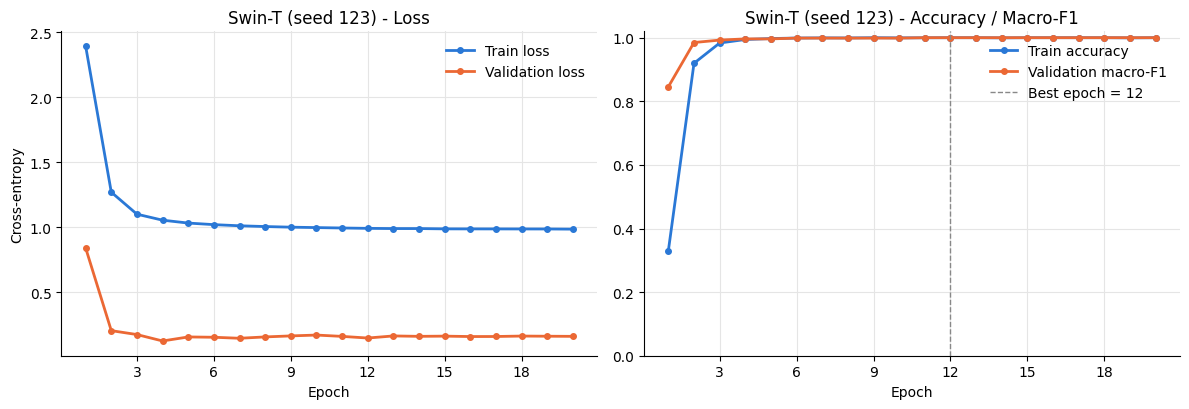


[Swin-T (seed 123)] เทรนเสร็จ: best epoch 12 | val macro-F1 1.0000 | training time 8.87 นาที

===== Swin-T (seed 123) | best epoch 12 | Test n = 795 =====
Accuracy        : 0.9195
Macro-F1        : 0.9175
AUC (OvR macro) : 0.9995
MCC             : 0.9155


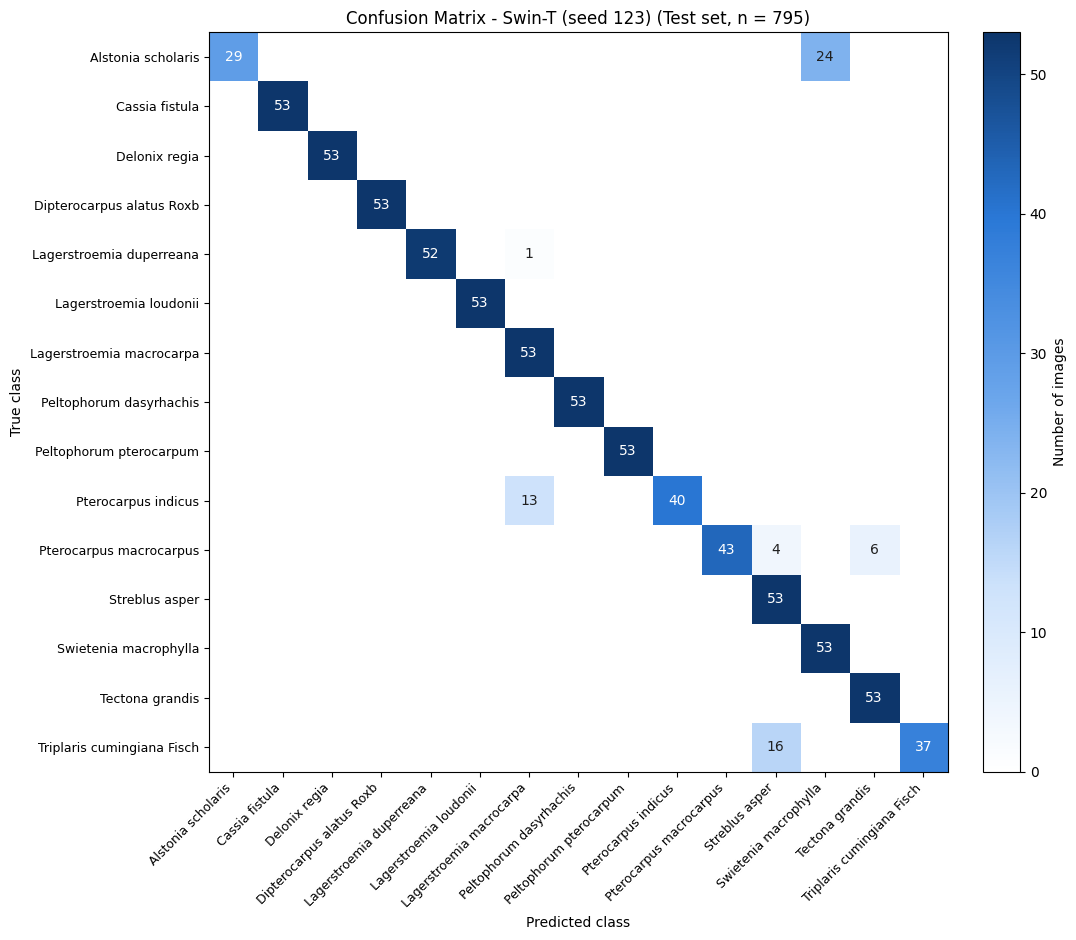

,precision,recall,f1-score,support
Alstonia scholaris,1.0000,0.5472,0.7073,53.0000
Cassia fistula,1.0000,1.0000,1.0000,53.0000
Delonix regia,1.0000,1.0000,1.0000,53.0000
Dipterocarpus alatus Roxb,1.0000,1.0000,1.0000,53.0000
Lagerstroemia duperreana,1.0000,0.9811,0.9905,53.0000
Lagerstroemia loudonii,1.0000,1.0000,1.0000,53.0000
Lagerstroemia macrocarpa,0.7910,1.0000,0.8833,53.0000
Peltophorum dasyrhachis,1.0000,1.0000,1.0000,53.0000
Peltophorum pterocarpum,1.0000,1.0000,1.0000,53.0000
Pterocarpus indicus,1.0000,0.7547,0.8602,53.0000


[DRIVE] บันทึกผล Swin-T (seed 123) ขึ้น Drive แล้ว

Swin-T (seed 2026)
[Swin-T (seed 2026)] swin_tiny_patch4_window7_224.ms_in1k | pretrained: timm/swin_tiny_patch4_window7_224.ms_in1k
[Swin-T (seed 2026)] head ใหม่: Linear(in_features=768, out_features=15, bias=True) | params 27.53 M | train 3705 | valid 795 | AMP fp16
[Swin-T (seed 2026)] Full fine-tuning (ทุกชั้นเทรนได้ ไม่ freeze) | trainable 27.53 M / 27.53 M | pretrained tensors โหลดครบ 171 (ไม่ตรง 0) | head สุ่มใหม่: Linear(in_features=768, out_features=15, bias=True)
[Swin-T (seed 2026)] ep 01/20 | train loss 2.3345 acc 0.3514 | val loss 0.7565 acc 0.8830 macro-F1 0.8808 |  26.7s  * best
[Swin-T (seed 2026)] ep 02/20 | train loss 1.2611 acc 0.9312 | val loss 0.1900 acc 0.9862 macro-F1 0.9861 |  26.9s  * best
[Swin-T (seed 2026)] ep 03/20 | train loss 1.1005 acc 0.9841 | val loss 0.1697 acc 0.9950 macro-F1 0.9950 |  26.5s  * best
[Swin-T (seed 2026)] ep 04/20 | train loss 1.0573 acc 0.9946 | val loss 0.1622 acc 0.9937 macro-F1 0

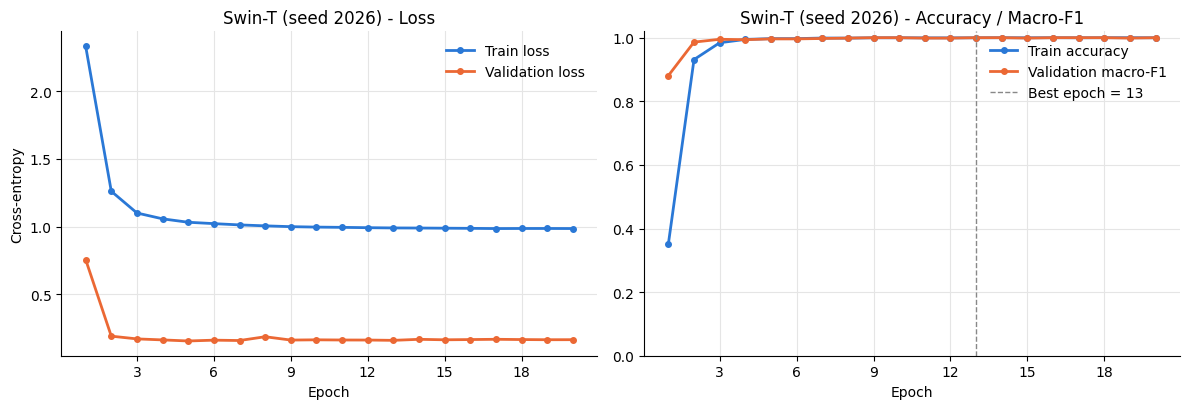


[Swin-T (seed 2026)] เทรนเสร็จ: best epoch 13 | val macro-F1 1.0000 | training time 8.88 นาที

===== Swin-T (seed 2026) | best epoch 13 | Test n = 795 =====
Accuracy        : 0.9346
Macro-F1        : 0.9326
AUC (OvR macro) : 0.9995
MCC             : 0.9313


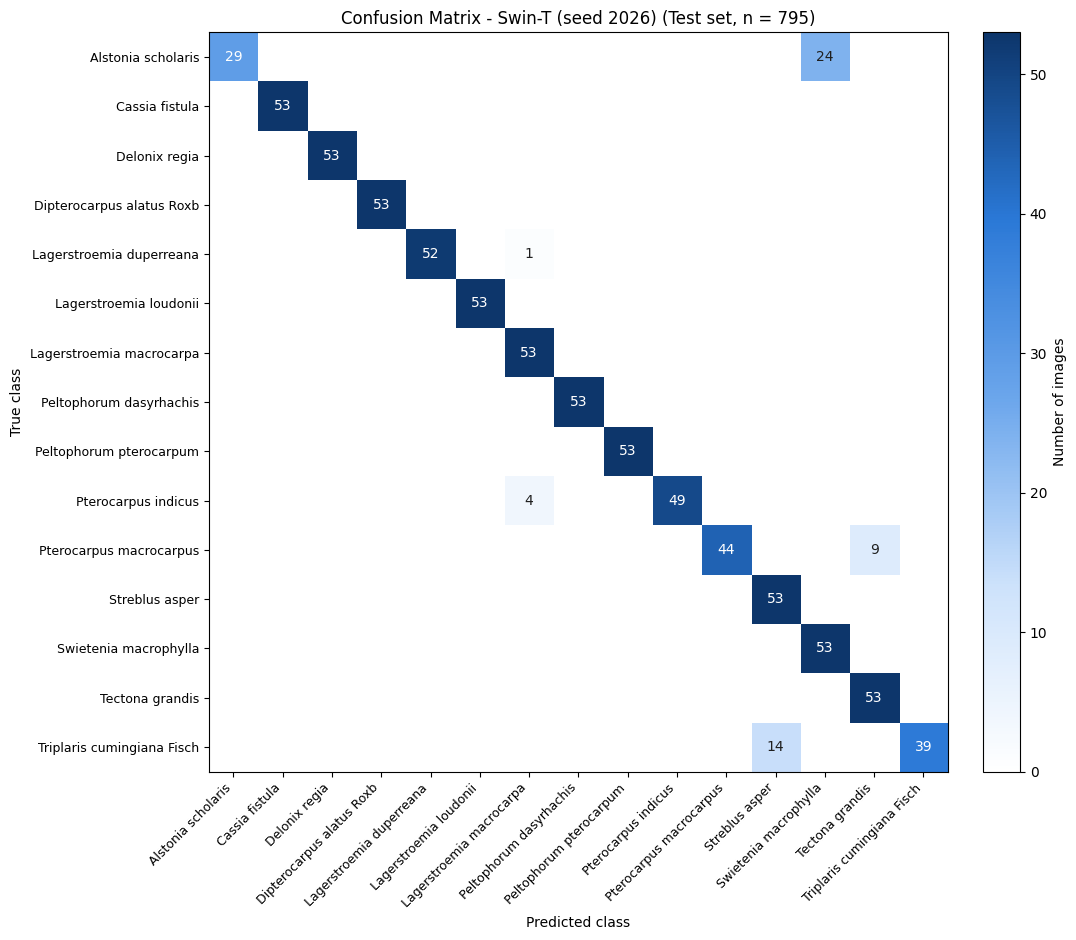

,precision,recall,f1-score,support
Alstonia scholaris,1.0000,0.5472,0.7073,53.0000
Cassia fistula,1.0000,1.0000,1.0000,53.0000
Delonix regia,1.0000,1.0000,1.0000,53.0000
Dipterocarpus alatus Roxb,1.0000,1.0000,1.0000,53.0000
Lagerstroemia duperreana,1.0000,0.9811,0.9905,53.0000
Lagerstroemia loudonii,1.0000,1.0000,1.0000,53.0000
Lagerstroemia macrocarpa,0.9138,1.0000,0.9550,53.0000
Peltophorum dasyrhachis,1.0000,1.0000,1.0000,53.0000
Peltophorum pterocarpum,1.0000,1.0000,1.0000,53.0000
Pterocarpus indicus,1.0000,0.9245,0.9608,53.0000


[DRIVE] บันทึกผล Swin-T (seed 2026) ขึ้น Drive แล้ว

Swin-T-E20 (seed 42)
[Swin-T-E20 (seed 42)] swin_tiny_patch4_window7_224.ms_in1k | pretrained: timm/swin_tiny_patch4_window7_224.ms_in1k
[Swin-T-E20 (seed 42)] head ใหม่: Linear(in_features=768, out_features=15, bias=True) | params 27.53 M | train 3705 | valid 795 | AMP fp16
[Swin-T-E20 (seed 42)] Full fine-tuning (ทุกชั้นเทรนได้ ไม่ freeze) | trainable 27.53 M / 27.53 M | pretrained tensors โหลดครบ 171 (ไม่ตรง 0) | head สุ่มใหม่: Linear(in_features=768, out_features=15, bias=True)
[Swin-T-E20 (seed 42)] ep 01/20 | train loss 2.3528 acc 0.3520 | val loss 0.6990 acc 0.9082 macro-F1 0.9061 |  26.7s  * saved
[Swin-T-E20 (seed 42)] ep 02/20 | train loss 1.2668 acc 0.9279 | val loss 0.1800 acc 0.9811 macro-F1 0.9811 |  26.8s  * saved
[Swin-T-E20 (seed 42)] ep 03/20 | train loss 1.1075 acc 0.9814 | val loss 0.1705 acc 0.9899 macro-F1 0.9899 |  26.6s  * saved
[Swin-T-E20 (seed 42)] ep 04/20 | train loss 1.0568 acc 0.9951 | val loss 0.1494 a

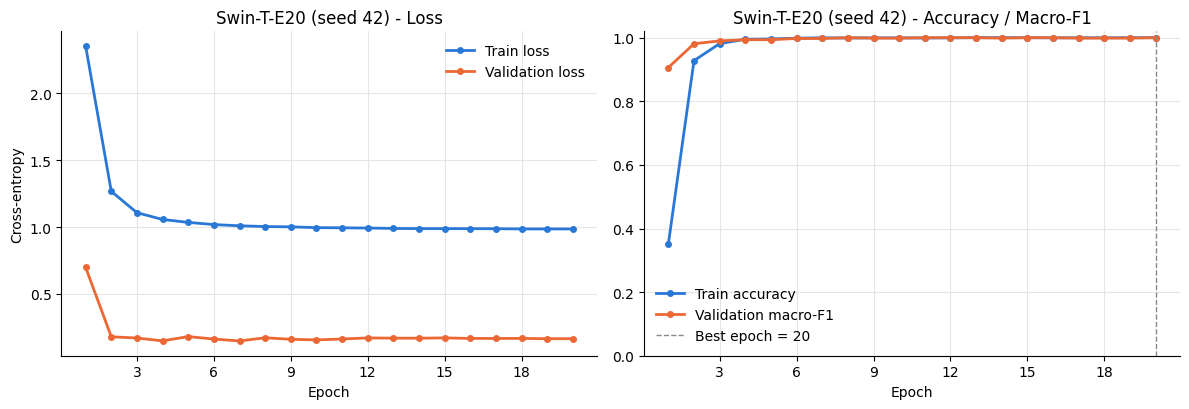


[Swin-T-E20 (seed 42)] เทรนเสร็จ: best epoch 20 | val macro-F1 1.0000 | training time 8.89 นาที

===== Swin-T-E20 (seed 42) | best epoch 20 | Test n = 795 =====
Accuracy        : 0.9296
Macro-F1        : 0.9283
AUC (OvR macro) : 0.9995
MCC             : 0.9258


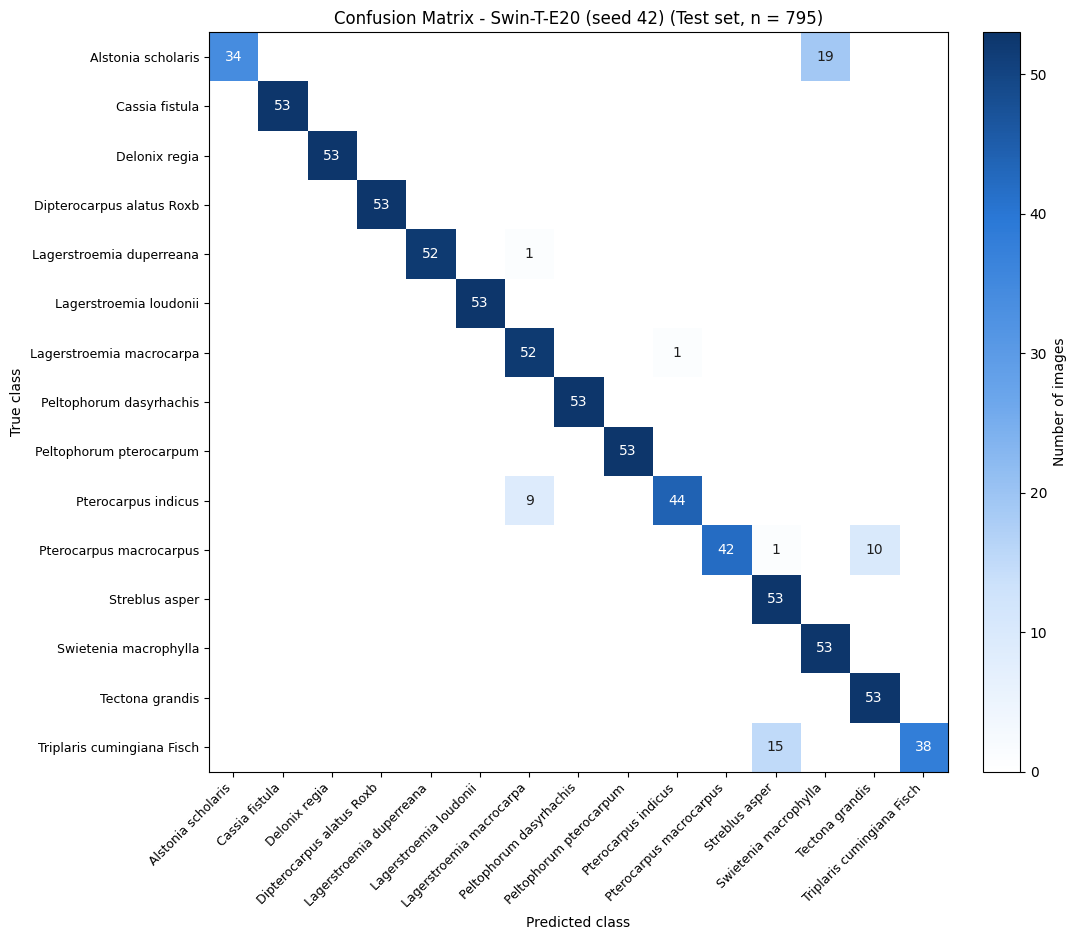

,precision,recall,f1-score,support
Alstonia scholaris,1.0000,0.6415,0.7816,53.0000
Cassia fistula,1.0000,1.0000,1.0000,53.0000
Delonix regia,1.0000,1.0000,1.0000,53.0000
Dipterocarpus alatus Roxb,1.0000,1.0000,1.0000,53.0000
Lagerstroemia duperreana,1.0000,0.9811,0.9905,53.0000
Lagerstroemia loudonii,1.0000,1.0000,1.0000,53.0000
Lagerstroemia macrocarpa,0.8387,0.9811,0.9043,53.0000
Peltophorum dasyrhachis,1.0000,1.0000,1.0000,53.0000
Peltophorum pterocarpum,1.0000,1.0000,1.0000,53.0000
Pterocarpus indicus,0.9778,0.8302,0.8980,53.0000


[DRIVE] บันทึกผล Swin-T-E20 (seed 42) ขึ้น Drive แล้ว

Swin-T-E20 (seed 123)
[Swin-T-E20 (seed 123)] swin_tiny_patch4_window7_224.ms_in1k | pretrained: timm/swin_tiny_patch4_window7_224.ms_in1k
[Swin-T-E20 (seed 123)] head ใหม่: Linear(in_features=768, out_features=15, bias=True) | params 27.53 M | train 3705 | valid 795 | AMP fp16
[Swin-T-E20 (seed 123)] Full fine-tuning (ทุกชั้นเทรนได้ ไม่ freeze) | trainable 27.53 M / 27.53 M | pretrained tensors โหลดครบ 171 (ไม่ตรง 0) | head สุ่มใหม่: Linear(in_features=768, out_features=15, bias=True)
[Swin-T-E20 (seed 123)] ep 01/20 | train loss 2.3941 acc 0.3304 | val loss 0.8412 acc 0.8516 macro-F1 0.8457 |  26.7s  * saved
[Swin-T-E20 (seed 123)] ep 02/20 | train loss 1.2701 acc 0.9196 | val loss 0.2050 acc 0.9849 macro-F1 0.9848 |  26.9s  * saved
[Swin-T-E20 (seed 123)] ep 03/20 | train loss 1.1009 acc 0.9833 | val loss 0.1750 acc 0.9925 macro-F1 0.9924 |  26.6s  * saved
[Swin-T-E20 (seed 123)] ep 04/20 | train loss 1.0548 acc 0.9943 | val los

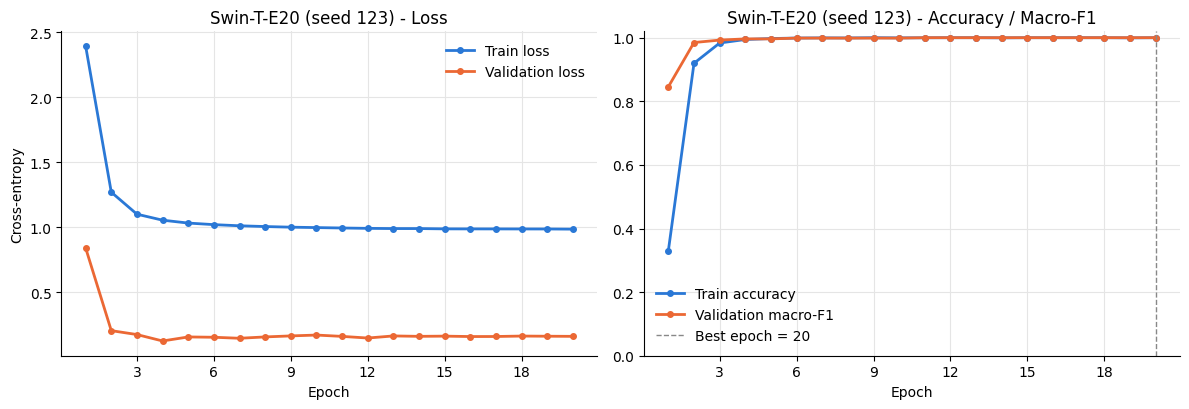


[Swin-T-E20 (seed 123)] เทรนเสร็จ: best epoch 20 | val macro-F1 1.0000 | training time 8.91 นาที

===== Swin-T-E20 (seed 123) | best epoch 20 | Test n = 795 =====
Accuracy        : 0.9371
Macro-F1        : 0.9365
AUC (OvR macro) : 0.9997
MCC             : 0.9337


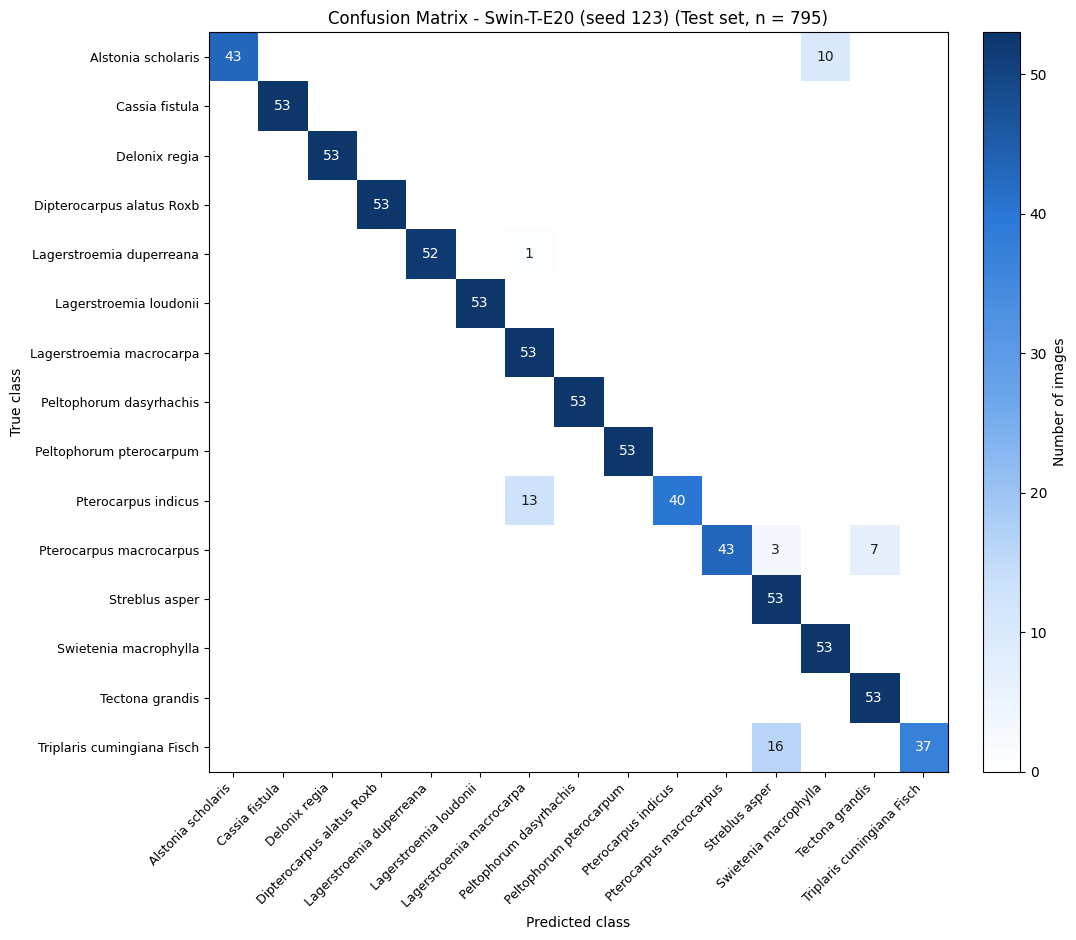

,precision,recall,f1-score,support
Alstonia scholaris,1.0000,0.8113,0.8958,53.0000
Cassia fistula,1.0000,1.0000,1.0000,53.0000
Delonix regia,1.0000,1.0000,1.0000,53.0000
Dipterocarpus alatus Roxb,1.0000,1.0000,1.0000,53.0000
Lagerstroemia duperreana,1.0000,0.9811,0.9905,53.0000
Lagerstroemia loudonii,1.0000,1.0000,1.0000,53.0000
Lagerstroemia macrocarpa,0.7910,1.0000,0.8833,53.0000
Peltophorum dasyrhachis,1.0000,1.0000,1.0000,53.0000
Peltophorum pterocarpum,1.0000,1.0000,1.0000,53.0000
Pterocarpus indicus,1.0000,0.7547,0.8602,53.0000


[DRIVE] บันทึกผล Swin-T-E20 (seed 123) ขึ้น Drive แล้ว

Swin-T-E20 (seed 2026)
[Swin-T-E20 (seed 2026)] swin_tiny_patch4_window7_224.ms_in1k | pretrained: timm/swin_tiny_patch4_window7_224.ms_in1k
[Swin-T-E20 (seed 2026)] head ใหม่: Linear(in_features=768, out_features=15, bias=True) | params 27.53 M | train 3705 | valid 795 | AMP fp16
[Swin-T-E20 (seed 2026)] Full fine-tuning (ทุกชั้นเทรนได้ ไม่ freeze) | trainable 27.53 M / 27.53 M | pretrained tensors โหลดครบ 171 (ไม่ตรง 0) | head สุ่มใหม่: Linear(in_features=768, out_features=15, bias=True)
[Swin-T-E20 (seed 2026)] ep 01/20 | train loss 2.3345 acc 0.3514 | val loss 0.7565 acc 0.8830 macro-F1 0.8808 |  26.7s  * saved
[Swin-T-E20 (seed 2026)] ep 02/20 | train loss 1.2611 acc 0.9312 | val loss 0.1900 acc 0.9862 macro-F1 0.9861 |  26.9s  * saved
[Swin-T-E20 (seed 2026)] ep 03/20 | train loss 1.1005 acc 0.9841 | val loss 0.1697 acc 0.9950 macro-F1 0.9950 |  26.6s  * saved
[Swin-T-E20 (seed 2026)] ep 04/20 | train loss 1.0573 acc 0.9946 

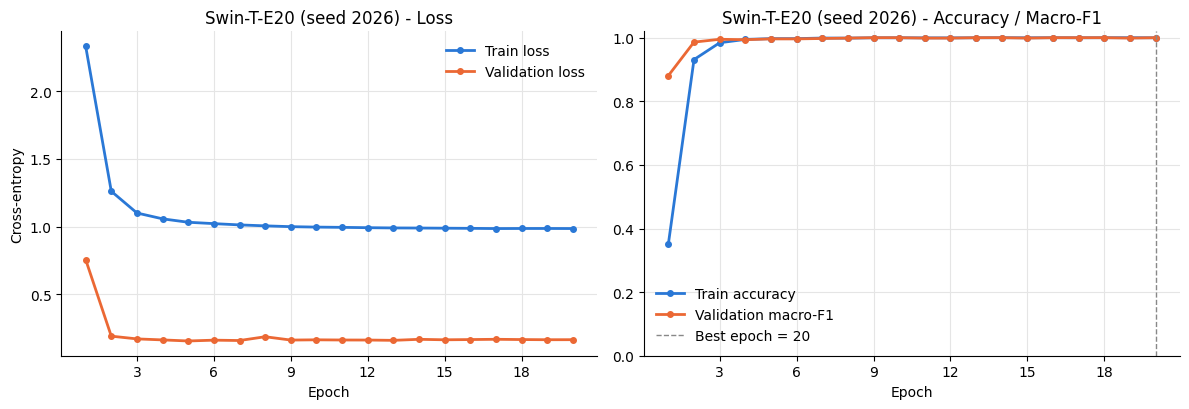


[Swin-T-E20 (seed 2026)] เทรนเสร็จ: best epoch 20 | val macro-F1 1.0000 | training time 8.90 นาที

===== Swin-T-E20 (seed 2026) | best epoch 20 | Test n = 795 =====
Accuracy        : 0.9283
Macro-F1        : 0.9253
AUC (OvR macro) : 0.9993
MCC             : 0.9249


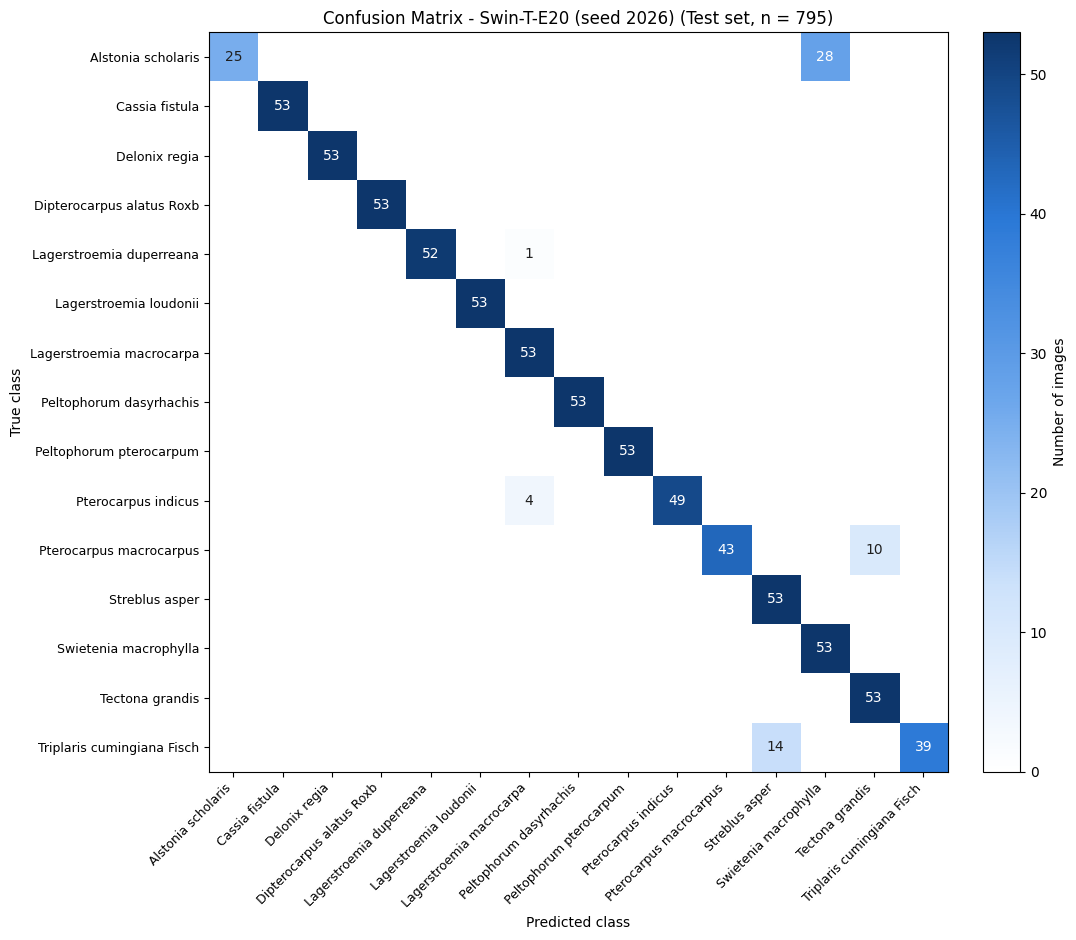

,precision,recall,f1-score,support
Alstonia scholaris,1.0000,0.4717,0.6410,53.0000
Cassia fistula,1.0000,1.0000,1.0000,53.0000
Delonix regia,1.0000,1.0000,1.0000,53.0000
Dipterocarpus alatus Roxb,1.0000,1.0000,1.0000,53.0000
Lagerstroemia duperreana,1.0000,0.9811,0.9905,53.0000
Lagerstroemia loudonii,1.0000,1.0000,1.0000,53.0000
Lagerstroemia macrocarpa,0.9138,1.0000,0.9550,53.0000
Peltophorum dasyrhachis,1.0000,1.0000,1.0000,53.0000
Peltophorum pterocarpum,1.0000,1.0000,1.0000,53.0000
Pterocarpus indicus,1.0000,0.9245,0.9608,53.0000


[DRIVE] บันทึกผล Swin-T-E20 (seed 2026) ขึ้น Drive แล้ว

[PASS] STEP 4: ผลครบ 6 รอบ | รวมผลทั้งหมดที่ใช้ได้ 6 รอบ: Swin-T (seed 42), Swin-T (seed 123), Swin-T (seed 2026), Swin-T-E20 (seed 42), Swin-T-E20 (seed 123), Swin-T-E20 (seed 2026)


In [ ]:
if RESUME_FROM_DRIVE and not FORCE_RETRAIN:
    pull_runs_from_drive()

plan = []
for tag in MODELS:
    for seed in SEEDS:
        ok, why = check_run(tag, seed, MODELS[tag])
        plan.append({'model': tag, 'seed': seed, 'action': 'train + test' if (FORCE_RETRAIN or not ok) else 'ใช้ผลเดิม',
                     'note': 'FORCE_RETRAIN' if FORCE_RETRAIN else why})
display(pd.DataFrame(plan))

for p in plan:
    tag, seed = p['model'], p['seed']
    if p['action'] != 'train + test':
        print(f'[SKIP] {run_label(tag, seed)}: มีผลครบแล้ว - ไม่เทรนซ้ำ')
        continue
    print('\n' + '=' * 100 + f'\n{run_label(tag, seed)}\n' + '=' * 100)
    run, hist = train_model(tag, seed)
    test_model(tag, seed, run, hist)
    push_run_to_drive(tag, seed)

RESULTS = scan_runs()
done = [(t, s) for t in MODELS for s in SEEDS if (t, s) in RESULTS]
assert len(done) == len(MODELS) * len(SEEDS), f'ยังไม่ครบ: มี {done}'
print(f'\n[PASS] STEP 4: ผลครบ {len(done)} รอบ | รวมผลทั้งหมดที่ใช้ได้ {len(RESULTS)} รอบ: '
      + ', '.join(run_label(*k) for k in RESULTS))

## STEP 4b: รันซ้ำ seed เดิม (ตรวจความคงที่) — Swin-T seed 123
เจ้าของงานวิจัยขอให้รัน Swin-T seed 123 ซ้ำ เพราะผลสูงกว่า seed อื่น (Acc 94.72% เทียบกับ 90.44% / 92.96%)
- เทรนใหม่ด้วย **seed, ข้อมูล, hyperparameter เดิมทุกอย่าง** → เก็บใน `reruns/<RERUN_ID>/` แยกจากผลหลัก (**ผลเดิมไม่ถูกลบ/ทับ**, ตารางหลักยังใช้ผลเดิม)
- เทียบผลเดิมกับรอบรันซ้ำ: metric ทุกตัว, F1 รายพันธุ์, ผลทำนายตรงกันกี่ภาพ, McNemar (รอบเดิม vs รันซ้ำ)
- **แปลผล:** ถ้ารันซ้ำได้ใกล้เคียงเดิม → ผลของ seed 123 ทำซ้ำได้ ไม่ใช่ความผิดพลาด ความต่างระหว่าง seed คือความแปรปรวนจากการสุ่ม (จึงต้องรายงาน Mean ± SD)


รันซ้ำ: Swin-T (seed 123) [rerun1]
[Swin-T (seed 123)] swin_tiny_patch4_window7_224.ms_in1k | pretrained: timm/swin_tiny_patch4_window7_224.ms_in1k
[Swin-T (seed 123)] head ใหม่: Linear(in_features=768, out_features=15, bias=True) | params 27.53 M | train 3705 | valid 795 | AMP fp16
[Swin-T (seed 123)] Full fine-tuning (ทุกชั้นเทรนได้ ไม่ freeze) | trainable 27.53 M / 27.53 M | pretrained tensors โหลดครบ 171 (ไม่ตรง 0) | head สุ่มใหม่: Linear(in_features=768, out_features=15, bias=True)
[Swin-T (seed 123)] ep 01/20 | train loss 2.3941 acc 0.3304 | val loss 0.8412 acc 0.8516 macro-F1 0.8457 |  26.7s  * best
[Swin-T (seed 123)] ep 02/20 | train loss 1.2701 acc 0.9196 | val loss 0.2050 acc 0.9849 macro-F1 0.9848 |  27.0s  * best
[Swin-T (seed 123)] ep 03/20 | train loss 1.1009 acc 0.9833 | val loss 0.1750 acc 0.9925 macro-F1 0.9924 |  26.5s  * best
[Swin-T (seed 123)] ep 04/20 | train loss 1.0548 acc 0.9943 | val loss 0.1256 acc 0.9962 macro-F1 0.9962 |  26.5s  * best
[Swin-T (seed 123)]

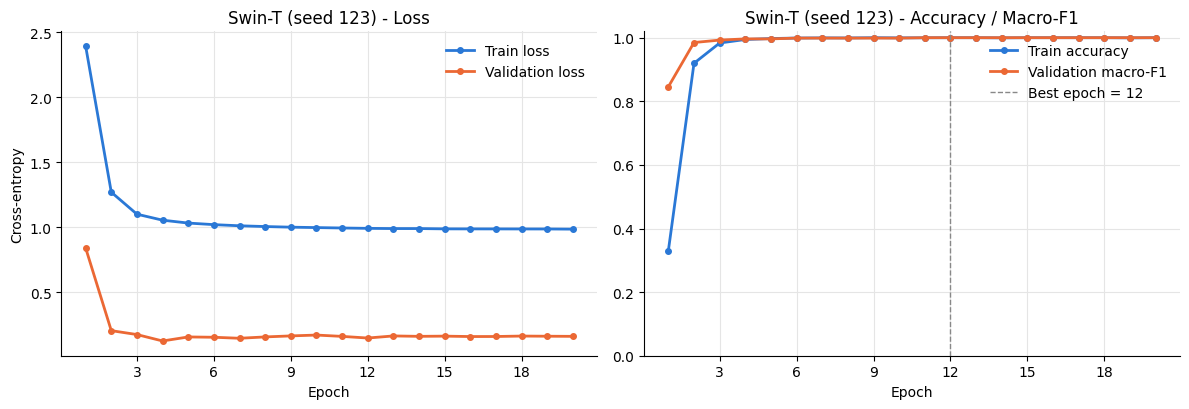


[Swin-T (seed 123)] เทรนเสร็จ: best epoch 12 | val macro-F1 1.0000 | training time 8.88 นาที

===== Swin-T (seed 123) | best epoch 12 | Test n = 795 =====
Accuracy        : 0.9195
Macro-F1        : 0.9175
AUC (OvR macro) : 0.9995
MCC             : 0.9155


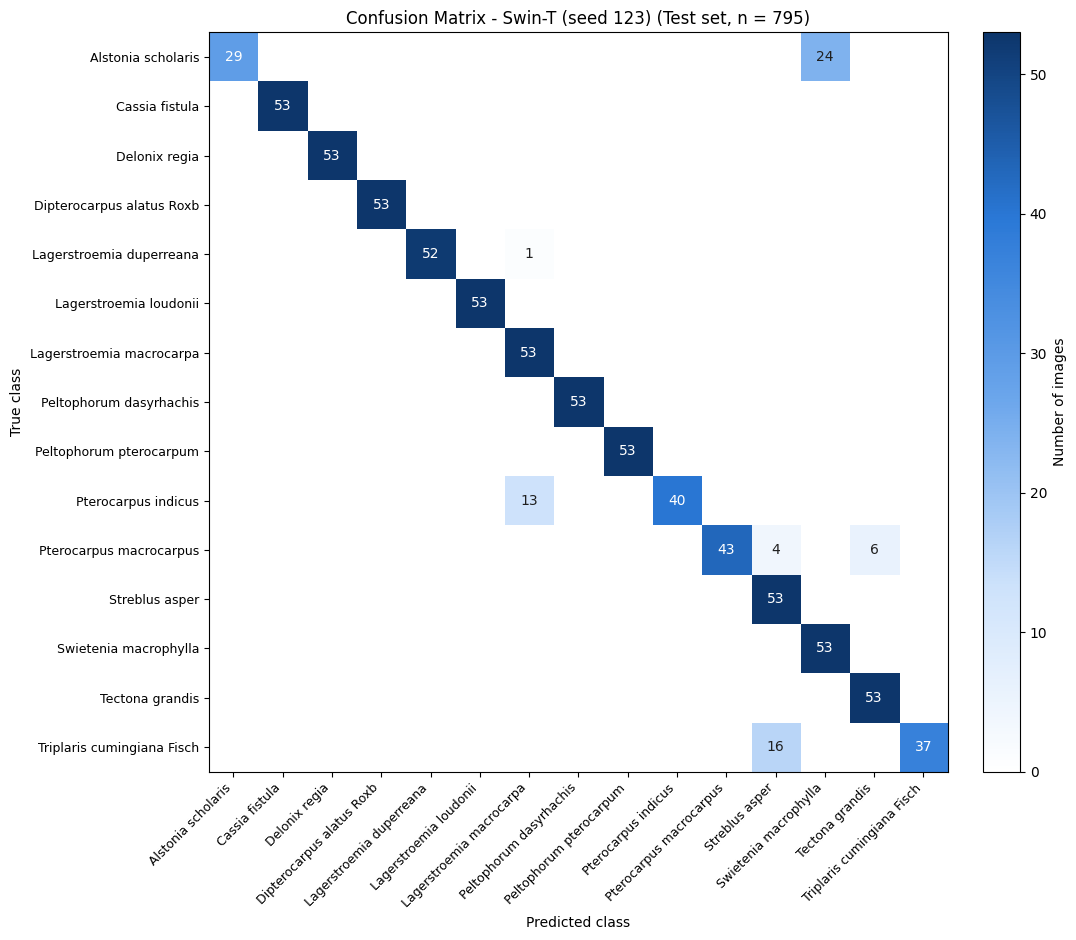

,precision,recall,f1-score,support
Alstonia scholaris,1.0000,0.5472,0.7073,53.0000
Cassia fistula,1.0000,1.0000,1.0000,53.0000
Delonix regia,1.0000,1.0000,1.0000,53.0000
Dipterocarpus alatus Roxb,1.0000,1.0000,1.0000,53.0000
Lagerstroemia duperreana,1.0000,0.9811,0.9905,53.0000
Lagerstroemia loudonii,1.0000,1.0000,1.0000,53.0000
Lagerstroemia macrocarpa,0.7910,1.0000,0.8833,53.0000
Peltophorum dasyrhachis,1.0000,1.0000,1.0000,53.0000
Peltophorum pterocarpum,1.0000,1.0000,1.0000,53.0000
Pterocarpus indicus,1.0000,0.7547,0.8602,53.0000


[DRIVE] บันทึกผล Swin-T (seed 123) ขึ้น Drive แล้ว
เทียบผลเดิม vs รันซ้ำ:


,Model,Seed,Metric,Original run,Re-run (rerun1),Difference
0,Swin-T,123,Accuracy (%),91.95,91.95,0.0
1,Swin-T,123,Macro-F1 (%),91.75,91.75,0.0
2,Swin-T,123,Macro-Precision (%),94.02,94.02,0.0
3,Swin-T,123,Macro-Recall (%),91.95,91.95,0.0
4,Swin-T,123,AUC OvR macro (%),99.95,99.95,0.0
5,Swin-T,123,MCC (%),91.55,91.55,0.0
6,Swin-T,123,Best epoch,12,12,0
7,Swin-T,123,Epochs run,20,20,0
8,Swin-T,123,Val macro-F1 (best),1.0,1.0,0.0
9,Swin-T,123,ผลทำนายตรงกันระหว่าง 2 รอบ,795 / 795 ภาพ,100.00%,



McNemar (รอบเดิม vs รันซ้ำ, seed เดียวกัน):


,Model,Seed,Test set,n,Original correct / Re-run wrong (b),Original wrong / Re-run correct (c),Test used,p-value,Significant (α=0.05)
0,Swin-T,123,ทั้งหมด (795 ภาพ),795,0,0,exact binomial,1.0,False
1,Swin-T,123,ภาพไม่ซ้ำ (448 ภาพ),448,0,0,exact binomial,1.0,False



F1 รายพันธุ์:


,Model,Seed,Class,F1 original,F1 re-run (rerun1),Difference
0,Swin-T,123,Alstonia scholaris,0.7073,0.7073,0.0
1,Swin-T,123,Cassia fistula,1.0000,1.0000,0.0
2,Swin-T,123,Delonix regia,1.0000,1.0000,0.0
3,Swin-T,123,Dipterocarpus alatus Roxb,1.0000,1.0000,0.0
4,Swin-T,123,Lagerstroemia duperreana,0.9905,0.9905,0.0
5,Swin-T,123,Lagerstroemia loudonii,1.0000,1.0000,0.0
6,Swin-T,123,Lagerstroemia macrocarpa,0.8833,0.8833,0.0
7,Swin-T,123,Peltophorum dasyrhachis,1.0000,1.0000,0.0
8,Swin-T,123,Peltophorum pterocarpum,1.0000,1.0000,0.0
9,Swin-T,123,Pterocarpus indicus,0.8602,0.8602,0.0



[สรุป] Swin-T (seed 123): ผลทำซ้ำได้ (ต่างกัน ≤ 0.5 จุด) — ผลของ seed นี้ไม่ใช่ความผิดพลาด ความต่างระหว่าง seed คือความแปรปรวนจากการสุ่ม

[INFO] ตารางหลัก (STEP 5-12) ยังใช้ผลรอบเดิม — ผลรันซ้ำอยู่ใน 13_rerun_*.csv และ reruns/


In [ ]:
RERUN_RESULTS = {}
for tag, seed in RERUNS:
    if tag not in MODELS:
        print(f'[SKIP] {tag} ไม่อยู่ใน MODELS - ข้ามการรันซ้ำ'); continue
    RUN_VARIANT = RERUN_ID
    try:
        ok, why = check_run(tag, seed, MODELS[tag])
        if FORCE_RETRAIN or not ok:
            print('\n' + '=' * 100 + f'\nรันซ้ำ: {run_label(tag, seed)} [{RERUN_ID}]\n' + '=' * 100)
            run, hist = train_model(tag, seed)
            test_model(tag, seed, run, hist)
            push_run_to_drive(tag, seed)
        else:
            print(f'[SKIP] รันซ้ำ {run_label(tag, seed)} [{RERUN_ID}] มีผลครบแล้ว - ใช้ผลเดิมของรอบรันซ้ำ')
        RERUN_RESULTS[(tag, seed)] = load_run(tag, seed)
    finally:
        RUN_VARIANT = ''

# ผลรันซ้ำที่ทำไว้แล้ว (เช่นจาก notebook ของอีกโมเดล) — โหลดมาแสดงด้วย ไม่เทรนใหม่
RUN_VARIANT = RERUN_ID
try:
    for (tag, seed), R in scan_runs(verbose=False).items():
        RERUN_RESULTS.setdefault((tag, seed), R)
finally:
    RUN_VARIANT = ''

RESULTS = scan_runs(verbose=False)
RERUN_RESULTS = {k: v for k, v in RERUN_RESULTS.items() if k in RESULTS}
rr_rows, rr_cls, rr_mc = [], [], []
_um = TEST_MANIFEST.drop_duplicates('md5')['image_id']
for (tag, seed), R2 in RERUN_RESULTS.items():
    R1 = RESULTS[(tag, seed)]
    m1, m2 = R1['run']['test_metrics'], R2['run']['test_metrics']
    for k, name in [('accuracy', 'Accuracy (%)'), ('macro_f1', 'Macro-F1 (%)'), ('macro_precision', 'Macro-Precision (%)'),
                    ('macro_recall', 'Macro-Recall (%)'), ('auc_ovr_macro', 'AUC OvR macro (%)'), ('mcc', 'MCC (%)')]:
        rr_rows.append({'Model': tag, 'Seed': seed, 'Metric': name, 'Original run': round(m1[k] * 100, 2),
                        f'Re-run ({RERUN_ID})': round(m2[k] * 100, 2), 'Difference': round((m2[k] - m1[k]) * 100, 2)})
    for k, name in [('best_epoch', 'Best epoch'), ('epochs_run', 'Epochs run'), ('best_val_macro_f1', 'Val macro-F1 (best)')]:
        rr_rows.append({'Model': tag, 'Seed': seed, 'Metric': name, 'Original run': R1['run'][k],
                        f'Re-run ({RERUN_ID})': R2['run'][k], 'Difference': round(R2['run'][k] - R1['run'][k], 4)})
    f1a, f1b = R1['report'].loc[CLASS_NAMES, 'f1-score'].astype(float), R2['report'].loc[CLASS_NAMES, 'f1-score'].astype(float)
    rr_cls.append(pd.DataFrame({'Model': tag, 'Seed': seed, 'Class': CLASS_NAMES, 'F1 original': f1a.round(4).values,
                                f'F1 re-run ({RERUN_ID})': f1b.round(4).values, 'Difference': (f1b - f1a).round(4).values}))
    p1 = R1['pred_df'].set_index('image_id').loc[TEST_MANIFEST['image_id']]
    p2 = R2['pred_df'].set_index('image_id').loc[TEST_MANIFEST['image_id']]
    same = (p1['pred_class'].values == p2['pred_class'].values)
    rr_rows.append({'Model': tag, 'Seed': seed, 'Metric': 'ผลทำนายตรงกันระหว่าง 2 รอบ',
                    'Original run': f'{int(same.sum())} / {len(same)} ภาพ',
                    f'Re-run ({RERUN_ID})': f'{same.mean() * 100:.2f}%', 'Difference': ''})
    for label, ids in [(f'ทั้งหมด ({len(p1)} ภาพ)', TEST_MANIFEST['image_id']), (f'ภาพไม่ซ้ำ ({len(_um)} ภาพ)', _um)]:
        q1, q2 = R1['pred_df'].set_index('image_id').loc[ids], R2['pred_df'].set_index('image_id').loc[ids]
        r = mcnemar_test(q1['true_class'].values, q1['pred_class'].values, q2['pred_class'].values)
        rr_mc.append({'Model': tag, 'Seed': seed, 'Test set': label, 'n': r['n'],
                      'Original correct / Re-run wrong (b)': r['b'], 'Original wrong / Re-run correct (c)': r['c'],
                      'Test used': r['test'], 'p-value': r['p_value'],
                      'Significant (α=0.05)': r['p_value'] < MCNEMAR_ALPHA})

if RERUN_RESULTS:
    df_rr, df_rr_cls, df_rr_mc = pd.DataFrame(rr_rows), pd.concat(rr_cls, ignore_index=True), pd.DataFrame(rr_mc)
    print('เทียบผลเดิม vs รันซ้ำ:'); display(df_rr)
    print('\nMcNemar (รอบเดิม vs รันซ้ำ, seed เดียวกัน):'); display(df_rr_mc)
    print('\nF1 รายพันธุ์:'); display(df_rr_cls)
    df_rr.to_csv(RESULTS_DIR / '13_rerun_comparison.csv', index=False, encoding='utf-8-sig')
    df_rr_cls.to_csv(RESULTS_DIR / '13_rerun_per_class_f1.csv', index=False, encoding='utf-8-sig')
    df_rr_mc.to_csv(RESULTS_DIR / '13_rerun_mcnemar.csv', index=False, encoding='utf-8-sig')
    for (tag, seed) in RERUN_RESULTS:
        d = df_rr[(df_rr.Model == tag) & (df_rr.Seed == seed) & df_rr.Metric.isin(['Accuracy (%)', 'Macro-F1 (%)'])]
        mx = d['Difference'].abs().max()
        verdict = ('ผลทำซ้ำได้ (ต่างกัน ≤ 0.5 จุด) — ผลของ seed นี้ไม่ใช่ความผิดพลาด ความต่างระหว่าง seed คือความแปรปรวนจากการสุ่ม'
                   if mx <= 0.5 else
                   f'ผลต่างจากรอบเดิม {mx:.2f} จุด — การเทรนบน GPU ไม่ deterministic 100% (ดูตาราง McNemar ว่าต่างอย่างมีนัยสำคัญหรือไม่)')
        print(f'\n[สรุป] {run_label(tag, seed)}: {verdict}')
    print('\n[INFO] ตารางหลัก (STEP 5-12) ยังใช้ผลรอบเดิม — ผลรันซ้ำอยู่ใน 13_rerun_*.csv และ reruns/')
else:
    print('ไม่มีการรันซ้ำ (RERUNS ว่าง)')

## STEP 5: ผลราย Seed + Mean ± SD
- `06_results_per_seed.csv` — Architecture, Seed, **Macro-F1 (%)**, **Accuracy (%)** (+ Macro-Precision, Macro-Recall, AUC, MCC ค่าเดิม)
- `07_summary_mean_sd.csv` — ต่อ Architecture: **Mean ± SD** จาก 3 seeds (แยกไฟล์)

$$\text{Mean}=\frac{x_1+x_2+x_3}{3}\qquad \text{SD}=\sqrt{\frac{1}{N-1}\sum_{i=1}^{N}(x_i-\text{Mean})^2},\; N=3 \;(\text{sample SD})$$

In [ ]:
RESULTS = scan_runs(verbose=False)
MAIN = [('macro_f1', 'Macro-F1 (%)'), ('accuracy', 'Accuracy (%)')]
EXTRA = [('macro_precision', 'Macro-Precision (%)'), ('macro_recall', 'Macro-Recall (%)'),
         ('weighted_f1', 'Weighted-F1 (%)'), ('auc_ovr_macro', 'AUC OvR macro (%)'), ('mcc', 'MCC (%)')]

rows = []
for (tag, seed), R in RESULTS.items():
    m, r = R['run']['test_metrics'], R['run']
    row = {'Architecture': tag, 'Seed': seed}
    for k, col in MAIN + EXTRA:
        row[col] = round(m[k] * 100, 2)
    row.update({'Test n': m['n_test'], 'Best epoch': r['best_epoch'], 'Epochs run': r['epochs_run'],
                'Val macro-F1 (best) (%)': round(r['best_val_macro_f1'] * 100, 2),
                'Training time (min)': round(r['training_time_sec'] / 60, 2)})
    rows.append(row)
df_seed = pd.DataFrame(rows)
print('ผลราย seed (Test set, n = %d)' % N_TEST_ACTUAL)
display(df_seed)
df_seed.to_csv(RESULTS_DIR / '06_results_per_seed.csv', index=False, encoding='utf-8-sig')

def mean_sd(values):
    x = np.asarray(values, dtype=float) * 100
    return x.mean(), (x.std(ddof=1) if len(x) > 1 else float('nan'))

def summarize(metrics):
    out = []
    for tag in sorted({t for t, _ in RESULTS}, key=arch_key):
        seeds = sorted(s for t, s in RESULTS if t == tag)
        row = {'Architecture': tag, 'N seeds': len(seeds), 'Seeds': ', '.join(map(str, seeds))}
        for k, col in metrics:
            mu, sd = mean_sd([RESULTS[(tag, s)]['run']['test_metrics'][k] for s in seeds])
            name = col.replace(' (%)', '')
            row[f'{name} Mean (%)'] = round(mu, 2)
            row[f'{name} SD (%)'] = round(sd, 2) if not np.isnan(sd) else np.nan
            row[f'{col} Mean ± SD'] = f'{mu:.2f} ± {sd:.2f}' if not np.isnan(sd) else f'{mu:.2f} (seed เดียว)'
        out.append(row)
    return pd.DataFrame(out)

df_meansd = summarize(MAIN)
df_meansd_all = summarize(MAIN + EXTRA)
print('\nสรุป Mean ± SD (sample SD, N-1)')
display(df_meansd[['Architecture', 'N seeds', 'Seeds', 'Macro-F1 (%) Mean ± SD', 'Accuracy (%) Mean ± SD']])
df_meansd.to_csv(RESULTS_DIR / '07_summary_mean_sd.csv', index=False, encoding='utf-8-sig')
df_meansd_all.to_csv(RESULTS_DIR / '07b_summary_mean_sd_all_metrics.csv', index=False, encoding='utf-8-sig')

# แสดงการคำนวณให้ตรวจสอบได้
for tag in df_meansd['Architecture']:
    seeds = sorted(s for t, s in RESULTS if t == tag)
    for k, col in MAIN:
        xs = [RESULTS[(tag, s)]['run']['test_metrics'][k] * 100 for s in seeds]
        mu, sd = mean_sd([x / 100 for x in xs])
        print(f'{tag:8s} {col:13s}: (' + ' + '.join(f'{x:.2f}' for x in xs) + f') / {len(xs)} = {mu:.2f}'
              + (f' | SD = {sd:.2f}' if len(xs) > 1 else ''))
for tag in MODELS:
    n = sum(1 for t, _ in RESULTS if t == tag)
    if n < len(SEEDS):
        print(f'[WARNING] {tag} มีผลเพียง {n}/{len(SEEDS)} seeds')

ผลราย seed (Test set, n = 795)


,Architecture,Seed,Macro-F1 (%),Accuracy (%),Macro-Precision (%),Macro-Recall (%),Weighted-F1 (%),AUC OvR macro (%),MCC (%),Test n,Best epoch,Epochs run,Val macro-F1 (best) (%),Training time (min)
0,Swin-T,42,92.45,92.58,94.14,92.58,92.45,99.93,92.18,795,11,20,100.0,8.69
1,Swin-T,123,91.75,91.95,94.02,91.95,91.75,99.95,91.55,795,12,20,100.0,8.87
2,Swin-T,2026,93.26,93.46,94.99,93.46,93.26,99.95,93.13,795,13,20,100.0,8.88
3,Swin-T-E20,42,92.83,92.96,94.41,92.96,92.83,99.95,92.58,795,20,20,100.0,8.89
4,Swin-T-E20,123,93.65,93.71,95.01,93.71,93.65,99.97,93.37,795,20,20,100.0,8.91
5,Swin-T-E20,2026,92.53,92.83,94.67,92.83,92.53,99.93,92.49,795,20,20,100.0,8.90



สรุป Mean ± SD (sample SD, N-1)


,Architecture,N seeds,Seeds,Macro-F1 (%) Mean ± SD,Accuracy (%) Mean ± SD
0,Swin-T,3,"42, 123, 2026",92.49 ± 0.76,92.66 ± 0.76
1,Swin-T-E20,3,"42, 123, 2026",93.00 ± 0.58,93.17 ± 0.48


Swin-T   Macro-F1 (%) : (92.45 + 91.75 + 93.26) / 3 = 92.49 | SD = 0.76
Swin-T   Accuracy (%) : (92.58 + 91.95 + 93.46) / 3 = 92.66 | SD = 0.76
Swin-T-E20 Macro-F1 (%) : (92.83 + 93.65 + 92.53) / 3 = 93.00 | SD = 0.58
Swin-T-E20 Accuracy (%) : (92.96 + 93.71 + 92.83) / 3 = 93.17 | SD = 0.48


## STEP 6: CSV ผลทำนายรายภาพ (Test 795 ภาพ) สำหรับ McNemar
- `08_predictions_seed<seed>.csv` — 1 แถวต่อ 1 ภาพ: **Image ID | True Label | Swin-T Prediction | (โมเดลอื่น) Prediction** — แยกไฟล์ต่อ seed
- `08_predictions_all_seeds.csv` — ทุกโมเดลทุก seed ในตารางเดียว
- `test_manifest.csv` (STEP 2) — Image ID ↔ ชื่อไฟล์, โฟลเดอร์ต้นทาง, MD5

In [ ]:
RESULTS = scan_runs(verbose=False)
base = TEST_MANIFEST[['image_id', 'true_label']].rename(columns={'image_id': 'Image ID', 'true_label': 'True Label'})

def preds_of(tag, seed):
    p = RESULTS[(tag, seed)]['pred_df'].set_index('image_id')
    assert p.index.is_unique and set(p.index) == set(base['Image ID']), f'{run_label(tag, seed)}: Image ID ไม่ตรงกับ test_manifest'
    assert (p.loc[base['Image ID'], 'true_class'].to_numpy() == base['True Label'].to_numpy()).all(), \
        f'{run_label(tag, seed)}: True Label ไม่ตรงกับ test_manifest'
    return p.loc[base['Image ID'], 'pred_class'].to_numpy()

PRED_BY_SEED = {}
for seed in sorted({s for _, s in RESULTS}):
    wide = base.copy()
    for tag in sorted({t for t, s in RESULTS if s == seed}, key=arch_key):
        wide[f'{tag} Prediction'] = preds_of(tag, seed)
    wide.to_csv(RESULTS_DIR / f'08_predictions_seed{seed}.csv', index=False, encoding='utf-8-sig')
    PRED_BY_SEED[seed] = wide
    print(f'seed {seed}: {len(wide)} ภาพ | คอลัมน์ {list(wide.columns)}')

pred_all = base.copy()
for (tag, seed) in RESULTS:
    pred_all[f'{tag} Prediction (seed {seed})'] = preds_of(tag, seed)
pred_all.to_csv(RESULTS_DIR / '08_predictions_all_seeds.csv', index=False, encoding='utf-8-sig')
display(pred_all.head(10))
print(f'\n[PASS] STEP 6: บันทึกผลทำนาย {len(pred_all)} ภาพ x {len(RESULTS)} รอบ')

seed 42: 795 ภาพ | คอลัมน์ ['Image ID', 'True Label', 'Swin-T Prediction', 'Swin-T-E20 Prediction']
seed 123: 795 ภาพ | คอลัมน์ ['Image ID', 'True Label', 'Swin-T Prediction', 'Swin-T-E20 Prediction']
seed 2026: 795 ภาพ | คอลัมน์ ['Image ID', 'True Label', 'Swin-T Prediction', 'Swin-T-E20 Prediction']


,Image ID,True Label,Swin-T Prediction (seed 42),Swin-T Prediction (seed 123),Swin-T Prediction (seed 2026),Swin-T-E20 Prediction (seed 42),Swin-T-E20 Prediction (seed 123),Swin-T-E20 Prediction (seed 2026)
0,img001,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris
1,img002,Alstonia scholaris,Swietenia macrophylla,Swietenia macrophylla,Swietenia macrophylla,Swietenia macrophylla,Alstonia scholaris,Swietenia macrophylla
2,img003,Alstonia scholaris,Alstonia scholaris,Swietenia macrophylla,Swietenia macrophylla,Alstonia scholaris,Alstonia scholaris,Swietenia macrophylla
3,img004,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris
4,img005,Alstonia scholaris,Swietenia macrophylla,Swietenia macrophylla,Swietenia macrophylla,Swietenia macrophylla,Swietenia macrophylla,Swietenia macrophylla
5,img006,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris
6,img007,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris
7,img008,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris
8,img009,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris
9,img010,Alstonia scholaris,Swietenia macrophylla,Swietenia macrophylla,Swietenia macrophylla,Swietenia macrophylla,Swietenia macrophylla,Swietenia macrophylla



[PASS] STEP 6: บันทึกผลทำนาย 795 ภาพ x 6 รอบ


## STEP 7: McNemar's test
ทดสอบสมมติฐานว่าโมเดล A และ B มีอัตราการทำนายผิด **ต่างกันหรือไม่** บนภาพทดสอบชุดเดียวกัน (paired)

| | B ถูก | B ผิด |
|---|---|---|
| **A ถูก** | a | **b** |
| **A ผิด** | **c** | d |

- $H_0$: $p_b = p_c$ (สองโมเดลผิดในสัดส่วนเท่ากัน) | $H_1$: $p_b \ne p_c$ | α = 0.05
- ใช้เฉพาะคู่ที่ไม่ลงรอยกัน (b, c): ถ้า **b + c < 25 ใช้ exact binomial test**, ไม่งั้นใช้ **χ² = (|b − c| − 1)² / (b + c)** (df = 1, continuity correction) — รายงานทั้งสองค่า
- **ระหว่างโมเดล (หลัก):** เทียบโมเดลต่าง ๆ ที่ seed เดียวกัน (seed 42 กับ 42, 123 กับ 123, 2026 กับ 2026) → ตอนนี้มีแค่ Swin-T จึงยังไม่มีคู่ จะคำนวณอัตโนมัติเมื่อเพิ่มโมเดลอื่น
- **ระหว่างโมเดล เฉพาะภาพไม่ซ้ำ:** test มีภาพซ้ำ (MD5 เดียวกัน) จึงคำนวณซ้ำบนภาพที่ไม่ซ้ำ (1 ภาพต่อ MD5) ด้วย → `09c` — **แนะนำให้รายงานค่านี้** เพราะ McNemar ต้องการคู่ข้อมูลที่เป็นอิสระต่อกัน
- **ระหว่าง seed (เสริม):** เทียบ Swin-T seed ต่าง ๆ — ดูว่าการเปลี่ยน seed ทำให้ผลต่างกันอย่างมีนัยสำคัญหรือไม่
- p (Holm) = ปรับ p-value สำหรับการเปรียบเทียบหลายคู่ในกลุ่มเดียวกัน

In [ ]:
# mcnemar_test() และ holm() ถูกนิยามไว้ใน cell 'ฟังก์ชันจัดการผลลัพธ์' (ใช้ร่วมกับ STEP 4b)

# ภาพ test ที่ไม่ซ้ำ (1 ภาพต่อ MD5) — McNemar ต้องการคู่ข้อมูลที่เป็นอิสระต่อกัน
_md5 = TEST_MANIFEST.set_index('image_id').loc[base['Image ID'], 'md5'].to_numpy()
UNIQUE_MASK = ~pd.Series(_md5).duplicated(keep='first').to_numpy()
N_UNIQUE = int(UNIQUE_MASK.sum())

def compare(kind, group, tA, sA, tB, sB, mask=None):
    m = np.ones(len(base), bool) if mask is None else mask
    yt = base['True Label'].to_numpy()[m]
    r = mcnemar_test(yt, preds_of(tA, sA)[m], preds_of(tB, sB)[m])
    sig = r['p_value'] < MCNEMAR_ALPHA
    A, B = run_label(tA, sA), run_label(tB, sB)
    if not sig:
        interp = f'ไม่แตกต่างอย่างมีนัยสำคัญ (p ≥ {MCNEMAR_ALPHA})'
    else:
        interp = f'แตกต่างอย่างมีนัยสำคัญ: {A if r["b"] > r["c"] else B} ทำนายถูกมากกว่า'
    return {'Comparison': kind, 'Group': group, 'Model A': tA, 'Seed A': sA, 'Model B': tB, 'Seed B': sB,
            'n': r['n'], 'Both correct (a)': r['a'], 'A correct / B wrong (b)': r['b'],
            'A wrong / B correct (c)': r['c'], 'Both wrong (d)': r['d'], 'Discordant (b+c)': r['discordant'],
            'Accuracy A (%)': round((r['a'] + r['b']) / r['n'] * 100, 2),
            'Accuracy B (%)': round((r['a'] + r['c']) / r['n'] * 100, 2),
            'Test used': r['test'], 'Statistic': round(r['statistic'], 4), 'p-value': r['p_value'],
            'p (exact binomial)': r['p_exact'], 'Chi-square (cc)': round(r['chi2'], 4), 'p (chi-square)': r['p_chi2'],
            f'Significant (α={MCNEMAR_ALPHA})': sig, 'Interpretation': interp}

RESULTS = scan_runs(verbose=False)
mc_rows = []
# (1) ระหว่างโมเดล ที่ seed เดียวกัน
for seed in sorted({s for _, s in RESULTS}):
    tags = sorted({t for t, s in RESULTS if s == seed}, key=arch_key)
    for tA, tB in itertools.combinations(tags, 2):
        mc_rows.append(compare('between models (same seed)', f'seed {seed}', tA, seed, tB, seed))
        mc_rows.append(compare('between models (same seed, unique images)', f'seed {seed}', tA, seed, tB, seed,
                               mask=UNIQUE_MASK))
# (2) ระหว่าง seed ของโมเดลเดียวกัน (เสริม)
if MCNEMAR_BETWEEN_SEEDS:
    for tag in sorted({t for t, _ in RESULTS}, key=arch_key):
        seeds = sorted(s for t, s in RESULTS if t == tag)
        for sA, sB in itertools.combinations(seeds, 2):
            mc_rows.append(compare('between seeds (same model)', tag, tag, sA, tag, sB))

COLS = ['Comparison', 'Group', 'Model A', 'Seed A', 'Model B', 'Seed B', 'n', 'Both correct (a)',
        'A correct / B wrong (b)', 'A wrong / B correct (c)', 'Both wrong (d)', 'Discordant (b+c)',
        'Accuracy A (%)', 'Accuracy B (%)', 'Test used', 'Statistic', 'p-value', 'p (Holm)',
        'p (exact binomial)', 'Chi-square (cc)', 'p (chi-square)', f'Significant (α={MCNEMAR_ALPHA})', 'Interpretation']
df_mc = pd.DataFrame(mc_rows)
if len(df_mc):
    df_mc['p (Holm)'] = np.nan
    for _, idx in df_mc.groupby(['Comparison', 'Group']).groups.items():
        df_mc.loc[idx, 'p (Holm)'] = holm(df_mc.loc[idx, 'p-value'])
    df_mc = df_mc[COLS]
else:
    df_mc = pd.DataFrame(columns=COLS)

df_mc_models = df_mc[df_mc['Comparison'] == 'between models (same seed)'].reset_index(drop=True)
df_mc_seeds  = df_mc[df_mc['Comparison'] == 'between seeds (same model)'].reset_index(drop=True)
df_mc_models.to_csv(RESULTS_DIR / '09_mcnemar_between_models.csv', index=False, encoding='utf-8-sig')
df_mc_seeds.to_csv(RESULTS_DIR / '09b_mcnemar_between_seeds.csv', index=False, encoding='utf-8-sig')
df_mc_unique = df_mc[df_mc['Comparison'] == 'between models (same seed, unique images)'].reset_index(drop=True)
df_mc_unique.to_csv(RESULTS_DIR / '09c_mcnemar_between_models_unique.csv', index=False, encoding='utf-8-sig')

show = ['Group', 'Model A', 'Seed A', 'Model B', 'Seed B', 'A correct / B wrong (b)', 'A wrong / B correct (c)',
        'Test used', 'Statistic', 'p-value', 'p (Holm)', f'Significant (α={MCNEMAR_ALPHA})', 'Interpretation']
print("McNemar's test — ระหว่างโมเดล (seed เดียวกัน)")
if len(df_mc_models):
    display(df_mc_models[show])
else:
    print(f'  ยังไม่มีคู่ให้เทียบ: ตอนนี้มีโมเดลเดียว ({", ".join(sorted({t for t, _ in RESULTS}))})\n'
          '  -> เพิ่มโมเดลใน MODELS (cell ตั้งค่า) แล้ว Run all: ผลเดิมถูกโหลดจาก Drive และตารางนี้จะคำนวณให้อัตโนมัติ')
if len(df_mc_unique):
    print(f"\nMcNemar's test — ระหว่างโมเดล เฉพาะภาพไม่ซ้ำ (n = {N_UNIQUE}, 1 ภาพต่อ MD5) <- แนะนำให้รายงานค่านี้")
    display(df_mc_unique[show])
print("\nMcNemar's test — ระหว่าง seed ของโมเดลเดียวกัน (เสริม)")
display(df_mc_seeds[show] if len(df_mc_seeds) else 'ไม่มี')

McNemar's test — ระหว่างโมเดล (seed เดียวกัน)


,Group,Model A,Seed A,Model B,Seed B,A correct / B wrong (b),A wrong / B correct (c),Test used,Statistic,p-value,p (Holm),Significant (α=0.05),Interpretation
0,seed 42,Swin-T,42,Swin-T-E20,42,1,4,exact binomial,1.0,0.375000,0.375000,False,ไม่แตกต่างอย่างมีนัยสำคัญ (p ≥ 0.05)
1,seed 123,Swin-T,123,Swin-T-E20,123,0,14,exact binomial,0.0,0.000122,0.000122,True,แตกต่างอย่างมีนัยสำคัญ: Swin-T-E20 (seed 123) ...
2,seed 2026,Swin-T,2026,Swin-T-E20,2026,5,0,exact binomial,0.0,0.062500,0.062500,False,ไม่แตกต่างอย่างมีนัยสำคัญ (p ≥ 0.05)



McNemar's test — ระหว่างโมเดล เฉพาะภาพไม่ซ้ำ (n = 448, 1 ภาพต่อ MD5) <- แนะนำให้รายงานค่านี้


,Group,Model A,Seed A,Model B,Seed B,A correct / B wrong (b),A wrong / B correct (c),Test used,Statistic,p-value,p (Holm),Significant (α=0.05),Interpretation
0,seed 42,Swin-T,42,Swin-T-E20,42,1,1,exact binomial,1.0,1.00,1.00,False,ไม่แตกต่างอย่างมีนัยสำคัญ (p ≥ 0.05)
1,seed 123,Swin-T,123,Swin-T-E20,123,0,3,exact binomial,0.0,0.25,0.25,False,ไม่แตกต่างอย่างมีนัยสำคัญ (p ≥ 0.05)
2,seed 2026,Swin-T,2026,Swin-T-E20,2026,2,0,exact binomial,0.0,0.50,0.50,False,ไม่แตกต่างอย่างมีนัยสำคัญ (p ≥ 0.05)



McNemar's test — ระหว่าง seed ของโมเดลเดียวกัน (เสริม)


,Group,Model A,Seed A,Model B,Seed B,A correct / B wrong (b),A wrong / B correct (c),Test used,Statistic,p-value,p (Holm),Significant (α=0.05),Interpretation
0,Swin-T,Swin-T,42,Swin-T,123,7,2,exact binomial,2.0000,0.179688,0.286926,False,ไม่แตกต่างอย่างมีนัยสำคัญ (p ≥ 0.05)
1,Swin-T,Swin-T,42,Swin-T,2026,5,12,exact binomial,5.0000,0.143463,0.286926,False,ไม่แตกต่างอย่างมีนัยสำคัญ (p ≥ 0.05)
2,Swin-T,Swin-T,123,Swin-T,2026,0,12,exact binomial,0.0000,0.000488,0.001465,True,แตกต่างอย่างมีนัยสำคัญ: Swin-T (seed 2026) ทำน...
3,Swin-T-E20,Swin-T-E20,42,Swin-T-E20,123,5,11,exact binomial,5.0000,0.210114,0.630341,False,ไม่แตกต่างอย่างมีนัยสำคัญ (p ≥ 0.05)
4,Swin-T-E20,Swin-T-E20,42,Swin-T-E20,2026,9,8,exact binomial,8.0000,1.000000,1.000000,False,ไม่แตกต่างอย่างมีนัยสำคัญ (p ≥ 0.05)
5,Swin-T-E20,Swin-T-E20,123,Swin-T-E20,2026,18,11,chi-square (continuity corrected),1.2414,0.265205,0.630341,False,ไม่แตกต่างอย่างมีนัยสำคัญ (p ≥ 0.05)


## STEP 8a: ตรวจวิธี fine-tune (full fine-tuning / freeze / weight ที่โหลด)
สร้างโมเดลแบบเดียวกับตอนเทรน แล้วตรวจจริง: (1) parameter ที่เทรนได้เทียบกับทั้งหมด → มี freeze ไหม
(2) เทียบ weight ทีละ tensor กับ pretrained ImageNet-1k ต้นฉบับ → โหลดมาครบทุกชั้นไหม (ยกเว้น head ที่ต้องสุ่มใหม่เพราะ 1000 → 15 class)

In [ ]:
MODEL_FACTS = {}
for tag in sorted({t for t, _ in scan_runs(verbose=False)}, key=arch_key):
    mname = next(R['run']['model_name'] for (t, _), R in scan_runs(verbose=False).items() if t == tag)
    m = build_model(mname, pretrained=True, tag=tag)
    MODEL_FACTS[tag] = finetune_facts(m, mname)
    del m
facts_df = pd.DataFrame(MODEL_FACTS).T[['fine_tuning', 'n_params', 'n_trainable', 'n_frozen', 'pretrained_tensors_loaded',
                                        'pretrained_tensors_not_loaded', 'head', 'model_patch_size', 'window_size']]
display(facts_df)
for tag, f in MODEL_FACTS.items():
    print(f'{tag}: {f["fine_tuning"]} | trainable {f["n_trainable"]:,} / {f["n_params"]:,} params | '
          f'โหลด weight pretrained ครบ {f["pretrained_tensors_loaded"]} tensors (ไม่ตรง {f["pretrained_tensors_not_loaded"]}) '
          f'| head ใหม่ {f["head"]} สุ่มค่าเริ่มต้น')
facts_df.to_csv(RESULTS_DIR / '03c_finetune_check.csv', encoding='utf-8-sig')

,fine_tuning,n_params,n_trainable,n_frozen,pretrained_tensors_loaded,pretrained_tensors_not_loaded,head,model_patch_size,window_size
Swin-T,Full fine-tuning (ทุกชั้นเทรนได้ ไม่ freeze),27530889,27530889,0,171,0,"Linear(in_features=768, out_features=15, bias=...",4 × 4,7 × 7
Swin-T-E20,Full fine-tuning (ทุกชั้นเทรนได้ ไม่ freeze),27530889,27530889,0,171,0,"Linear(in_features=768, out_features=15, bias=...",4 × 4,7 × 7


Swin-T: Full fine-tuning (ทุกชั้นเทรนได้ ไม่ freeze) | trainable 27,530,889 / 27,530,889 params | โหลด weight pretrained ครบ 171 tensors (ไม่ตรง 0) | head ใหม่ Linear(in_features=768, out_features=15, bias=True) สุ่มค่าเริ่มต้น
Swin-T-E20: Full fine-tuning (ทุกชั้นเทรนได้ ไม่ freeze) | trainable 27,530,889 / 27,530,889 params | โหลด weight pretrained ครบ 171 tensors (ไม่ตรง 0) | head ใหม่ Linear(in_features=768, out_features=15, bias=True) สุ่มค่าเริ่มต้น


## STEP 8: Hyperparameters
ทุกค่าอ่านจากการตั้งค่าและผลการรันจริงของแต่ละ seed

In [ ]:
# ---------- ขนาดไฟล์ภาพจริง (วัดจากไฟล์) ----------
def _sizes(split):
    sz = pd.Series([f'{w} × {h}' for w, h in (Image.open(p).size for p in SPLIT_DF.loc[SPLIT_DF.split == split, 'dataset_path'])])
    return ', '.join(f'{k} px ({v:,} ภาพ)' for k, v in sz.value_counts().items())
IMG_SIZE_INFO = {s: _sizes(s) for s in ['train', 'valid', 'test']}
_names = SPLIT_DF['file_name'].str.lower()
N_ROT_FILES = int(_names.str.contains(r'rot(ate)?_?180').sum())
N_ZOOM_FILES = int(_names.str.contains(r'zoom').sum())
MODEL_FACTS = globals().get('MODEL_FACTS', {})

def hp_texts(h):
    """ข้อความอธิบาย hyperparameter ตามค่าจริงของแต่ละโมเดล"""
    adam = h.get('optimizer') == 'Adam'
    frozen = h.get('freeze_backbone', False)
    const_lr = h['warmup_epochs'] == 0 and h['min_lr_ratio'] == 1.0
    sched = ('Constant learning rate (ไม่มี scheduler)' if const_lr else
             f"Linear warmup {h['warmup_epochs']} epochs + cosine decay to {h['min_lr_ratio']:.0%} of peak LR (per step)")
    return dict(
        optimizer='Adam (betas=0.9, 0.999; eps=1e-7)' if adam else 'AdamW (betas=0.9, 0.999; eps=1e-8)',
        wd='0 (ไม่ใช้ weight decay)' if not h['weight_decay'] else f"{h['weight_decay']} (ไม่ใช้กับ bias/norm/position embedding)",
        sched=sched,
        lr=(f"head {h['lr_head']:g} (backbone frozen), {h.get('optimizer')}, " + ('คงที่' if const_lr else sched)) if frozen else
           f"backbone {h['lr_backbone']:g} / head {h['lr_head']:g} ({h.get('optimizer')}, warmup {h['warmup_epochs']} epochs + cosine)",
        loss=(f"Cross-entropy loss with label smoothing ε = {h['label_smoothing']}" if h['label_smoothing'] else
              'Categorical cross-entropy loss (ไม่มี label smoothing)'),
        loss_short=(f"Cross-entropy (label smoothing {h['label_smoothing']})" if h['label_smoothing'] else
                    'Categorical cross-entropy'),
        patience=(h['early_stop_patience'] if h['early_stop_patience'] < h['max_epochs'] else
                  f"ไม่ใช้ (เทรนครบ {h['max_epochs']} epochs)"),
        clip=h['grad_clip_norm'] if h.get('grad_clip_norm') else 'ไม่ใช้',
        select=('Last epoch (ใช้โมเดล epoch สุดท้าย ไม่เลือกจาก validation)' if h.get('model_selection') == 'last_epoch'
                else 'Best validation macro-F1 (tie -> lower val loss)'),
    )

def hp_col(R):
    r = R['run']; h = r['hparams']; t = hp_texts(h)
    f = r.get('finetune') or MODEL_FACTS.get(r['tag'], {})
    return {
        'Model': r['tag'],
        'Seed (training)': r['seed'],
        'Split seed (train/valid)': r.get('split_seed', SPLIT_SEED),
        'timm model name': r['model_name'],
        'Pretrained weights': f"{r['pretrained_weights']} (ImageNet-1k)",
        'Number of classes': NUM_CLASSES,
        'Parameters (M)': round(r['n_params'] / 1e6, 2),
        'Input image size': r.get('input_size', ''),
        'Model input preprocessing': r.get('preprocessing', ''),
        'Data augmentation': 'None',
        'Train / Valid / Test images': f"{N_TRAIN * NUM_CLASSES} / {N_VAL * NUM_CLASSES} / {r['test_metrics']['n_test']}",
        'Batch size': h['batch_size'],
        'Max epochs': h['max_epochs'],
        'Epochs run': r['epochs_run'],
        'Best epoch (by val macro-F1)': r['best_epoch'],
        'Early stopping patience': t['patience'],
        'Learning rate (backbone)': h['lr_backbone'],
        'Learning rate (head)': h['lr_head'],
        'Optimizer': t['optimizer'],
        'Weight decay': t['wd'],
        'Scheduler': t['sched'],
        'Loss function': t['loss_short'],
        'Drop path rate': h['drop_path_rate'],
        'Gradient clipping (max norm)': t['clip'],
        'Dropout (ก่อน classification head)': h.get('drop_rate', 0.0),
        'Mixed precision': r.get('amp', ''),
        'Model selection': t['select'],
        'GPU/Hardware': r.get('gpu', ''),
        # ----- รายละเอียดเพิ่มเติม (ตามที่เจ้าของงานวิจัยขอ) -----
        'Learning rate': t['lr'],
        'Loss function (detail)': t['loss'],
        'Data augmentation (training)': 'None — ไม่มี flip / rotation / crop / color jitter ระหว่างเทรน',
        'Offline augmentation (dataset prep)': DATA_PREP_INFO['Offline augmentation (dataset prep)']
            + f' | ชื่อไฟล์ที่มีคำว่า rot180: {N_ROT_FILES}, zoom: {N_ZOOM_FILES}',
        'Original photo size (before patching)': DATA_PREP_INFO['Original photo size (before patching)'],
        'Patch size (dataset)': DATA_PREP_INFO['Patch size (dataset)'],
        'Dense patch extraction': DATA_PREP_INFO['Dense patch extraction'],
        'Image file size: train': IMG_SIZE_INFO['train'],
        'Image file size: valid': IMG_SIZE_INFO['valid'],
        'Image file size: test': IMG_SIZE_INFO['test'],
        'Model input size': r.get('input_size', '').replace('x', '×') + ' px (resize ทั้งภาพ, ไม่ crop)',
        'Model patch size (token)': ((f"{f.get('model_patch_size', '')} px" if f.get('model_patch_size') else
                                      'ไม่มี (CNN — ใช้ convolution ไม่แบ่ง patch token)' if f else '')
            + (f", window {f['window_size']}" if f.get('window_size') else '')),
        'Fine-tuning strategy': f.get('fine_tuning', 'Full fine-tuning (โค้ดไม่ได้ freeze ชั้นใด)'),
        'Trainable / total parameters': (f"{f['n_trainable']:,} / {f['n_params']:,}" if f else ''),
        'Pretrained weights loaded': (f"ทุกชั้นจาก ImageNet-1k ({f['pretrained_tensors_loaded']} tensors ตรงกับต้นฉบับ) "
                                      f"ยกเว้น classification head ที่สุ่มใหม่: {f['head']}"
                                      + (' — backbone ถูก freeze (ไม่ถูกปรับระหว่างเทรน)' if f.get('n_frozen') else '') if f else
                                      'ทุกชั้นจาก ImageNet-1k ยกเว้น classification head (สุ่มใหม่ 15 class)'),
        'Peak GPU memory (GB)': round(r['peak_gpu_mem_gb'], 2),
        'PyTorch / timm': f"{r.get('torch_version', '')} / {r.get('timm_version', '')}",
        'Training time (min)': round(r['training_time_sec'] / 60, 2),
        'Training time (sec)': round(r['training_time_sec'], 1),
    }

RESULTS = scan_runs(verbose=False)
df_hp = pd.DataFrame({run_label(*k): hp_col(R) for k, R in RESULTS.items()})
df_hp.index.name = 'Hyperparameter'
display(df_hp)
df_hp.to_csv(RESULTS_DIR / '03_hyperparameters.csv', encoding='utf-8-sig')

# ---------- ตารางสรุปการตั้งค่า (1 คอลัมน์ต่อโมเดล — ทุก seed ใช้ค่าเดียวกัน) ----------
SETUP_ROWS = ['Learning rate', 'Batch size', 'Loss function (detail)', 'Data augmentation (training)',
              'Offline augmentation (dataset prep)', 'Original photo size (before patching)', 'Patch size (dataset)',
              'Dense patch extraction', 'Image file size: train', 'Image file size: test', 'Model input size',
              'Model patch size (token)', 'Fine-tuning strategy', 'Trainable / total parameters',
              'Pretrained weights loaded', 'Optimizer', 'Weight decay', 'Max epochs', 'Early stopping patience',
              'Drop path rate', 'Dropout (ก่อน classification head)', 'Mixed precision', 'Model selection']
first_col = {}
for k in RESULTS:
    first_col.setdefault(k[0], run_label(*k))
df_setup = pd.DataFrame({tag: df_hp.loc[SETUP_ROWS, col] for tag, col in first_col.items()})
df_setup.index.name = 'Setting'
print('\nสรุปการตั้งค่าการทดลอง (ใช้เหมือนกันทุก seed):')
display(df_setup)
df_setup.to_csv(RESULTS_DIR / '03b_training_setup.csv', encoding='utf-8-sig')

/tmp/ipykernel_770/1964368814.py:7: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  N_ROT_FILES = int(_names.str.contains(r'rot(ate)?_?180').sum())


,Swin-T (seed 42),Swin-T (seed 123),Swin-T (seed 2026),Swin-T-E20 (seed 42),Swin-T-E20 (seed 123),Swin-T-E20 (seed 2026)
Hyperparameter,,,,,,
Model,Swin-T,Swin-T,Swin-T,Swin-T-E20,Swin-T-E20,Swin-T-E20
Seed (training),42,123,2026,42,123,2026
Split seed (train/valid),42,42,42,42,42,42
timm model name,swin_tiny_patch4_window7_224.ms_in1k,swin_tiny_patch4_window7_224.ms_in1k,swin_tiny_patch4_window7_224.ms_in1k,swin_tiny_patch4_window7_224.ms_in1k,swin_tiny_patch4_window7_224.ms_in1k,swin_tiny_patch4_window7_224.ms_in1k
Pretrained weights,timm/swin_tiny_patch4_window7_224.ms_in1k (Ima...,timm/swin_tiny_patch4_window7_224.ms_in1k (Ima...,timm/swin_tiny_patch4_window7_224.ms_in1k (Ima...,timm/swin_tiny_patch4_window7_224.ms_in1k (Ima...,timm/swin_tiny_patch4_window7_224.ms_in1k (Ima...,timm/swin_tiny_patch4_window7_224.ms_in1k (Ima...
Number of classes,15,15,15,15,15,15
Parameters (M),27.53,27.53,27.53,27.53,27.53,27.53
Input image size,224 x 224,224 x 224,224 x 224,224 x 224,224 x 224,224 x 224
Model input preprocessing,"RGB -> resize ทั้งภาพ 224x224 (bicubic, ไม่ cr...","RGB -> resize ทั้งภาพ 224x224 (bicubic, ไม่ cr...","RGB -> resize ทั้งภาพ 224x224 (bicubic, ไม่ cr...","RGB -> resize ทั้งภาพ 224x224 (bicubic, ไม่ cr...","RGB -> resize ทั้งภาพ 224x224 (bicubic, ไม่ cr...","RGB -> resize ทั้งภาพ 224x224 (bicubic, ไม่ cr..."



สรุปการตั้งค่าการทดลอง (ใช้เหมือนกันทุก seed):


,Swin-T,Swin-T-E20
Setting,,
Learning rate,"backbone 2e-05 / head 0.001 (AdamW, warmup 3 e...","backbone 2e-05 / head 0.001 (AdamW, warmup 3 e..."
Batch size,32,32
Loss function (detail),Cross-entropy loss with label smoothing ε = 0.2,Cross-entropy loss with label smoothing ε = 0.2
Data augmentation (training),None — ไม่มี flip / rotation / crop / color ji...,None — ไม่มี flip / rotation / crop / color ji...
Offline augmentation (dataset prep),หมุน 180° เฉพาะพันธุ์ที่ patch ไม่ถึง 300 (ทำต...,หมุน 180° เฉพาะพันธุ์ที่ patch ไม่ถึง 300 (ทำต...
Original photo size (before patching),1108 × 1477 px (ภาพส่วนใหญ่) และ 960 × 1280 px...,1108 × 1477 px (ภาพส่วนใหญ่) และ 960 × 1280 px...
Patch size (dataset),1000 × 1000 px (crop จากภาพต้นฉบับ ไม่ resize ...,1000 × 1000 px (crop จากภาพต้นฉบับ ไม่ resize ...
Dense patch extraction,"Sliding window 1000 × 1000 px, stride 750 px (...","Sliding window 1000 × 1000 px, stride 750 px (..."
Image file size: train,"1000 × 1000 px (3,705 ภาพ)","1000 × 1000 px (3,705 ภาพ)"


## STEP 9: Output — ตารางเปรียบเทียบ, บันทึก CSV/Excel, zip และดาวน์โหลด
ตารางเดิม (`04_comparison`, `05_per_class_f1`) แยกคอลัมน์ต่อ seed + Excel รวมทุกตาราง (รวม Confusion Matrix ทุก seed)

In [ ]:
RESULTS = scan_runs(verbose=False)

# ---------- 04: ตารางเปรียบเทียบ (ค่าเดิมทั้งหมด) ต่อ seed ----------
df_cmp = pd.DataFrame({run_label(*k): {
    'Accuracy':               round(R['run']['test_metrics']['accuracy'], 4),
    'Macro-F1':               round(R['run']['test_metrics']['macro_f1'], 4),
    'Macro-Precision':        round(R['run']['test_metrics']['macro_precision'], 4),
    'Macro-Recall':           round(R['run']['test_metrics']['macro_recall'], 4),
    'AUC (OvR, macro)':       round(R['run']['test_metrics']['auc_ovr_macro'], 4),
    'MCC':                    round(R['run']['test_metrics']['mcc'], 4),
    'Training time (min)':    round(R['run']['training_time_sec'] / 60, 2),
    'Best epoch':             R['run']['best_epoch'],
    'Epochs run':             R['run']['epochs_run'],
    'Val macro-F1 (best)':    round(R['run']['best_val_macro_f1'], 4),
    'Test loss':              round(R['run']['test_metrics']['test_loss'], 4),
    'Test inference (sec)':   round(R['run']['test_metrics']['infer_time_sec'], 2),
    'Parameters (M)':         round(R['run']['n_params'] / 1e6, 2),
} for k, R in RESULTS.items()}, dtype=object)
df_cmp.index.name = 'Metric (Test set, n = %d)' % N_TEST_ACTUAL
display(df_cmp)
df_cmp.to_csv(RESULTS_DIR / '04_comparison.csv', encoding='utf-8-sig')

# ---------- 05: per-class F1 ทุก seed + ค่าเฉลี่ยต่อโมเดล ----------
df_cls = pd.DataFrame({run_label(*k): R['report'].loc[CLASS_NAMES, 'f1-score'].astype(float).round(4)
                       for k, R in RESULTS.items()})
for tag in sorted({t for t, _ in RESULTS}, key=arch_key):
    cols = [run_label(t, s) for t, s in RESULTS if t == tag]
    df_cls[f'{tag} mean'] = df_cls[cols].mean(axis=1).round(4)
    if len(cols) > 1:
        df_cls[f'{tag} SD'] = df_cls[cols].std(axis=1, ddof=1).round(4)
df_cls.index.name = 'class (F1 on test)'
display(df_cls)
df_cls.to_csv(RESULTS_DIR / '05_per_class_f1.csv', encoding='utf-8-sig')

# ---------- Confusion matrix ทุกรอบในไฟล์เดียว (long format) ----------
cm_long = pd.concat([pd.DataFrame(R['cm'], index=CLASS_NAMES, columns=CLASS_NAMES)
                       .rename_axis('true_class').reset_index()
                       .melt(id_vars='true_class', var_name='pred_class', value_name='count')
                       .assign(model=k[0], seed=k[1])
                     for k, R in RESULTS.items()], ignore_index=True)[['model', 'seed', 'true_class', 'pred_class', 'count']]
cm_long.to_csv(RESULTS_DIR / '10_confusion_matrices_all_runs.csv', index=False, encoding='utf-8-sig')

# ---------- Excel รวมทุกตาราง ----------
def sheet(name):
    return re.sub(r'[\[\]:*?/\\]', '_', name)[:31]
xlsx = RESULTS_DIR / 'Bark_results_multiseed.xlsx'
with pd.ExcelWriter(xlsx, engine='openpyxl') as w:
    df_check.to_excel(w, sheet_name='1_dataset_check', index=False)
    counts.to_excel(w, sheet_name='2_split_counts')
    df_hp.to_excel(w, sheet_name='3_hyperparameters')
    df_cmp.to_excel(w, sheet_name='4_comparison')
    df_cls.to_excel(w, sheet_name='5_per_class_f1')
    df_seed.to_excel(w, sheet_name='6_results_per_seed', index=False)
    df_meansd.to_excel(w, sheet_name='7_mean_sd', index=False)
    df_meansd_all.to_excel(w, sheet_name='7b_mean_sd_all_metrics', index=False)
    for seed, wide in PRED_BY_SEED.items():
        wide.to_excel(w, sheet_name=sheet(f'8_pred_seed{seed}'), index=False)
    pred_all.to_excel(w, sheet_name='8_pred_all_seeds', index=False)
    df_mc_models.to_excel(w, sheet_name='9_mcnemar_models', index=False)
    df_mc_seeds.to_excel(w, sheet_name='9b_mcnemar_seeds', index=False)
    for (tag, seed), R in RESULTS.items():
        pd.DataFrame(R['cm'], index=CLASS_NAMES, columns=CLASS_NAMES).to_excel(w, sheet_name=sheet(f'cm_{tag}_s{seed}'))
        R['report'].to_excel(w, sheet_name=sheet(f'report_{tag}_s{seed}'))
        if len(R['hist']):
            R['hist'].to_excel(w, sheet_name=sheet(f'hist_{tag}_s{seed}'), index=False)
        R['pred_df'].to_excel(w, sheet_name=sheet(f'pred_{tag}_s{seed}'), index=False)
    TEST_MANIFEST.to_excel(w, sheet_name='test_manifest', index=False)
    SPLIT_DF[['image_id', 'class_name', 'label', 'file_name', 'group', 'md5', 'split']] \
        .to_excel(w, sheet_name='split_manifest', index=False)

run_info = {'date': datetime.datetime.now().isoformat(timespec='seconds'),
            'source_dir': str(SOURCE_DIR), 'split_seed': SPLIT_SEED, 'train_seeds': SEEDS,
            'models': MODELS, 'class_names': CLASS_NAMES,
            'split_per_class_train': N_TRAIN, 'split_per_class_valid': N_VAL,
            'test_total': N_TEST_ACTUAL, 'test_folder_to_class': folder_to_class,
            'split_fingerprint': SPLIT_FP, 'test_fingerprint': TEST_FP, 'hparams': HP,
            'python': platform.python_version(), 'torch': torch.__version__, 'timm': timm.__version__,
            'runs': {run_label(*k): {kk: vv for kk, vv in R['run'].items() if kk != 'class_names'}
                     for k, R in RESULTS.items()},
            'mean_sd': df_meansd.to_dict(orient='records')}
with open(RESULTS_DIR / 'run_info.json', 'w', encoding='utf-8') as f:
    json.dump(run_info, f, indent=2, ensure_ascii=False, default=str)

# ---------- zip ----------
zip_src = RESULTS_DIR
if not ZIP_INCLUDE_CHECKPOINTS:
    zip_src = WORK_DIR / '_zip_staging'
    if zip_src.exists():
        shutil.rmtree(zip_src)
    shutil.copytree(RESULTS_DIR, zip_src, ignore=shutil.ignore_patterns('*.pth'))
zip_path = shutil.make_archive(str(WORK_DIR / 'Bark_results_multiseed'), 'zip', zip_src)
print(f'\nไฟล์ผลลัพธ์หลัก ({RESULTS_DIR}):')
for p in sorted(RESULTS_DIR.glob('*')):
    if p.is_file():
        print(f'  {p.name:50s} {p.stat().st_size / 1024**2:8.2f} MB')
print(f'  runs/<model>/seed<seed>/ : {len(list((RESULTS_DIR / "runs").rglob("*.*")))} ไฟล์ (CM, report, predictions, history, รูป)')
print(f'\nzip: {zip_path} ({Path(zip_path).stat().st_size / 1024**2:.1f} MB)'
      + ('' if ZIP_INCLUDE_CHECKPOINTS else ' — ไม่รวม checkpoint .pth'))

# ---------- คัดลอกขึ้น Drive ----------
if DRIVE_RESULTS_DIR is not None and DRIVE_ROOT.is_dir():
    try:
        shutil.copytree(RESULTS_DIR, DRIVE_RESULTS_DIR, dirs_exist_ok=True,
                        ignore=None if SAVE_CHECKPOINTS_TO_DRIVE else shutil.ignore_patterns('*.pth'))
        print(f'[INFO] คัดลอกผลขึ้น Drive แล้ว: {DRIVE_RESULTS_DIR}')
    except OSError as e:
        print(f'[WARNING] คัดลอกขึ้น Drive ไม่ได้ (Drive อาจเต็ม): {e}\n          ให้ใช้ไฟล์ zip ที่ดาวน์โหลดแทน')

if IN_COLAB:
    from google.colab import files
    files.download(zip_path)

,Swin-T (seed 42),Swin-T (seed 123),Swin-T (seed 2026),Swin-T-E20 (seed 42),Swin-T-E20 (seed 123),Swin-T-E20 (seed 2026)
"Metric (Test set, n = 795)",,,,,,
Accuracy,0.9258,0.9195,0.9346,0.9296,0.9371,0.9283
Macro-F1,0.9245,0.9175,0.9326,0.9283,0.9365,0.9253
Macro-Precision,0.9414,0.9402,0.9499,0.9441,0.9501,0.9467
Macro-Recall,0.9258,0.9195,0.9346,0.9296,0.9371,0.9283
"AUC (OvR, macro)",0.9993,0.9995,0.9995,0.9995,0.9997,0.9993
MCC,0.9218,0.9155,0.9313,0.9258,0.9337,0.9249
Training time (min),8.69,8.87,8.88,8.89,8.91,8.9
Best epoch,11.0,12.0,13.0,20.0,20.0,20.0
Epochs run,20.0,20.0,20.0,20.0,20.0,20.0


,Swin-T (seed 42),Swin-T (seed 123),Swin-T (seed 2026),Swin-T-E20 (seed 42),Swin-T-E20 (seed 123),Swin-T-E20 (seed 2026),Swin-T mean,Swin-T SD,Swin-T-E20 mean,Swin-T-E20 SD
class (F1 on test),,,,,,,,,,
Alstonia scholaris,0.7816,0.7073,0.7073,0.7816,0.8958,0.6410,0.7321,0.0429,0.7728,0.1276
Cassia fistula,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,1.0000,0.0000
Delonix regia,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,1.0000,0.0000
Dipterocarpus alatus Roxb,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,1.0000,0.0000
Lagerstroemia duperreana,0.9905,0.9905,0.9905,0.9905,0.9905,0.9905,0.9905,0.0000,0.9905,0.0000
Lagerstroemia loudonii,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,1.0000,0.0000
Lagerstroemia macrocarpa,0.8739,0.8833,0.9550,0.9043,0.8833,0.9550,0.9041,0.0444,0.9142,0.0369
Peltophorum dasyrhachis,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,1.0000,0.0000
Peltophorum pterocarpum,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,1.0000,0.0000



ไฟล์ผลลัพธ์หลัก (/content/Bark_results_multiseed):
  01_dataset_check.csv                                   0.00 MB
  02_split_counts.csv                                    0.00 MB
  03_hyperparameters.csv                                 0.02 MB
  03b_training_setup.csv                                 0.00 MB
  03c_finetune_check.csv                                 0.00 MB
  04_comparison.csv                                      0.00 MB
  05_per_class_f1.csv                                    0.00 MB
  06_results_per_seed.csv                                0.00 MB
  07_summary_mean_sd.csv                                 0.00 MB
  07b_summary_mean_sd_all_metrics.csv                    0.00 MB
  08_predictions_all_seeds.csv                           0.12 MB
  08_predictions_seed123.csv                             0.05 MB
  08_predictions_seed2026.csv                            0.05 MB
  08_predictions_seed42.csv                              0.05 MB
  09_mcnemar_between_models.csv       

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## STEP 10: ตัวอย่างภาพ Test 10 ภาพ + ผลทำนายของทุก seed
สุ่มภาพ test (ครอบคลุม class ต่าง ๆ ก่อน แล้วค่อยเติมให้ครบ 10) ด้วย `SPLIT_SEED` → `sample_10/`

,Image ID,file,True Label,Swin-T (seed 42) pred,Swin-T (seed 42) correct,Swin-T (seed 42) conf,Swin-T (seed 123) pred,Swin-T (seed 123) correct,Swin-T (seed 123) conf,Swin-T (seed 2026) pred,Swin-T (seed 2026) correct,Swin-T (seed 2026) conf,Swin-T-E20 (seed 42) pred,Swin-T-E20 (seed 42) correct,Swin-T-E20 (seed 42) conf,Swin-T-E20 (seed 123) pred,Swin-T-E20 (seed 123) correct,Swin-T-E20 (seed 123) conf,Swin-T-E20 (seed 2026) pred,Swin-T-E20 (seed 2026) correct,Swin-T-E20 (seed 2026) conf
0,img020,test_20.jpg,Alstonia scholaris,Alstonia scholaris,True,0.3839,Alstonia scholaris,True,0.6415,Alstonia scholaris,True,0.3990,Alstonia scholaris,True,0.5148,Alstonia scholaris,True,0.7649,Alstonia scholaris,True,0.3757
1,img073,test_20.jpg,Cassia fistula,Cassia fistula,True,0.8108,Cassia fistula,True,0.8521,Cassia fistula,True,0.8392,Cassia fistula,True,0.8216,Cassia fistula,True,0.8312,Cassia fistula,True,0.8144
2,img126,test_20.jpg,Delonix regia,Delonix regia,True,0.6381,Delonix regia,True,0.6546,Delonix regia,True,0.5308,Delonix regia,True,0.6436,Delonix regia,True,0.6760,Delonix regia,True,0.5524
3,img179,SP01_test_020.jpg,Dipterocarpus alatus Roxb,Dipterocarpus alatus Roxb,True,0.8205,Dipterocarpus alatus Roxb,True,0.8320,Dipterocarpus alatus Roxb,True,0.8316,Dipterocarpus alatus Roxb,True,0.8088,Dipterocarpus alatus Roxb,True,0.8369,Dipterocarpus alatus Roxb,True,0.8151
4,img232,SP03_test_020.jpg,Lagerstroemia duperreana,Lagerstroemia duperreana,True,0.8161,Lagerstroemia duperreana,True,0.8625,Lagerstroemia duperreana,True,0.8161,Lagerstroemia duperreana,True,0.8156,Lagerstroemia duperreana,True,0.8418,Lagerstroemia duperreana,True,0.8262
5,img285,test_20.jpg,Lagerstroemia loudonii,Lagerstroemia loudonii,True,0.8569,Lagerstroemia loudonii,True,0.8632,Lagerstroemia loudonii,True,0.8786,Lagerstroemia loudonii,True,0.8561,Lagerstroemia loudonii,True,0.8532,Lagerstroemia loudonii,True,0.8606
6,img338,SP07_test_020.jpg,Lagerstroemia macrocarpa,Lagerstroemia macrocarpa,True,0.8570,Lagerstroemia macrocarpa,True,0.8332,Lagerstroemia macrocarpa,True,0.8469,Lagerstroemia macrocarpa,True,0.8304,Lagerstroemia macrocarpa,True,0.8165,Lagerstroemia macrocarpa,True,0.8236
7,img391,test_20.jpg,Peltophorum dasyrhachis,Peltophorum dasyrhachis,True,0.8579,Peltophorum dasyrhachis,True,0.8537,Peltophorum dasyrhachis,True,0.8225,Peltophorum dasyrhachis,True,0.8299,Peltophorum dasyrhachis,True,0.8271,Peltophorum dasyrhachis,True,0.8227
8,img444,SP06_test_020.jpg,Peltophorum pterocarpum,Peltophorum pterocarpum,True,0.8458,Peltophorum pterocarpum,True,0.9053,Peltophorum pterocarpum,True,0.8736,Peltophorum pterocarpum,True,0.8573,Peltophorum pterocarpum,True,0.8768,Peltophorum pterocarpum,True,0.8536
9,img497,test_20.jpg,Pterocarpus indicus,Pterocarpus indicus,True,0.6761,Pterocarpus indicus,True,0.6426,Pterocarpus indicus,True,0.8012,Pterocarpus indicus,True,0.7579,Pterocarpus indicus,True,0.6635,Pterocarpus indicus,True,0.8096


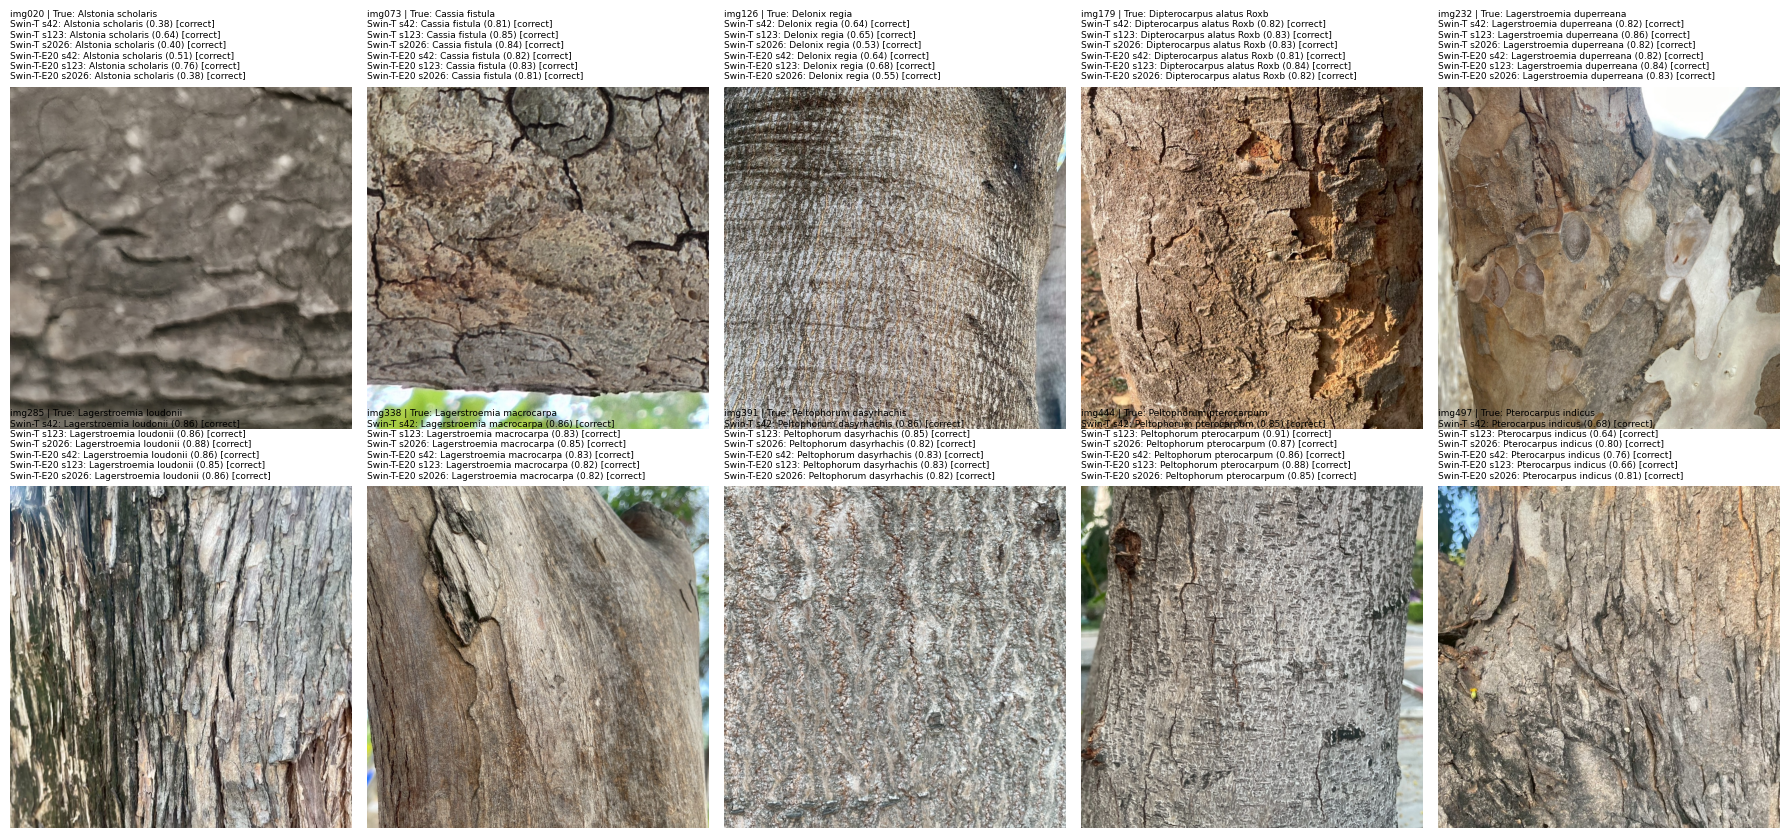

[PASS] STEP 10: /content/Bark_results_multiseed/sample_10


In [ ]:
RESULTS = scan_runs(verbose=False)
SAMPLE_DIR = RESULTS_DIR / 'sample_10'
if SAMPLE_DIR.exists():
    shutil.rmtree(SAMPLE_DIR)
(SAMPLE_DIR / 'images').mkdir(parents=True)

N_SAMPLES = 10
man = TEST_MANIFEST
picked = [man[man['true_label'] == c].sample(1, random_state=SPLIT_SEED).iloc[0]
          for c in sorted(man['true_label'].unique())][:N_SAMPLES]
rest = man[~man['image_id'].isin([r['image_id'] for r in picked])]
if len(picked) < N_SAMPLES:
    picked += [r for _, r in rest.sample(min(N_SAMPLES - len(picked), len(rest)), random_state=SPLIT_SEED).iterrows()]
sample = pd.DataFrame(picked).reset_index(drop=True)

rows_out = []
for _, r in sample.iterrows():
    src = DATASET_DIR / 'test' / r['true_label'] / r['file_name']
    shutil.copy2(src, SAMPLE_DIR / 'images' / f"{r['image_id']}_{r['file_name']}")
    row = {'Image ID': r['image_id'], 'file': r['file_name'], 'True Label': r['true_label']}
    for (tag, seed), R in RESULTS.items():
        m = R['pred_df'].set_index('image_id').loc[r['image_id']]
        row[f'{run_label(tag, seed)} pred'] = m['pred_class']
        row[f'{run_label(tag, seed)} correct'] = bool(m['correct'])
        row[f'{run_label(tag, seed)} conf'] = round(float(m['confidence']), 4)
    rows_out.append(row)
sample_summary = pd.DataFrame(rows_out)
sample_summary.to_csv(SAMPLE_DIR / 'sample_10_predictions.csv', index=False, encoding='utf-8-sig')
display(sample_summary)

ncols = 5; nrows = math.ceil(len(sample_summary) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 4.2 * nrows))
axes = np.array(axes).reshape(-1)
for ax, (_, r) in zip(axes, sample_summary.iterrows()):
    ax.imshow(Image.open(SAMPLE_DIR / 'images' / f"{r['Image ID']}_{r['file']}").convert('RGB')); ax.axis('off')
    lines = [f"{r['Image ID']} | True: {r['True Label']}"]
    for (tag, seed) in RESULTS:
        L = run_label(tag, seed)
        lines.append(f"{tag} s{seed}: {r[f'{L} pred']} ({r[f'{L} conf']:.2f}) [{'correct' if r[f'{L} correct'] else 'WRONG'}]")
    ax.set_title('\n'.join(lines), fontsize=6.5, loc='left')
for ax in axes[len(sample_summary):]:
    ax.axis('off')
fig.tight_layout()
fig.savefig(SAMPLE_DIR / 'sample_10_grid.png', dpi=200, bbox_inches='tight')
plt.show(); plt.close(fig)

if DRIVE_RESULTS_DIR is not None and DRIVE_ROOT.is_dir():
    try:
        shutil.copytree(SAMPLE_DIR, DRIVE_RESULTS_DIR / 'sample_10', dirs_exist_ok=True)
    except OSError as e:
        print(f'[WARNING] คัดลอกขึ้น Drive ไม่ได้: {e}')
print(f'[PASS] STEP 10: {SAMPLE_DIR}')

## STEP 11: Excel สรุปค่าสำคัญ — `Bark_key_results.xlsx`
ไฟล์เดียวสำหรับดู/รายงานผล (รันแยกได้ทุกเมื่อหลังเทรนเสร็จ ไม่ต้องเทรนใหม่ — อ่านจากผลใน `/content` หรือบน Drive)

| ชีต | เนื้อหา |
|---|---|
| **Summary** | Macro-F1 / Accuracy **Mean ± SD** ต่อสถาปัตยกรรม (สูตร AVERAGE / STDEV จากชีต Per seed) + ตารางพร้อมใส่รายงาน |
| Per seed | Macro-F1, Accuracy, Precision, Recall, AUC, MCC ของแต่ละ seed |
| Per-class F1 | F1 รายพันธุ์ 15 พันธุ์ ทุก seed + mean/SD |
| Confusion matrices | 15×15 ทุก (โมเดล, seed) + Recall รายพันธุ์ + Accuracy |
| McNemar | b, c, p-value, Holm, การแปลผล |
| Predictions 795 | Image ID, True Label, Prediction ทุก seed + คอลัมน์ถูก/ผิด |
| Hyperparameters | ค่าที่ใช้เทรน |

In [ ]:
# ===== STEP 11: Excel สรุปค่าสำคัญ (Bark_key_results.xlsx) — รันแยกได้ ไม่ต้องเทรนใหม่ =====
import re
from pathlib import Path
import pandas as pd
from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter
from openpyxl.formatting.rule import ColorScaleRule

# หาโฟลเดอร์ผลลัพธ์: ใน session นี้ -> บน Drive
_cands = [globals().get('RESULTS_DIR'), Path('/content/Bark_results_multiseed'),
          globals().get('DRIVE_RESULTS_DIR'), Path('/content/drive/MyDrive/Bark_results_multiseed')]
RES = next((Path(p) for p in _cands if p is not None and (Path(p) / '06_results_per_seed.csv').is_file()), None)
if RES is None:
    raise FileNotFoundError('ไม่พบ 06_results_per_seed.csv — รัน STEP 4-9 ก่อน หรือ mount Drive ที่มี Bark_results_multiseed')
print(f'อ่านผลจาก: {RES}')

rd = lambda name, **k: pd.read_csv(RES / name, encoding='utf-8-sig', **k)
seed_df = rd('06_results_per_seed.csv')
cls_df  = rd('05_per_class_f1.csv', index_col=0)
cm_df   = rd('10_confusion_matrices_all_runs.csv')
pred_df = rd('08_predictions_all_seeds.csv')
hp_df   = rd('03_hyperparameters.csv', index_col=0, keep_default_na=False)   # ไม่ให้ 'None' กลายเป็นช่องว่าง
mc_parts = [rd(f) for f in ['09_mcnemar_between_models.csv', '09c_mcnemar_between_models_unique.csv', '09b_mcnemar_between_seeds.csv'] if (RES / f).is_file()]
mc_df = pd.concat([m for m in mc_parts if len(m)], ignore_index=True) if any(len(m) for m in mc_parts) else pd.DataFrame()

# ใช้ค่าละเอียดเต็ม (ไม่ปัดเศษ) จาก runs/*/seed*/run_*.json เพื่อให้ Mean/SD ตรงกับ notebook ทุกหลัก
import json
_mkey = {'Macro-F1 (%)': 'macro_f1', 'Accuracy (%)': 'accuracy', 'Macro-Precision (%)': 'macro_precision',
         'Macro-Recall (%)': 'macro_recall', 'Weighted-F1 (%)': 'weighted_f1',
         'AUC OvR macro (%)': 'auc_ovr_macro', 'MCC (%)': 'mcc'}
for _p in (RES / 'runs').glob('*/seed*/run_*_seed*.json'):
    _r = json.load(open(_p, encoding='utf-8'))
    _m = (seed_df['Architecture'] == _r['tag']) & (seed_df['Seed'] == int(_r['seed']))
    for _col, _k in _mkey.items():
        if _col in seed_df.columns and _m.any() and _k in _r.get('test_metrics', {}):
            seed_df.loc[_m, _col] = _r['test_metrics'][_k] * 100

_order = ['ResNet', 'EfficientNet', 'EfficientNetV2-S', 'ConvNeXt', 'Swin-T', 'DeiT-S']
_ak = lambda t: (_order.index(t) if t in _order else 99, t)
seed_df = seed_df.sort_values(['Architecture', 'Seed'], key=lambda s: s.map(_ak) if s.name == 'Architecture' else s)
seed_df = seed_df.reset_index(drop=True)
archs = list(dict.fromkeys(seed_df['Architecture']))
class_names = list(cls_df.index)
runs = [(a, int(s)) for a, s in zip(seed_df['Architecture'], seed_df['Seed'])]

# ---------- สไตล์ ----------
F_BASE = 'Arial'
f_norm, f_bold = Font(name=F_BASE, size=10), Font(name=F_BASE, size=10, bold=True)
f_head = Font(name=F_BASE, size=10, bold=True, color='FFFFFF')
f_title, f_note = Font(name=F_BASE, size=13, bold=True), Font(name=F_BASE, size=9, italic=True, color='595959')
fill_head = PatternFill('solid', start_color='1F4E79')
fill_sub  = PatternFill('solid', start_color='DDEBF7')
fill_key  = PatternFill('solid', start_color='FFF2CC')
fill_diag = PatternFill('solid', start_color='C6EFCE')
thin = Side(style='thin', color='BFBFBF'); box = Border(left=thin, right=thin, top=thin, bottom=thin)
center = Alignment(horizontal='center', vertical='center', wrap_text=True)

def header(ws, row, col, labels, fill=fill_head, font=f_head):
    for j, lab in enumerate(labels):
        c = ws.cell(row=row, column=col + j, value=lab)
        c.font, c.fill, c.alignment, c.border = font, fill, center, box

def put(ws, row, col, val, fmt=None, font=f_norm, fill=None, align=None):
    c = ws.cell(row=row, column=col, value=val)
    c.font, c.border = font, box
    if fmt: c.number_format = fmt
    if fill: c.fill = fill
    if align: c.alignment = align
    return c

def widths(ws, w):
    for i, x in enumerate(w, start=1):
        ws.column_dimensions[get_column_letter(i)].width = x

def note(ws, row, text, col=1):
    c = ws.cell(row=row, column=col, value=text); c.font = f_note

wb = Workbook()

# ================= Sheet: Per seed =================
ws_s = wb.active; ws_s.title = 'Per seed'
ws_s['A1'] = 'ผลราย seed บน Test set (795 ภาพ)'; ws_s['A1'].font = f_title
cols_s = ['Architecture', 'Seed', 'Macro-F1 (%)', 'Accuracy (%)', 'Macro-Precision (%)', 'Macro-Recall (%)',
          'AUC OvR macro (%)', 'MCC (%)', 'Best epoch', 'Epochs run', 'Training time (min)']
cols_s = [c for c in cols_s if c in seed_df.columns]
header(ws_s, 3, 1, cols_s)
arch_rows = {}
for i, r in seed_df.iterrows():
    row = 4 + i
    arch_rows.setdefault(r['Architecture'], []).append(row)
    for j, c in enumerate(cols_s, start=1):
        v = r[c]
        v = int(v) if c in ('Seed', 'Best epoch', 'Epochs run') else v
        fmt = '0' if c in ('Seed', 'Best epoch', 'Epochs run') else '0.00'
        put(ws_s, row, j, v, fmt, fill=fill_key if c in ('Macro-F1 (%)', 'Accuracy (%)') else None,
            align=Alignment(horizontal='center') if j > 1 else None)
last_s = 4 + len(seed_df) - 1
note(ws_s, last_s + 2, f'ที่มา: {RES.name}/06_results_per_seed.csv (คำนวณจาก Test set ใน notebook) — ช่องสีเหลือง = ค่าที่ใช้ในตารางสรุป')
widths(ws_s, [14, 8, 13, 13, 15, 15, 15, 10, 10, 10, 14])
ws_s.freeze_panes = 'C4'
col_of = {c: get_column_letter(j) for j, c in enumerate(cols_s, start=1)}

# ================= Sheet: Summary (Mean ± SD) — สูตรอ้างอิง Per seed =================
ws = wb.create_sheet('Summary', 0)
ws['A1'] = 'สรุปผล Macro-F1 และ Accuracy (Mean ± SD จาก 3 seeds)'; ws['A1'].font = f_title
ws['A2'] = 'Mean = ค่าเฉลี่ย, SD = sample standard deviation (หาร N − 1) — คำนวณด้วยสูตรจากชีต "Per seed"'; ws['A2'].font = f_note
cols_m = ['Architecture', 'N seeds', 'Seeds', 'Macro-F1 Mean (%)', 'Macro-F1 SD (%)', 'Macro-F1 (%) Mean ± SD',
          'Accuracy Mean (%)', 'Accuracy SD (%)', 'Accuracy (%) Mean ± SD']
header(ws, 4, 1, cols_m)
for i, a in enumerate(archs):
    row = 5 + i
    rws = arch_rows[a]; r0, r1 = min(rws), max(rws)
    seeds_txt = ', '.join(str(int(s)) for s in seed_df.loc[seed_df['Architecture'] == a, 'Seed'])
    cF, cA = col_of['Macro-F1 (%)'], col_of['Accuracy (%)']   # ห้ามใช้ชื่อ F (ชนกับ torch.nn.functional)
    put(ws, row, 1, a, font=f_bold)
    put(ws, row, 2, f"=COUNT('Per seed'!B{r0}:B{r1})", '0', align=center)
    put(ws, row, 3, seeds_txt, align=center)
    put(ws, row, 4, f"=AVERAGE('Per seed'!{cF}{r0}:{cF}{r1})", '0.00', align=center)
    put(ws, row, 5, f"=IF(B{row}>1,STDEV('Per seed'!{cF}{r0}:{cF}{r1}),\"-\")", '0.00', align=center)
    put(ws, row, 6, f'=TEXT(D{row},"0.00")&" ± "&IF(B{row}>1,TEXT(E{row},"0.00"),"-")', fill=fill_key, font=f_bold, align=center)
    put(ws, row, 7, f"=AVERAGE('Per seed'!{cA}{r0}:{cA}{r1})", '0.00', align=center)
    put(ws, row, 8, f"=IF(B{row}>1,STDEV('Per seed'!{cA}{r0}:{cA}{r1}),\"-\")", '0.00', align=center)
    put(ws, row, 9, f'=TEXT(G{row},"0.00")&" ± "&IF(B{row}>1,TEXT(H{row},"0.00"),"-")', fill=fill_key, font=f_bold, align=center)
r = 5 + len(archs) + 1
ws.cell(row=r, column=1, value='ตารางสำหรับรายงาน').font = f_bold
header(ws, r + 1, 1, ['Architecture', 'Macro-F1 (%)', 'Accuracy (%)'])
for i, a in enumerate(archs):
    put(ws, r + 2 + i, 1, f'=A{5 + i}', font=f_bold)
    put(ws, r + 2 + i, 2, f'=F{5 + i}', align=center)
    put(ws, r + 2 + i, 3, f'=I{5 + i}', align=center)
widths(ws, [16, 9, 16, 15, 14, 20, 15, 14, 20])

# ================= Sheet: Per-class F1 =================
ws_c = wb.create_sheet('Per-class F1')
ws_c['A1'] = 'F1-score รายพันธุ์ บน Test set (53 ภาพ/พันธุ์)'; ws_c['A1'].font = f_title
run_cols = [c for c in cls_df.columns if not (c.endswith(' mean') or c.endswith(' SD'))]
head = ['Class'] + run_cols
for a in archs:
    head += [f'{a} mean', f'{a} SD']
header(ws_c, 3, 1, head)
for i, cname in enumerate(class_names):
    row = 4 + i
    put(ws_c, row, 1, cname)
    for j, rc in enumerate(run_cols, start=2):
        put(ws_c, row, j, float(cls_df.loc[cname, rc]), '0.0000', align=center)
    col = 2 + len(run_cols)
    for a in archs:
        idx = [2 + k for k, rc in enumerate(run_cols) if rc.startswith(f'{a} (seed')]
        rng = f'{get_column_letter(min(idx))}{row}:{get_column_letter(max(idx))}{row}'
        put(ws_c, row, col, f'=AVERAGE({rng})', '0.0000', font=f_bold, align=center)
        put(ws_c, row, col + 1, f'=IF(COUNT({rng})>1,STDEV({rng}),"-")', '0.0000', align=center)
        col += 2
last_c = 3 + len(class_names)
ws_c.conditional_formatting.add(f'B4:{get_column_letter(1 + len(run_cols))}{last_c}',
    ColorScaleRule(start_type='min', start_color='F8696B', mid_type='percentile', mid_value=50,
                   mid_color='FFEB84', end_type='max', end_color='63BE7B'))
widths(ws_c, [28] + [17] * (len(head) - 1))
ws_c.freeze_panes = 'B4'

# ================= Sheet: Confusion matrices =================
ws_cm = wb.create_sheet('Confusion matrices')
ws_cm['A1'] = 'Confusion Matrix บน Test set — แถว = True class, คอลัมน์ = Predicted class'; ws_cm['A1'].font = f_title
row = 3
n = len(class_names)
for (a, s) in runs:
    sub = cm_df[(cm_df['model'] == a) & (cm_df['seed'] == s)]
    mat = sub.pivot(index='true_class', columns='pred_class', values='count').reindex(index=class_names, columns=class_names)
    ws_cm.cell(row=row, column=1, value=f'{a} (seed {s})').font = Font(name=F_BASE, size=11, bold=True)
    header(ws_cm, row + 1, 1, ['True \\ Pred'] + class_names + ['Total', 'Correct', 'Recall (%)'])
    for i, tc in enumerate(class_names):
        rr = row + 2 + i
        put(ws_cm, rr, 1, tc, font=f_bold, fill=fill_sub)
        for j, pc in enumerate(class_names):
            v = int(mat.loc[tc, pc])
            put(ws_cm, rr, 2 + j, v, '0;-0;""', fill=fill_diag if i == j else None, align=center,
                font=f_bold if i == j else f_norm)
        L0, L1, D = get_column_letter(2), get_column_letter(1 + n), get_column_letter(2 + i)
        put(ws_cm, rr, 2 + n, f'=SUM({L0}{rr}:{L1}{rr})', '0', align=center)
        put(ws_cm, rr, 3 + n, f'={D}{rr}', '0', align=center)
        put(ws_cm, rr, 4 + n, f'=IF({get_column_letter(2 + n)}{rr}=0,"-",{get_column_letter(3 + n)}{rr}/{get_column_letter(2 + n)}{rr}*100)', '0.00', align=center)
    tr = row + 2 + n
    put(ws_cm, tr, 1, 'Total', font=f_bold, fill=fill_sub)
    for j in range(n + 2):
        L = get_column_letter(2 + j)
        put(ws_cm, tr, 2 + j, f'=SUM({L}{row + 2}:{L}{tr - 1})', '0', font=f_bold, align=center)
    TotC, CorC = get_column_letter(2 + n), get_column_letter(3 + n)
    put(ws_cm, tr, 4 + n, f'=IF({TotC}{tr}=0,"-",{CorC}{tr}/{TotC}{tr}*100)', '0.00', font=f_bold, fill=fill_key, align=center)
    note(ws_cm, tr + 1, 'Recall ของแถว Total = Accuracy (%)')
    row = tr + 3
widths(ws_cm, [26] + [9] * n + [8, 8, 10])
for j in range(n):
    ws_cm.cell(row=4, column=2 + j).alignment = Alignment(text_rotation=90, horizontal='center')

# ================= Sheet: McNemar =================
ws_mc = wb.create_sheet('McNemar')
ws_mc['A1'] = "McNemar's test (paired, Test set เดียวกัน)"; ws_mc['A1'].font = f_title
ws_mc['A2'] = ('H0: สองโมเดลผิดในสัดส่วนเท่ากัน | b = A ถูก/B ผิด, c = A ผิด/B ถูก | '
               'b+c < 25 ใช้ exact binomial, ไม่งั้นใช้ chi-square (continuity correction) | α = 0.05'); ws_mc['A2'].font = f_note
cols_mc = ['Comparison', 'Group', 'Model A', 'Seed A', 'Model B', 'Seed B', 'n', 'A correct / B wrong (b)',
           'A wrong / B correct (c)', 'Accuracy A (%)', 'Accuracy B (%)', 'Test used', 'Statistic', 'p-value',
           'p (Holm)', 'Significant (α=0.05)', 'Interpretation']
header(ws_mc, 4, 1, cols_mc)
if len(mc_df):
    for i, rr in mc_df.reset_index(drop=True).iterrows():
        for j, c in enumerate(cols_mc, start=1):
            v = rr.get(c, '')
            if isinstance(v, float) and pd.isna(v): v = ''
            if c in ('Seed A', 'Seed B', 'n', 'A correct / B wrong (b)', 'A wrong / B correct (c)'): v = int(v)
            if c == 'Significant (α=0.05)': v = 'Yes' if str(v) in ('True', '1', 'Yes') else 'No'
            fmt = '0.0000' if c in ('p-value', 'p (Holm)') else ('0.00' if c in ('Accuracy A (%)', 'Accuracy B (%)') else None)
            put(ws_mc, 5 + i, j, v, fmt, fill=fill_key if c == 'p-value' else None)
    note(ws_mc, 6 + len(mc_df), 'ระหว่างโมเดล = เทียบที่ seed เดียวกัน (หลัก) | ระหว่าง seed = เทียบ seed ต่างกันของโมเดลเดียวกัน (เสริม)')
else:
    note(ws_mc, 5, 'ยังไม่มีคู่ให้เทียบ')
if not any(mc_df.get('Comparison', pd.Series(dtype=str)).astype(str).str.startswith('between models')):
    note(ws_mc, 8 + len(mc_df), 'หมายเหตุ: ตอนนี้มีโมเดลเดียว จึงยังไม่มีการเทียบระหว่างโมเดล — จะมีเมื่อรันโมเดลอื่นเพิ่ม')
widths(ws_mc, [24, 12, 11, 8, 11, 8, 6, 12, 12, 11, 11, 20, 10, 10, 10, 11, 42])

# ================= Sheet: Predictions (795 ภาพ) =================
ws_p = wb.create_sheet('Predictions 795')
pcols = list(pred_df.columns)
header(ws_p, 1, 1, pcols + [f'Correct: {c.replace(" Prediction", "")}' for c in pcols[2:]])
for i, rr in enumerate(pred_df.itertuples(index=False), start=2):
    for j, v in enumerate(rr, start=1):
        ws_p.cell(row=i, column=j, value=v).font = f_norm
    for k in range(len(pcols) - 2):
        L = get_column_letter(3 + k)
        c = ws_p.cell(row=i, column=len(pcols) + 1 + k, value=f'=IF({L}{i}=$B{i},1,0)')
        c.font, c.alignment = f_norm, Alignment(horizontal='center')
last_p = 1 + len(pred_df)
tot = last_p + 2
ws_p.cell(row=tot, column=1, value='Accuracy (%)').font = f_bold
for k in range(len(pcols) - 2):
    L = get_column_letter(len(pcols) + 1 + k)
    c = ws_p.cell(row=tot, column=len(pcols) + 1 + k, value=f'=AVERAGE({L}2:{L}{last_p})*100')
    c.font, c.number_format, c.fill = f_bold, '0.00', fill_key
ws_p.freeze_panes = 'C2'
ws_p.auto_filter.ref = f'A1:{get_column_letter(len(pcols))}{last_p}'
widths(ws_p, [10, 26] + [26] * (len(pcols) - 2) + [14] * (len(pcols) - 2))

# ================= Sheet: Hyperparameters =================
ws_h = wb.create_sheet('Hyperparameters')
header(ws_h, 1, 1, ['Hyperparameter'] + list(hp_df.columns))
for i, (k, rr) in enumerate(hp_df.iterrows(), start=2):
    put(ws_h, i, 1, k, font=f_bold, fill=fill_sub)
    for j, v in enumerate(rr, start=2):
        if isinstance(v, str) and re.fullmatch(r'-?\d+(\.\d+)?(e-?\d+)?', v): v = float(v) if any(ch in v for ch in '.e') else int(v)
        put(ws_h, i, j, v)
widths(ws_h, [30] + [42] * len(hp_df.columns))

# ================= Training setup (03b) / Fine-tune check (03c) / Rerun (13) =================
def df_sheet(title, df, note_text=None, index=True, width=None):
    ws_x = wb.create_sheet(title)
    d = df.reset_index() if index else df
    header(ws_x, 1, 1, [str(c) for c in d.columns])
    for i, rr in enumerate(d.itertuples(index=False), start=2):
        for j, v in enumerate(rr, start=1):
            v = '' if (isinstance(v, float) and pd.isna(v)) else v
            put(ws_x, i, j, v, font=f_bold if (j == 1 and index) else f_norm,
                align=Alignment(wrap_text=True, vertical='top'))
    if note_text:
        note(ws_x, len(d) + 3, note_text)
    widths(ws_x, width or ([34] + [60] * (len(d.columns) - 1)))
    ws_x.freeze_panes = 'B2'
    return ws_x

if (RES / '03b_training_setup.csv').is_file():
    df_sheet('Training setup', rd('03b_training_setup.csv', index_col=0),
             'ทุก seed ใช้ค่าเดียวกัน | ขนาดภาพ/patch ก่อนเทรนมาจาก bark_dataset_prep | ขนาดไฟล์วัดจากไฟล์จริง')
if (RES / '03c_finetune_check.csv').is_file():
    df_sheet('Fine-tune check', rd('03c_finetune_check.csv', index_col=0),
             'ตรวจจากโมเดลจริง: trainable = total → ไม่มีการ freeze; pretrained_tensors_loaded = จำนวน tensor ที่ตรงกับ weight ImageNet-1k ทุกค่า',
             width=[12] + [26] * 9)
if (RES / '13_rerun_comparison.csv').is_file():
    ws_rr = df_sheet('Rerun check', rd('13_rerun_comparison.csv'), index=False, width=[10, 8, 26, 14, 18, 12])
    r0 = ws_rr.max_row + 3
    if (RES / '13_rerun_mcnemar.csv').is_file():
        mcr = rd('13_rerun_mcnemar.csv')
        header(ws_rr, r0, 1, list(mcr.columns))
        for i, rr in enumerate(mcr.itertuples(index=False), start=r0 + 1):
            for j, v in enumerate(rr, start=1):
                put(ws_rr, i, j, v, '0.0000' if mcr.columns[j - 1] == 'p-value' else None)
    note(ws_rr, ws_rr.max_row + 2, 'ผลหลักทุกตารางใช้รอบเดิม — ชีตนี้คือการรันซ้ำ seed เดิมเพื่อตรวจว่าผลทำซ้ำได้')

# ================= README =================
ws_r = wb.create_sheet('README', 1)
ws_r['A1'] = 'Bark Classification — ผลสำคัญ'; ws_r['A1'].font = f_title
info = [
    ('Summary', 'ตารางสรุป Macro-F1 / Accuracy แบบ Mean ± SD ต่อสถาปัตยกรรม (สูตรอ้างอิงชีต Per seed)'),
    ('Per seed', 'Macro-F1, Accuracy, Precision, Recall, AUC, MCC ของแต่ละ seed'),
    ('Per-class F1', 'F1 รายพันธุ์ทั้ง 15 พันธุ์ ทุก seed + ค่าเฉลี่ย/SD'),
    ('Confusion matrices', 'Confusion matrix 15×15 ของทุก (โมเดล, seed) พร้อม Recall รายพันธุ์ และ Accuracy'),
    ('McNemar', "ผล McNemar's test (b, c, p-value, Holm, การแปลผล)"),
    ('Predictions 795', 'ผลทำนายรายภาพ: Image ID | True Label | Prediction ของทุกโมเดล/seed (ข้อมูลดิบของ McNemar)'),
    ('Hyperparameters', 'ค่าที่ใช้เทรนแต่ละรอบ'),
    ('Training setup', 'Learning rate, batch size, loss, data augmentation, ขนาดภาพ/patch, วิธี fine-tune (ต่อโมเดล)'),
    ('Fine-tune check', 'ผลตรวจจริง: parameter ที่เทรนได้ / freeze / weight pretrained ที่โหลด'),
    ('Rerun check', 'เทียบผลรอบเดิมกับการรันซ้ำ seed เดิม (เช่น Swin-T seed 123)'),
]
header(ws_r, 3, 1, ['ชีต', 'เนื้อหา'])
for i, (a, b) in enumerate(info, start=4):
    put(ws_r, i, 1, a, font=f_bold); put(ws_r, i, 2, b)
note(ws_r, 5 + len(info), f'ที่มา: ไฟล์ CSV ใน {RES} (สร้างโดย notebook Bark_SwinT_MultiSeed) — ทุกตัวเลขมาจากการรันจริง')
note(ws_r, 6 + len(info), f'Test set = {len(pred_df)} ภาพ | โมเดล/seed: ' + ', '.join(f'{a} s{s}' for a, s in runs))
widths(ws_r, [20, 95])

KEY_XLSX = RES / 'Bark_key_results.xlsx'
wb.save(KEY_XLSX)
print(f'[PASS] STEP 11: บันทึก {KEY_XLSX}')
try:
    _dr = globals().get('DRIVE_RESULTS_DIR') or Path('/content/drive/MyDrive/Bark_results_multiseed')
    if Path(_dr).is_dir() and Path(_dr).resolve() != RES.resolve():
        import shutil; shutil.copy2(KEY_XLSX, Path(_dr) / KEY_XLSX.name); print(f'[INFO] คัดลอกขึ้น Drive: {_dr}')
except OSError as e:
    print(f'[WARNING] คัดลอกขึ้น Drive ไม่ได้: {e}')
if 'google.colab' in __import__('sys').modules:
    from google.colab import files; files.download(str(KEY_XLSX))

อ่านผลจาก: /content/Bark_results_multiseed
[PASS] STEP 11: บันทึก /content/Bark_results_multiseed/Bark_key_results.xlsx
[INFO] คัดลอกขึ้น Drive: /content/drive/MyDrive/Bark_results_multiseed


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## STEP 12: ตาราง Precision / Recall / F1-score รายพันธุ์ (รูปแบบตารางในเล่ม)
No | Scientific Name (ชื่อเต็มพร้อมผู้ตั้งชื่อ, ชื่อสกุล+ชนิดตัวเอียง) | Precision | Recall | F1-score — ทศนิยม 3 ตำแหน่ง, ค่า < 0.80 ตัวหนา
- ชีต `<โมเดล> s<seed>` = ตารางของแต่ละ seed (+ Macro average, Accuracy)
- ชีต `<โมเดล> mean±SD` = ค่าเฉลี่ย ± SD ของ 3 seeds (สูตรอ้างอิงชีตราย seed)
- บันทึก `Bark_per_class_tables.xlsx` และ CSV `12_per_class_table_*.csv`

In [ ]:
# ===== STEP 12: ตาราง Precision / Recall / F1 รายพันธุ์ (รูปแบบตารางในเล่ม) — รันแยกได้ ไม่ต้องเทรนใหม่ =====
import json
from pathlib import Path
import numpy as np, pandas as pd
from openpyxl import Workbook
from openpyxl.styles import Font, Alignment, Border, Side, PatternFill
from openpyxl.cell.rich_text import CellRichText, TextBlock
from openpyxl.cell.text import InlineFont

RES = next((Path(p) for p in [globals().get('RESULTS_DIR'), '/content/Bark_results_multiseed',
                              '/content/drive/MyDrive/Bark_results_multiseed']
            if p is not None and (Path(p) / 'runs').is_dir()), None)
assert RES is not None, 'ไม่พบโฟลเดอร์ผลลัพธ์ - รัน STEP 4 ก่อน หรือ mount Drive'

# ชื่อวิทยาศาสตร์เต็ม (ชื่อสกุล+ชนิด, ผู้ตั้งชื่อ) เรียงตาม label 0..14
SCI_NAMES = {
    'Alstonia scholaris':         ('Alstonia scholaris', '(L.) R.Br.'),
    'Cassia fistula':             ('Cassia fistula', 'L.'),
    'Delonix regia':              ('Delonix regia', '(Bojer ex Hook.) Raf.'),
    'Dipterocarpus alatus Roxb':  ('Dipterocarpus alatus', 'Roxb. ex G.Don'),
    'Lagerstroemia duperreana':   ('Lagerstroemia duperreana', 'Pierre ex Gagnep.'),
    'Lagerstroemia loudonii':     ('Lagerstroemia loudonii', 'Teijsm. & Binn.'),
    'Lagerstroemia macrocarpa':   ('Lagerstroemia macrocarpa', 'Kurz'),
    'Peltophorum dasyrhachis':    ('Peltophorum dasyrhachis', '(Miq.) Kurz'),
    'Peltophorum pterocarpum':    ('Peltophorum pterocarpum', '(DC.) Backer ex K.Heyne'),
    'Pterocarpus indicus':        ('Pterocarpus indicus', 'Willd.'),
    'Pterocarpus macrocarpus':    ('Pterocarpus macrocarpus', 'Kurz'),
    'Streblus asper':             ('Streblus asper', 'Lour.'),
    'Swietenia macrophylla':      ('Swietenia macrophylla', 'King'),
    'Tectona grandis':            ('Tectona grandis', 'L.f.'),
    'Triplaris cumingiana Fisch': ('Triplaris cumingiana', 'Fisch. & C.A.Mey.'),
}
CLASSES = list(SCI_NAMES)
BOLD_BELOW = 0.80   # ทำตัวหนาค่าที่ต่ำกว่า 0.80 (แก้ได้)
DEC = 3             # ทศนิยม 3 ตำแหน่ง ตามตัวอย่าง

ORDER = ['ResNet', 'EfficientNet', 'EfficientNetV2-S', 'ConvNeXt', 'Swin-T', 'DeiT-S']
runs = []
for p in (RES / 'runs').glob('*/seed*/run_*_seed*.json'):
    r = json.load(open(p, encoding='utf-8'))
    rep = p.parent / f"classification_report_{r['tag']}_seed{r['seed']}.csv"
    if rep.is_file():
        runs.append((r['tag'], int(r['seed']), pd.read_csv(rep, index_col=0, encoding='utf-8-sig')))
runs.sort(key=lambda x: (ORDER.index(x[0]) if x[0] in ORDER else 99, x[0], x[1]))
assert runs, f'ไม่พบ classification_report ใน {RES / "runs"}'
print('พบผล:', ', '.join(f'{t} seed {s}' for t, s, _ in runs))

def table_of(rep):
    t = rep.loc[CLASSES, ['precision', 'recall', 'f1-score']].astype(float)
    t.columns = ['Precision', 'Recall', 'F1-score']
    return t

# ---------- CSV ----------
for tag, seed, rep in runs:
    t = table_of(rep).round(DEC)
    t.insert(0, 'Scientific Name', [' '.join(SCI_NAMES[c]) for c in CLASSES])
    t.insert(0, 'No', range(1, len(CLASSES) + 1))
    t.loc[len(t) + 1] = ['', 'Macro average', *[round(float(rep.loc['macro avg', k]), DEC) for k in ['precision', 'recall', 'f1-score']]]
    t.loc[len(t) + 1] = ['', 'Accuracy', '', '', round(float(rep.loc['accuracy'].iloc[0]), DEC)]
    t.to_csv(RES / f'12_per_class_table_{tag}_seed{seed}.csv', index=False, encoding='utf-8-sig')
for tag in dict.fromkeys(t for t, _, _ in runs):
    tabs = [table_of(rep) for t, _, rep in runs if t == tag]
    st = np.stack([x.to_numpy() for x in tabs])
    mu, sd = st.mean(0), (st.std(0, ddof=1) if len(tabs) > 1 else np.full(st.shape[1:], np.nan))
    out = pd.DataFrame({'No': range(1, len(CLASSES) + 1), 'Scientific Name': [' '.join(SCI_NAMES[c]) for c in CLASSES]})
    for j, k in enumerate(['Precision', 'Recall', 'F1-score']):
        out[k] = [f'{m:.{DEC}f} ± {s:.{DEC}f}' for m, s in zip(mu[:, j], sd[:, j])]
    out.to_csv(RES / f'12_per_class_table_{tag}_mean_sd.csv', index=False, encoding='utf-8-sig')

# ---------- Excel (ชื่อสกุล+ชนิดเป็นตัวเอียง, ค่า < 0.80 ตัวหนา) ----------
FN = 'Times New Roman'
f_n, f_b, f_t = Font(name=FN, size=11), Font(name=FN, size=11, bold=True), Font(name=FN, size=12, bold=True)
thin = Side(style='thin', color='000000'); box = Border(left=thin, right=thin, top=thin, bottom=thin)
ctr = Alignment(horizontal='center', vertical='center', wrap_text=True)
lft = Alignment(horizontal='left', vertical='center', wrap_text=True)
fill_h = PatternFill('solid', start_color='F2F2F2')
NUM = '0.' + '0' * DEC

def sci_cell(ws, row, col, cname):
    g, a = SCI_NAMES[cname]
    c = ws.cell(row=row, column=col)
    c.value = CellRichText(TextBlock(InlineFont(rFont=FN, sz=11, i=True), g), TextBlock(InlineFont(rFont=FN, sz=11, i=False), f' {a}'))
    c.font = f_n
    c.alignment, c.border = lft, box

def head(ws, row, labels):
    for j, h in enumerate(labels, start=1):
        c = ws.cell(row=row, column=j, value=h); c.font, c.alignment, c.border, c.fill = f_b, ctr, box, fill_h

def setw(ws, w):
    for j, x in enumerate(w, start=1):
        ws.column_dimensions[chr(64 + j)].width = x

wb = Workbook(); wb.remove(wb.active)
FIRST, sheet_of = 3, {}
for tag, seed, rep in runs:
    name = f'{tag} s{seed}'[:31]; sheet_of[(tag, seed)] = name
    ws = wb.create_sheet(name)
    ws['A1'] = f'Per-class performance of {tag} (seed {seed}) on the test set'; ws['A1'].font = f_t
    head(ws, 2, ['No', 'Scientific Name', 'Precision', 'Recall', 'F1-score'])
    t = table_of(rep)
    for i, cname in enumerate(CLASSES):
        r = FIRST + i
        c = ws.cell(row=r, column=1, value=i + 1); c.font, c.alignment, c.border = f_n, ctr, box
        sci_cell(ws, r, 2, cname)
        for j, k in enumerate(['Precision', 'Recall', 'F1-score'], start=3):
            v = float(t.loc[cname, k])                      # เก็บค่าเต็ม แสดงผล 3 ตำแหน่ง
            c = ws.cell(row=r, column=j, value=v)
            c.number_format, c.alignment, c.border = NUM, ctr, box
            c.font = f_b if round(v, DEC) < BOLD_BELOW else f_n
    r = FIRST + len(CLASSES)
    ws.cell(row=r, column=2, value='Macro average')
    for j, k in enumerate(['precision', 'recall', 'f1-score'], start=3):
        ws.cell(row=r, column=j, value=float(rep.loc['macro avg', k])).number_format = NUM
    ws.cell(row=r + 1, column=2, value='Accuracy')
    ws.cell(row=r + 1, column=5, value=float(rep.loc['accuracy'].iloc[0])).number_format = NUM
    for rr in (r, r + 1):
        for j in range(1, 6):
            c = ws.cell(row=rr, column=j); c.font, c.border = f_b, box
            c.alignment = lft if j == 2 else ctr
    ws.cell(row=r + 3, column=1, value=f'ค่าที่ต่ำกว่า {BOLD_BELOW:.2f} แสดงเป็นตัวหนา | Test set = '
            f'{int(rep.loc["macro avg", "support"])} ภาพ | ที่มา: classification_report_{tag}_seed{seed}.csv').font = Font(name=FN, size=9, italic=True)
    setw(ws, [5, 34, 11, 11, 11])

# Mean ± SD ต่อโมเดล (สูตร AVERAGE / STDEV อ้างอิงชีตราย seed)
for tag in dict.fromkeys(t for t, _, _ in runs):
    shs = [sheet_of[(t, s)] for t, s, _ in runs if t == tag]
    ws = wb.create_sheet(f'{tag} mean±SD'[:31], 0)
    ws['A1'] = f'Per-class performance of {tag} on the test set (mean ± SD of {len(shs)} seeds)'; ws['A1'].font = f_t
    head(ws, 2, ['No', 'Scientific Name', 'Precision', 'Recall', 'F1-score',
                 'Precision mean', 'Precision SD', 'Recall mean', 'Recall SD', 'F1 mean', 'F1 SD'])
    rows = list(range(FIRST, FIRST + len(CLASSES) + 1))   # + Macro average
    for i, r in enumerate(rows):
        c = ws.cell(row=r, column=1, value=(i + 1) if i < len(CLASSES) else ''); c.font, c.alignment, c.border = f_n, ctr, box
        if i < len(CLASSES):
            sci_cell(ws, r, 2, CLASSES[i])
        else:
            c = ws.cell(row=r, column=2, value='Macro average'); c.font, c.border, c.alignment = f_b, box, lft
        for j, L in enumerate(['C', 'D', 'E']):
            refs = ','.join(f"'{s}'!{L}{r}" for s in shs)
            mcol, scol = 6 + 2 * j, 7 + 2 * j
            cm = ws.cell(row=r, column=mcol, value=f'=AVERAGE({refs})')
            cs = ws.cell(row=r, column=scol, value=f'=STDEV({refs})' if len(shs) > 1 else '-')
            for c in (cm, cs):
                c.number_format, c.alignment, c.border, c.font = NUM, ctr, box, f_n
            M, S = cm.column_letter, cs.column_letter
            ct = ws.cell(row=r, column=3 + j,
                         value=f'=TEXT({M}{r},"{NUM}")&" ± "&' + (f'TEXT({S}{r},"{NUM}")' if len(shs) > 1 else '"-"'))
            ct.alignment, ct.border = ctr, box
            ct.font = f_b if i == len(CLASSES) else f_n
    ws.cell(row=rows[-1] + 2, column=1, value='คอลัมน์ C–E = ค่าสำหรับวางในเล่ม (mean ± SD, sample SD หาร N−1) | '
            'คอลัมน์ F–K = ค่าตัวเลขที่ใช้คำนวณ (สูตรอ้างอิงชีตราย seed)').font = Font(name=FN, size=9, italic=True)
    setw(ws, [5, 34, 17, 17, 17, 11, 11, 11, 11, 11, 11])

XL = RES / 'Bark_per_class_tables.xlsx'
wb.save(XL)
print(f'[PASS] STEP 12: {XL}')
print('  CSV: 12_per_class_table_<model>_seed<seed>.csv และ 12_per_class_table_<model>_mean_sd.csv')
for tag in dict.fromkeys(t for t, _, _ in runs):
    print(f'\n{tag} — mean ± SD:'); print(pd.read_csv(RES / f'12_per_class_table_{tag}_mean_sd.csv', encoding='utf-8-sig').to_string(index=False))
try:
    _dr = Path('/content/drive/MyDrive/Bark_results_multiseed')
    if _dr.is_dir() and _dr.resolve() != RES.resolve():
        import shutil; shutil.copy2(XL, _dr / XL.name)
except OSError as e:
    print(f'[WARNING] คัดลอกขึ้น Drive ไม่ได้: {e}')
if 'google.colab' in __import__('sys').modules:
    from google.colab import files; files.download(str(XL))

พบผล: Swin-T seed 42, Swin-T seed 123, Swin-T seed 2026, Swin-T-E20 seed 42, Swin-T-E20 seed 123, Swin-T-E20 seed 2026
[PASS] STEP 12: /content/Bark_results_multiseed/Bark_per_class_tables.xlsx
  CSV: 12_per_class_table_<model>_seed<seed>.csv และ 12_per_class_table_<model>_mean_sd.csv

Swin-T — mean ± SD:
 No                                 Scientific Name     Precision        Recall      F1-score
  1                   Alstonia scholaris (L.) R.Br. 1.000 ± 0.000 0.579 ± 0.054 0.732 ± 0.043
  2                               Cassia fistula L. 1.000 ± 0.000 1.000 ± 0.000 1.000 ± 0.000
  3             Delonix regia (Bojer ex Hook.) Raf. 1.000 ± 0.000 1.000 ± 0.000 1.000 ± 0.000
  4             Dipterocarpus alatus Roxb. ex G.Don 1.000 ± 0.000 1.000 ± 0.000 1.000 ± 0.000
  5      Lagerstroemia duperreana Pierre ex Gagnep. 1.000 ± 0.000 0.981 ± 0.000 0.990 ± 0.000
  6          Lagerstroemia loudonii Teijsm. & Binn. 1.000 ± 0.000 1.000 ± 0.000 1.000 ± 0.000
  7                   Lagerstroemia

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## STEP 13: เทียบ Swin-T เดิม vs HP ใหม่ (Test set, n = 795)
ค่าเดิมกรอกจากผลรอบก่อนหน้า (HP เดิม) เทียบกับผลที่เพิ่งเทรนด้วย HP ใหม่ — cell นี้อ่านผลอย่างเดียว ไม่เทรนใหม่ ไม่แก้ผลหลัก รันแยกได้หลัง STEP 4


In [ ]:
# ===== STEP 13: เทียบ Swin-T เดิม vs HP ใหม่ (อ่านผลอย่างเดียว ไม่เทรนใหม่) =====
OLD_SWIN = {   # ผลรอบเดิม (Test set n = 795)
    42:   dict(accuracy=0.9044, macro_f1=0.8995, macro_precision=0.9271),
    123:  dict(accuracy=0.9472, macro_f1=0.9468, macro_precision=0.9565),
    2026: dict(accuracy=0.9296, macro_f1=0.9267, macro_precision=0.9445),
}
CMP_METRICS = [('accuracy', 'Accuracy'), ('macro_f1', 'Macro-F1'), ('macro_precision', 'Macro-Precision')]
CMP_TAG = 'Swin-T'

RESULTS = scan_runs(verbose=False)
seeds_ok = [s for s in OLD_SWIN if (CMP_TAG, s) in RESULTS]
assert seeds_ok, f'ยังไม่มีผล {CMP_TAG} ใหม่ — รัน STEP 4 ก่อน'
if len(seeds_ok) < len(OLD_SWIN):
    print(f'[WARNING] มีผลใหม่เฉพาะ seed {seeds_ok} — seed อื่นไม่ถูกนำมาเทียบ')

rows = []
for k, name in CMP_METRICS:
    row = {'Metric (Test set, n = 795)': name}
    for s in seeds_ok:
        old, new = OLD_SWIN[s][k], RESULTS[(CMP_TAG, s)]['run']['test_metrics'][k]
        row[f'seed {s} เดิม'], row[f'seed {s} ใหม่'], row[f'seed {s} ต่าง'] = old, new, new - old
    olds = [OLD_SWIN[s][k] for s in seeds_ok]
    news = [RESULTS[(CMP_TAG, s)]['run']['test_metrics'][k] for s in seeds_ok]
    row['Mean เดิม'], row['Mean ใหม่'] = np.mean(olds), np.mean(news)
    row['SD เดิม'], row['SD ใหม่'] = np.std(olds, ddof=1) if len(olds) > 1 else np.nan, np.std(news, ddof=1) if len(news) > 1 else np.nan
    row['Mean ต่าง'] = row['Mean ใหม่'] - row['Mean เดิม']
    rows.append(row)
df_cmp = pd.DataFrame(rows)
print(f'{CMP_TAG}: HP เดิม vs HP ใหม่ (ค่าต่าง = ใหม่ − เดิม)')
display(df_cmp.round(4))
df_cmp.round(4).to_csv(RESULTS_DIR / '14_swinT_old_vs_new_hp.csv', index=False, encoding='utf-8-sig')

# train / val / test ของรอบใหม่ — ดูว่า gap ลดลงหรือไม่ (train/val ของรอบเดิมไม่มีในที่นี้)
gap = []
for s in seeds_ok:
    R = RESULTS[(CMP_TAG, s)]; h = R['hist']; be = R['run']['best_epoch']
    if len(h):
        r = h[h['epoch'] == be].iloc[0]
        gap.append({'seed': s, 'best_epoch': be, 'train_acc': r['train_acc'], 'val_acc': r['val_acc'],
                    'test_acc': R['run']['test_metrics']['accuracy'], 'train_loss': r['train_loss'], 'val_loss': r['val_loss']})
if gap:
    print('\nรอบใหม่ ณ best epoch (train_loss มี label smoothing จึงไม่เทียบตรงกับ val_loss):')
    display(pd.DataFrame(gap).round(4))
print('\n[INFO] ถ้า Accuracy/Macro-F1 ใหม่ ≈ หรือสูงกว่าเดิม และ train_acc ใกล้ test_acc มากขึ้น แสดงว่า overfit ลดลง')
print('[INFO] ต้องรายงานผลตามจริงทั้งสองชุด HP ห้ามเลือกเฉพาะชุดที่ดูดีกว่า')


Swin-T: HP เดิม vs HP ใหม่ (ค่าต่าง = ใหม่ − เดิม)


,"Metric (Test set, n = 795)",seed 42 เดิม,seed 42 ใหม่,seed 42 ต่าง,seed 123 เดิม,seed 123 ใหม่,seed 123 ต่าง,seed 2026 เดิม,seed 2026 ใหม่,seed 2026 ต่าง,Mean เดิม,Mean ใหม่,SD เดิม,SD ใหม่,Mean ต่าง
0,Accuracy,0.9044,0.9258,0.0214,0.9472,0.9195,-0.0277,0.9296,0.9346,0.0050,0.9271,0.9266,0.0215,0.0076,-0.0004
1,Macro-F1,0.8995,0.9245,0.0250,0.9468,0.9175,-0.0293,0.9267,0.9326,0.0059,0.9243,0.9249,0.0237,0.0076,0.0005
2,Macro-Precision,0.9271,0.9414,0.0143,0.9565,0.9402,-0.0163,0.9445,0.9499,0.0054,0.9427,0.9438,0.0148,0.0053,0.0011



รอบใหม่ ณ best epoch (train_loss มี label smoothing จึงไม่เทียบตรงกับ val_loss):


,seed,best_epoch,train_acc,val_acc,test_acc,train_loss,val_loss
0,42,11,0.9989,1.0,0.9258,0.9943,0.1635
1,123,12,1.0000,1.0,0.9195,0.9919,0.1483
2,2026,13,0.9997,1.0,0.9346,0.9900,0.1589



[INFO] ถ้า Accuracy/Macro-F1 ใหม่ ≈ หรือสูงกว่าเดิม และ train_acc ใกล้ test_acc มากขึ้น แสดงว่า overfit ลดลง
[INFO] ต้องรายงานผลตามจริงทั้งสองชุด HP ห้ามเลือกเฉพาะชุดที่ดูดีกว่า


## หมายเหตุสำหรับเขียนบทวิธีวิจัย
- **Split:** stratified ต่อ class train 247 / valid 53 (จาก 300 ภาพ/พันธุ์) ด้วย seed 42 คงที่; patch จากภาพถ่ายใบเดียวกัน/ไฟล์ซ้ำอยู่ split เดียวกัน (`split_manifest.csv`)
- **Test set:** 795 ภาพ (15 class × 53) จาก `Bark_Test_53_Final` ไม่เคยใช้เทรนหรือเลือกโมเดล; Image ID ใน `test_manifest.csv`
- **Repeated runs:** แต่ละสถาปัตยกรรมเทรน 3 รอบด้วย seed 42, 123, 2026 โดยใช้ข้อมูลแบ่งชุดเดิมและ hyperparameter เดิม — seed ควบคุมการสุ่มค่าเริ่มต้นของ classification head, ลำดับ mini-batch และ stochastic depth
- **รายงานผล:** Macro-F1 และ Accuracy บน Test ต่อ seed และ Mean ± SD (sample SD, N − 1 = 2)
- **McNemar's test:** เปรียบเทียบผลทำนายรายภาพของ 2 โมเดลบน Test set เดียวกัน แยกตาม seed (exact binomial เมื่อ b + c < 25, ไม่งั้น χ² แบบ continuity correction), α = 0.05, Holm correction เมื่อเทียบหลายคู่
- Preprocessing: resize ทั้งภาพเป็น 224 × 224 (bicubic) + ImageNet normalization (ไม่ใช่ augmentation)
- **Fine-tuning:** full fine-tuning — ไม่ freeze ชั้นใด (trainable = total parameters), โหลด weight ImageNet-1k ครบทุกชั้น ยกเว้น classification head ที่สุ่มใหม่ (15 class) — ตรวจจริงใน STEP 8a (`03c_finetune_check.csv`); ใช้ learning rate แยก backbone 5e-5 / head 1e-3
- **Data augmentation ระหว่างเทรน:** ไม่มี — แต่ตอนเตรียมข้อมูล (bark_dataset_prep) ตัด dense patch 1000 × 1000 px stride 750 (overlap 25%) และหมุน 180° สำหรับพันธุ์ที่ patch ไม่ถึง 300 (`03b_training_setup.csv`)
- **รันซ้ำ:** Swin-T seed 123 รันซ้ำด้วยการตั้งค่าเดิม เพื่อยืนยันว่าผลทำซ้ำได้ (`13_rerun_*.csv`) — ตารางหลักใช้ผลรอบเดิม
- ผลบน GPU อาจต่างกันเล็กน้อยเมื่อรันซ้ำแม้ใช้ seed เดียวกัน (ธรรมชาติของการคำนวณบน GPU) — seed 42 จึงอาจไม่ตรงกับการรันเดิมทุกหลัก